# Chapter 1: Introduction

## 1.1 Background
Data science is the practice of turning raw data into decisions using statistics, programming and domain knowledge. Every project follows a lifecycle: define the problem, collect and clean data, explore it, build and evaluate models, and finally communicate and monitor the results.

The telecommunications industry is one of the most competitive and data-rich sectors. Customers can switch providers easily, and competitors constantly offer new plans. When a customer leaves a company, this is called **customer churn**.

## 1.2 What is customer churn?
Customer churn (also called attrition) is the loss of customers who stop using a company's services during a given period.

**Churn rate = (Customers lost in a period / Customers at the start of the period) × 100**

## 1.3 Why churn matters
- **Cost:** Acquiring a new customer typically costs much more than retaining an existing one.
- **Revenue:** Long-term customers generate stable, recurring revenue.
- **Competitive pressure:** High churn signals problems with price, service quality or customer experience.
- **Actionability:** If at-risk customers are identified early, the company can offer targeted incentives, better plans or support.

## 1.4 Role of data science
Machine learning can learn patterns from past customers (who stayed and who left) and then estimate the churn risk of current customers. This lets the business act *before* a customer leaves.

## 1.5 Overview of this project
This project follows the full data science lifecycle on the IBM *Telco Customer Churn* dataset:

1. Problem definition
2. Data collection and understanding
3. Data cleaning
4. Exploratory data analysis (EDA) and correlation analysis
5. Feature engineering and preprocessing
6. Model building
7. Model evaluation
8. Hyperparameter tuning
9. Interpretation of results
10. Deployment and monitoring plan
11. Reporting

## 1.6 Structure of the report
Chapter 2 defines the problem. Chapters 3–6 cover the data. Chapters 7–9 cover modelling and evaluation. Chapter 10 interprets the results, Chapter 11 discusses deployment and monitoring, and Chapter 12 concludes.

# Chapter 2: Problem Statement and Objectives

## 2.1 Business context
A fictional telecom company provides **home phone and internet services** to customers in California. Each quarter, some customers leave. Management wants to understand *why* customers leave and to identify *which current customers are likely to leave next*, so retention offers can be targeted instead of given to everyone.

## 2.2 Problem statement
> **To build a machine learning model that predicts whether a telecom customer will churn (leave the company), using the customer's demographic details, subscribed services and account/billing information, and to identify the key factors that drive churn so that the company can design targeted retention strategies.**

## 2.3 Type of problem
- **Learning type:** Supervised learning
- **Task:** Binary classification
- **Target variable:** `Churn` (Yes = customer left, No = customer stayed)
- **Input features:** 19 columns covering demographics, services and account information (`customerID` is only an identifier and is not used as a feature)

## 2.4 Objectives
**Primary objective**
- Develop and evaluate a classification model that predicts customer churn accurately, with special focus on correctly identifying customers who actually churn.

**Secondary objectives**
1. Understand the structure and quality of the dataset and clean it properly.
2. Perform exploratory data analysis to find patterns and **correlations** between customer attributes and churn.
3. Handle categorical variables, skewed distributions and **class imbalance** appropriately.
4. Build and compare multiple models (Logistic Regression, Decision Tree, Random Forest, Gradient Boosting).
5. Select suitable **evaluation metrics** for an imbalanced problem (Precision, Recall, F1-score, ROC-AUC) and justify why accuracy alone is misleading.
6. Identify the most important features influencing churn.
7. Propose a deployment and monitoring plan for using the model in practice.

## 2.5 Research questions
1. Which customer attributes are most strongly associated with churn?
2. Does contract type (month-to-month, one year, two year) affect churn?
3. How do tenure and monthly charges relate to churn?
4. Do additional services (tech support, online security, etc.) reduce churn?
5. Does the payment method relate to churn?
6. Which model gives the best balance between catching churners and avoiding false alarms?

## 2.6 Hypotheses (to be tested in EDA)
- **H1:** Customers with shorter tenure are more likely to churn.
- **H2:** Customers on month-to-month contracts churn more than those on long-term contracts.
- **H3:** Customers with higher monthly charges are more likely to churn.
- **H4:** Customers without tech support or online security churn more.

## 2.7 Scope and constraints
- The data is a **single-quarter snapshot** of one (fictional) company, so results may not generalise to other companies or periods.
- The project predicts churn only; it does not calculate the financial impact of retention campaigns.
- Only the variables in the dataset are used (no call-quality, complaint or competitor data).

## 2.8 Success criteria
| Aspect | Criterion |
|--------|-----------|
| Data | Clean dataset, with every quality issue documented and justified |
| Model | Beats a baseline (always predicting "No churn") on Recall, F1 and ROC-AUC |
| Insight | Clear, evidence-backed list of churn drivers |
| Report | Complete, well-organised, every step justified |

## 2.9 Why this problem is worth solving
Even a small reduction in churn can save significant revenue. A model that ranks customers by churn risk helps the retention team focus on the customers who matter most.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

In [ ]:
from google.colab import files
uploaded = files.upload()   # choose WA_Fn-UseC_-Telco-Customer-Churn.csv

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [ ]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


# Chapter 3: Dataset Description and Data Collection

## 3.1 Source of the Dataset
The dataset used is the **Telco Customer Churn** dataset, created by **IBM** as sample data for its Cognos Analytics platform and published on **Kaggle** (user: blastchar). It describes a fictional telecom company that provides home phone and internet services to customers in California. It is widely used for learning and research on customer retention.

## 3.2 Dataset Overview
| Property | Value |
|---|---|
| File name | WA_Fn-UseC_-Telco-Customer-Churn.csv |
| Number of records (rows) | 7,043 customers |
| Number of columns | 21 |
| Identifier column | customerID (1) |
| Input features | 19 |
| Target variable | Churn (Yes / No) |
| Problem type | Supervised binary classification |

Each row represents one customer, and each column describes one attribute of that customer. The target tells us whether the customer left the company in the last quarter.

## 3.3 Data Dictionary
The 21 columns fall into four groups: identifier, demographics, services and account information.

| # | Column | Group | Type | Description |
|---|---|---|---|---|
| 1 | customerID | Identifier | Text | Unique ID for each customer |
| 2 | gender | Demographic | Categorical | Male or Female |
| 3 | SeniorCitizen | Demographic | Binary (0/1) | 1 if the customer is a senior citizen |
| 4 | Partner | Demographic | Categorical | Whether the customer has a partner (Yes/No) |
| 5 | Dependents | Demographic | Categorical | Whether the customer has dependents (Yes/No) |
| 6 | tenure | Account | Numeric | Number of months the customer has stayed with the company |
| 7 | PhoneService | Service | Categorical | Whether the customer has phone service (Yes/No) |
| 8 | MultipleLines | Service | Categorical | Multiple phone lines (Yes / No / No phone service) |
| 9 | InternetService | Service | Categorical | Internet type (DSL / Fiber optic / No) |
| 10 | OnlineSecurity | Service | Categorical | Online security add-on (Yes / No / No internet service) |
| 11 | OnlineBackup | Service | Categorical | Online backup add-on |
| 12 | DeviceProtection | Service | Categorical | Device protection add-on |
| 13 | TechSupport | Service | Categorical | Tech support add-on |
| 14 | StreamingTV | Service | Categorical | Streams TV through the provider |
| 15 | StreamingMovies | Service | Categorical | Streams movies through the provider |
| 16 | Contract | Account | Categorical | Month-to-month / One year / Two year |
| 17 | PaperlessBilling | Account | Categorical | Whether billing is paperless (Yes/No) |
| 18 | PaymentMethod | Account | Categorical | Electronic check / Mailed check / Bank transfer (automatic) / Credit card (automatic) |
| 19 | MonthlyCharges | Account | Numeric | Amount charged to the customer every month |
| 20 | TotalCharges | Account | Numeric (stored as text) | Total amount charged over the whole tenure |
| 21 | Churn | Target | Categorical | Yes = customer left, No = customer stayed |

## 3.4 Loading the Dataset and Viewing the First Rows
We load the CSV file into a Pandas DataFrame and display the first five rows. This confirms that the file was read correctly and gives a first feel for how the values look in each column.

In [ ]:
print('Shape (rows, columns):', df.shape)
df.head()

Shape (rows, columns): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**Observation:** The dataset has **7,043 rows and 21 columns**. Each row is one customer. Most columns are text categories such as Yes/No, while a few (tenure, MonthlyCharges) are numbers.

## 3.5 Dataset Structure and Data Types
The `info()` function shows each column's name, data type and count of non-null values. Checking data types early is important because wrong types (for example, numbers stored as text) cause errors in analysis and modelling.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


**Observations:**
- All 21 columns report 7,043 non-null values, so there are **no standard missing values (NaN)**.
- `SeniorCitizen` is stored as an integer (0/1), `tenure` as an integer, and `MonthlyCharges` as a decimal number.
- `TotalCharges` is stored as **text (object)** even though it should be numeric. This is a data quality issue that will be fixed in Chapter 4.

## 3.6 Statistical Summary of Numerical Columns
The `describe()` function gives the count, mean, standard deviation, minimum, quartiles and maximum of each numeric column. This helps us understand the typical values, the spread and any possible outliers.

In [ ]:
df.describe().round(2)

,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


**Observations:**
- **tenure** ranges from 0 to 72 months, with an average of about 32 months. A minimum of 0 means some customers have just joined.
- **MonthlyCharges** ranges from about 18.25 to 118.75, with an average of about 64.76.
- **SeniorCitizen** has a mean of about 0.16, meaning roughly **16% of customers are senior citizens**.

## 3.7 Summary of Categorical Columns
For text columns we look at how many unique values each has and what those values are. This tells us how many categories we must encode later and whether any column has unexpected or inconsistent labels.

In [ ]:
cat_cols = df.select_dtypes(include='object').columns.drop(['customerID', 'TotalCharges'])
summary = pd.DataFrame({
    'Unique values': [df[c].nunique() for c in cat_cols],
    'Categories': [list(df[c].unique()) for c in cat_cols]
}, index=cat_cols)
summary

,Unique values,Categories
gender,2,"[Female, Male]"
Partner,2,"[Yes, No]"
Dependents,2,"[No, Yes]"
PhoneService,2,"[No, Yes]"
MultipleLines,3,"[No phone service, No, Yes]"
InternetService,3,"[DSL, Fiber optic, No]"
OnlineSecurity,3,"[No, Yes, No internet service]"
OnlineBackup,3,"[Yes, No, No internet service]"
DeviceProtection,3,"[No, Yes, No internet service]"
TechSupport,3,"[No, Yes, No internet service]"


**Observations:**
- Most columns are binary (Yes/No), while a few have three or four categories (for example `Contract`, `InternetService`, `PaymentMethod`).
- Several service columns contain the values **"No internet service"** or **"No phone service"**. These mean the same as "No" for that add-on but are stored as separate labels, so we will consider merging them during preprocessing.
- These categorical columns will need **encoding** (converting text to numbers) before modelling.

## 3.8 Distribution of the Target Variable (Churn)
Before modelling, we check how many customers churned versus stayed. If one class is much smaller than the other, the data is **imbalanced**, which affects how we train and evaluate the model.

       Customers  Percentage (%)
Churn                           
No          5174           73.46
Yes         1869           26.54


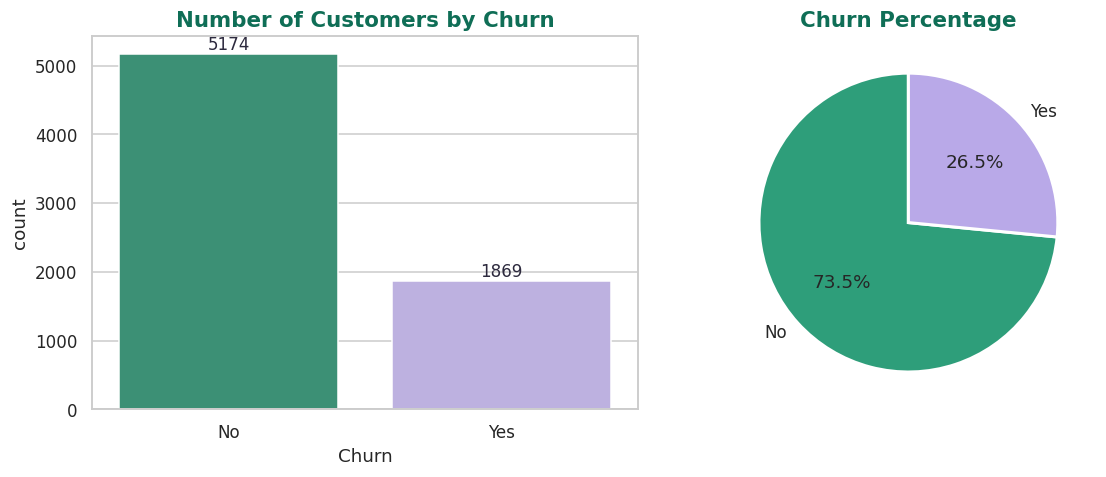

In [ ]:
counts = df['Churn'].value_counts()
percent = df['Churn'].value_counts(normalize=True).mul(100).round(2)
print(pd.DataFrame({'Customers': counts, 'Percentage (%)': percent}))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

sns.countplot(data=df, x='Churn', palette=CHURN_COLORS, ax=ax[0])
ax[0].set_title('Number of Customers by Churn')
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                   ha='center', va='bottom', fontsize=11, color='#2D2A3E')

ax[1].pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90,
          colors=[EMERALD, LAVENDER], wedgeprops={'edgecolor': 'white', 'linewidth': 2})
ax[1].set_title('Churn Percentage')

plt.tight_layout()
plt.show()

**Observations:**
- **5,174 customers (73.5%) stayed** and **1,869 customers (26.5%) churned**.
- The data is **moderately imbalanced**: churners are the minority class.
- A model that simply predicts "No churn" for everyone would be about 73.5% accurate without learning anything. So **accuracy alone is misleading** here, and we will use Recall, Precision, F1-score and ROC-AUC (Chapter 8).

## 3.9 Summary of Initial Findings
| Finding | Implication |
|---|---|
| 7,043 rows, 21 columns, no standard NaN values | Dataset is complete and moderately sized |
| `TotalCharges` stored as text | Needs conversion to numeric (Chapter 4) |
| `customerID` is just an identifier | Will be dropped before modelling |
| Many categorical columns, some with "No internet/phone service" labels | Need encoding and possible label merging |
| 26.5% churn rate | Class imbalance must be handled and evaluated carefully |

# Chapter 4: Data Cleaning and Preprocessing

## 4.1 Introduction to Data Cleaning
Data cleaning is the process of detecting and correcting errors, inconsistencies and missing values in a dataset. It is important because a model can only be as good as the data it learns from: the principle "garbage in, garbage out" applies directly.

In this chapter we follow a fixed checklist:
1. Check for missing values (including hidden ones)
2. Fix incorrect data types
3. Treat the missing values with a justified method
4. Check for duplicate records
5. Check consistency of categorical labels
6. Detect outliers and check skewness
7. Validate the cleaned dataset

Encoding and scaling are part of preprocessing, and are done in Chapter 6 after we understand the data through EDA.

## 4.2 Mathematical Foundations Used in This Chapter

**(a) Missing value percentage** tells us how serious a missing-data problem is:

$$\text{Missing \%} = \frac{\text{Number of missing values}}{\text{Total number of values}} \times 100$$

**(b) Mean and standard deviation** describe the centre and spread of a numeric column:

$$\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i \qquad\qquad s = \sqrt{\frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})^2}$$

**(c) Interquartile Range (IQR) and Tukey fences** detect outliers without assuming any distribution. Q1 is the 25th percentile and Q3 is the 75th percentile:

$$IQR = Q_3 - Q_1$$

$$\text{Lower fence} = Q_1 - 1.5 \times IQR \qquad\qquad \text{Upper fence} = Q_3 + 1.5 \times IQR$$

A value outside the two fences is flagged as an outlier.

**(d) Z-score** measures how many standard deviations a value is from the mean. A common rule flags values with |z| > 3:

$$z = \frac{x - \bar{x}}{s}$$

**(e) Skewness** measures the asymmetry of a distribution:

$$\text{Skewness} = \frac{1}{n}\sum_{i=1}^{n}\left(\frac{x_i-\bar{x}}{s}\right)^3$$

Rule of thumb: |skewness| < 0.5 is roughly symmetric, 0.5 to 1 is moderately skewed, and above 1 is highly skewed. A positive value means a longer tail on the right.

**(f) Relationship between billing columns.** A customer's total bill should be roughly the number of months they stayed times their monthly charge:

$$\text{TotalCharges} \approx \text{tenure} \times \text{MonthlyCharges}$$

We use this relationship to decide how to treat the missing `TotalCharges` values.

## 4.3 Creating a Working Copy of the Data
We make a copy of the original DataFrame and do all cleaning on the copy. This keeps the raw data untouched, so we can always compare before and after or restart if something goes wrong.

In [ ]:
df_clean = df.copy()
print('Working copy created. Shape:', df_clean.shape)

Working copy created. Shape: (7043, 21)


## 4.4 Checking for Missing Values
We first count the standard missing values (NaN) in every column. However, missing data can also hide as blank text such as a single space, which `isnull()` does not detect, so we check for that as well.

In [ ]:
print('Standard missing values (NaN) per column:')
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])
print('Total NaN:', df_clean.isnull().sum().sum())

blank_count = (df_clean['TotalCharges'].str.strip() == '').sum()
print('\nBlank (empty-space) entries in TotalCharges:', blank_count)

Standard missing values (NaN) per column:
Series([], dtype: int64)
Total NaN: 0

Blank (empty-space) entries in TotalCharges: 11


**Observation:** `isnull()` reports **zero** missing values, so the dataset looks complete. But `TotalCharges` contains **11 blank entries** (a single space instead of a number). These are hidden missing values, and they are also the reason this column was loaded as text.

## 4.5 Fixing the Data Type of TotalCharges
`TotalCharges` should be numeric but is stored as text because of the blank entries. We convert it with `pd.to_numeric(errors='coerce')`, which turns anything that is not a valid number into NaN. This makes the hidden missing values visible.

In [ ]:
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')

missing = df_clean['TotalCharges'].isnull().sum()
print('Data type now:', df_clean['TotalCharges'].dtype)
print('Missing values in TotalCharges:', missing)
print('Missing percentage: {:.3f}%'.format(missing / len(df_clean) * 100))

Data type now: float64
Missing values in TotalCharges: 11
Missing percentage: 0.156%


**Observation:** After conversion, `TotalCharges` is a numeric (float) column with **11 missing values**. Using the formula from 4.2(a): 11 / 7,043 × 100 = **0.156%** of the rows, a very small share.

## 4.6 Investigating the Missing Rows
Before deciding what to do, we look at the 11 affected customers to understand *why* their values are missing. Dropping or filling values without understanding the cause can introduce bias.

In [ ]:
df_clean[df_clean['TotalCharges'].isnull()][['customerID', 'tenure', 'MonthlyCharges',
                                              'TotalCharges', 'Contract', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,NaN,Two year,No
753,3115-CZMZD,0,20.25,NaN,Two year,No
936,5709-LVOEQ,0,80.85,NaN,Two year,No
1082,4367-NUYAO,0,25.75,NaN,Two year,No
1340,1371-DWPAZ,0,56.05,NaN,Two year,No
3331,7644-OMVMY,0,19.85,NaN,Two year,No
3826,3213-VVOLG,0,25.35,NaN,Two year,No
4380,2520-SGTTA,0,20.00,NaN,Two year,No
5218,2923-ARZLG,0,19.70,NaN,One year,No
6670,4075-WKNIU,0,73.35,NaN,Two year,No


**Observation:** All 11 customers have **tenure = 0**, meaning they joined very recently and have not yet received their first bill. All of them have `Churn = No`, and 10 of the 11 are on a two-year contract (the other has a one-year contract). The missing value therefore has a clear reason: **no billing has happened yet**.

## 4.7 Treating the Missing Values
There are three options: (1) drop the 11 rows, (2) fill with the mean or median, or (3) fill with a value that matches the business logic. From 4.2(f), TotalCharges ≈ tenure × MonthlyCharges, so for tenure = 0 the correct total is **0**.

| Option | Decision | Reason |
|---|---|---|
| Drop the rows | Rejected | Loses valid customers, and all of them are non-churners |
| Fill with mean or median | Rejected | Would claim these customers were billed about 2,000, which is false |
| **Fill with 0** | **Selected** | Matches the real situation: no billing yet |

In [ ]:
df_clean.loc[df_clean['tenure'] == 0, 'TotalCharges'] = 0

print('Missing values in TotalCharges after treatment:', df_clean['TotalCharges'].isnull().sum())
print('Rows kept:', len(df_clean))

Missing values in TotalCharges after treatment: 0
Rows kept: 7043


**Observation:** The missing values are now zero and all **7,043 rows are retained**, with no information lost and no artificial values invented.

## 4.8 Checking for Duplicate Records
Duplicate rows would give some customers extra weight during training and can inflate model performance. We check both fully identical rows and repeated customer IDs, since each customer should appear exactly once.

In [ ]:
print('Fully duplicated rows      :', df_clean.duplicated().sum())
print('Duplicated customerID values:', df_clean['customerID'].duplicated().sum())

Fully duplicated rows      : 0
Duplicated customerID values: 0


**Observation:** There are **0 duplicate rows** and **0 repeated customer IDs**, so every row represents a unique customer and no removal is needed.

## 4.9 Checking Consistency of Categorical Labels
Categorical columns can contain spelling variations, extra spaces or inconsistent capitalisation (for example "Yes", "yes", " Yes"), which would be treated as different categories. We print the unique values of every categorical column to verify them.

In [ ]:
cat_cols = [c for c in df_clean.columns
            if df_clean[c].dtype == 'object' and c != 'customerID']

for c in cat_cols:
    print(f'{c:18s}:', df_clean[c].unique().tolist())

gender            : ['Female', 'Male']
Partner           : ['Yes', 'No']
Dependents        : ['No', 'Yes']
PhoneService      : ['No', 'Yes']
MultipleLines     : ['No phone service', 'No', 'Yes']
InternetService   : ['DSL', 'Fiber optic', 'No']
OnlineSecurity    : ['No', 'Yes', 'No internet service']
OnlineBackup      : ['Yes', 'No', 'No internet service']
DeviceProtection  : ['No', 'Yes', 'No internet service']
TechSupport       : ['No', 'Yes', 'No internet service']
StreamingTV       : ['No', 'Yes', 'No internet service']
StreamingMovies   : ['No', 'Yes', 'No internet service']
Contract          : ['Month-to-month', 'One year', 'Two year']
PaperlessBilling  : ['Yes', 'No']
PaymentMethod     : ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
Churn             : ['No', 'Yes']


**Observation:** The labels are spelled consistently and contain no stray spaces or case differences. However, several service columns contain the labels **"No internet service"** and **"No phone service"**, which carry the same meaning as "No". We handle this next.

## 4.10 Merging Redundant Labels
Six add-on columns (OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies) have the extra label "No internet service" for 1,526 customers, and MultipleLines has "No phone service" for 682 customers. This information is already stored in `InternetService` and `PhoneService`, so these labels are redundant. Merging them into "No" reduces the number of categories and avoids duplicate information when we encode the data.

In [ ]:
internet_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                 'TechSupport', 'StreamingTV', 'StreamingMovies']

df_clean[internet_cols] = df_clean[internet_cols].replace('No internet service', 'No')
df_clean['MultipleLines'] = df_clean['MultipleLines'].replace('No phone service', 'No')

for c in internet_cols + ['MultipleLines']:
    print(f'{c:18s}:', df_clean[c].value_counts().to_dict())

OnlineSecurity    : {'No': 5024, 'Yes': 2019}
OnlineBackup      : {'No': 4614, 'Yes': 2429}
DeviceProtection  : {'No': 4621, 'Yes': 2422}
TechSupport       : {'No': 4999, 'Yes': 2044}
StreamingTV       : {'No': 4336, 'Yes': 2707}
StreamingMovies   : {'No': 4311, 'Yes': 2732}
MultipleLines     : {'No': 4072, 'Yes': 2971}


**Observation:** All seven columns now contain only **Yes** and **No**. For example, `OnlineSecurity` has 2,019 "Yes" and 5,024 "No" (3,498 original "No" plus 1,526 merged). No information is lost, because `InternetService` still tells us who has no internet.

## 4.11 Outlier Detection and Skewness Analysis
Outliers are unusual values far from the rest of the data, and they can distort statistics and some models. We apply the IQR rule and the z-score rule from 4.2 to the three numeric columns, and also compute skewness to see how symmetric each distribution is. SeniorCitizen is excluded because it is a 0/1 flag.

,Column,Q1,Q3,IQR,Lower fence,Upper fence,IQR outliers,|z|>3 count,Skewness
0,tenure,9.00,55.00,46.00,-60.00,124.00,0,0,0.24
1,MonthlyCharges,35.50,89.85,54.35,-46.02,171.38,0,0,-0.22
2,TotalCharges,398.55,3786.60,3388.05,-4683.52,8868.67,0,0,0.96


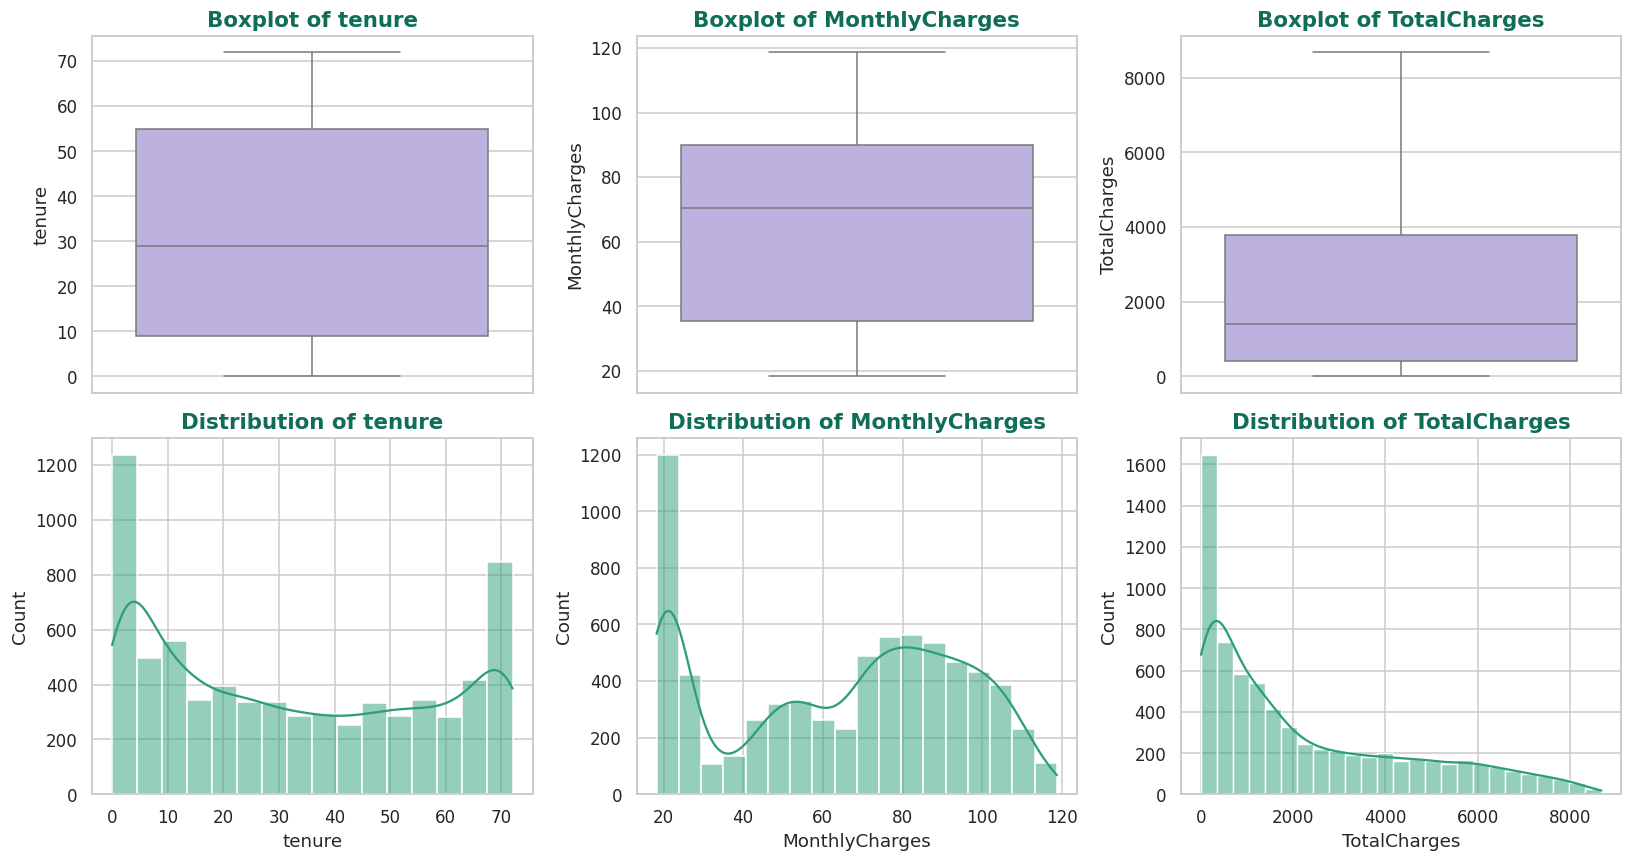

In [ ]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
rows = []
for c in num_cols:
    s = df_clean[c]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (s - s.mean()) / s.std()
    rows.append([c, q1, q3, iqr, lower, upper,
                 ((s < lower) | (s > upper)).sum(), (z.abs() > 3).sum(), s.skew()])

outlier_table = pd.DataFrame(rows, columns=['Column', 'Q1', 'Q3', 'IQR', 'Lower fence',
                                            'Upper fence', 'IQR outliers', '|z|>3 count',
                                            'Skewness']).round(2)
display(outlier_table)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, c in enumerate(num_cols):
    sns.boxplot(y=df_clean[c], ax=axes[0, i], color=LAVENDER)
    axes[0, i].set_title(f'Boxplot of {c}')
    sns.histplot(df_clean[c], kde=True, ax=axes[1, i], color=EMERALD)
    axes[1, i].set_title(f'Distribution of {c}')
plt.tight_layout()
plt.show()

**Observations:**
- **No outliers** are found in any numeric column: both the IQR rule and the |z| > 3 rule flag **0 values** for tenure, MonthlyCharges and TotalCharges. All values lie within realistic ranges, so nothing needs to be removed.
- **Skewness:** tenure (0.24) and MonthlyCharges (-0.22) are roughly symmetric. **TotalCharges (0.96) is moderately right-skewed**, because many customers have small totals (new customers) and a few have very large ones (long-term, high-paying customers). This is natural and not an error.
- Because of this skew, we will consider **scaling** the numeric columns in Chapter 6, which matters for distance-based and linear models.

## 4.12 Validating the Cleaned Dataset
As a final check, we confirm that the cleaned dataset has no missing values, no duplicates and correct data types, and then save it as a new file. `customerID` is kept for now and will be dropped in Chapter 6, because it is only an identifier and has no predictive value.

In [ ]:
print('Shape            :', df_clean.shape)
print('Missing values   :', df_clean.isnull().sum().sum())
print('Duplicate rows   :', df_clean.duplicated().sum())
print()
print(df_clean.dtypes)

df_clean.to_csv('telco_churn_clean.csv', index=False)
print('\nCleaned file saved as telco_churn_clean.csv')

Shape            : (7043, 21)
Missing values   : 0
Duplicate rows   : 0

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

Cleaned file saved as telco_churn_clean.csv


## 4.13 Summary of Cleaning Steps
| Step | Issue found | Action taken | Result |
|---|---|---|---|
| Missing values | 11 hidden blanks in TotalCharges (0.156%) | Filled with 0 (all have tenure = 0, not yet billed) | 0 missing, all 7,043 rows kept |
| Data type | TotalCharges stored as text | Converted to float | Numeric column |
| Duplicates | None found | No action | 0 duplicates |
| Label consistency | "No internet service" / "No phone service" were redundant | Merged into "No" in 7 columns | Only Yes/No remain |
| Outliers | None by IQR or z-score | No action | Data retained |
| Skewness | TotalCharges moderately right-skewed (0.96) | Noted; scaling to be considered in Chapter 6 | Documented |

The dataset is now clean and ready for exploratory data analysis in Chapter 5.

## 5.1 Introduction to Exploratory Data Analysis
Exploratory Data Analysis (EDA) is the process of summarising and visualising a dataset to discover patterns, relationships and anomalies before building models. It guides later decisions such as which features to keep, how to encode them and which models to try.

In this chapter we study how churn is related to:
1. Customer demographics
2. Subscribed services
3. Account and billing information
4. Numeric variables (tenure and charges)

We then quantify these relationships using correlation analysis and statistical tests, and finally verify the four hypotheses stated in Chapter 2.

## 5.2 Mathematical Foundations Used in This Chapter

**(a) Churn rate of a group** lets us compare groups fairly, even when they have different sizes:

$$\text{Churn rate}_g = \frac{\text{Churned customers in group } g}{\text{Total customers in group } g} \times 100$$

**(b) Pearson correlation coefficient (r)** measures the strength and direction of a *linear* relationship between two numeric variables x and y:

$$r = \frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2}\;\sqrt{\sum_{i=1}^{n}(y_i-\bar{y})^2}}$$

The value always lies between -1 and +1. A value near +1 means that when x increases, y tends to increase. A value near -1 means y tends to decrease. A value near 0 means there is no linear relationship. When y is a 0/1 variable such as Churn, this is also called the *point-biserial correlation*.

**(c) Chi-square test of independence** checks whether two categorical variables are related. It compares the observed counts (O) in a contingency table with the counts we would expect (E) if the variables were independent:

$$\chi^2 = \sum_{i,j}\frac{(O_{ij}-E_{ij})^2}{E_{ij}} \qquad\text{where}\qquad E_{ij}=\frac{(\text{Row total}_i)\times(\text{Column total}_j)}{N}$$

The degrees of freedom are df = (rows - 1) × (columns - 1).

- **Null hypothesis (H0):** the feature and churn are independent.
- **Decision rule:** if the p-value is below 0.05, we reject H0 and conclude the feature is significantly associated with churn.

**(d) Cramér's V** converts the chi-square value into a strength measure between 0 (no association) and 1 (perfect association), so different features can be compared:

$$V = \sqrt{\frac{\chi^2}{N\,(k-1)}} \qquad\text{where } k=\min(\text{rows},\text{columns})$$

Rough interpretation used in this report: below 0.10 is negligible, 0.10 to 0.30 is weak to moderate, and above 0.30 is moderate to strong.

**(e) Worked example for Contract vs Churn.** Of 7,043 customers, 3,875 are on month-to-month contracts and 1,869 churned overall. If contract type had no effect, the expected number of churners among month-to-month customers would be:

$$E = \frac{3{,}875 \times 1{,}869}{7{,}043} \approx 1{,}028$$

The observed number is **1,655**, much higher than expected. This single cell contributes (1655 - 1028)² / 1028 ≈ 382 to the chi-square total, which is why the overall test statistic for Contract turns out so large (about 1,185).

## 5.3 Preparing the Data for EDA
We make a copy of the cleaned dataset and add two helper columns: a numeric version of Churn (1 = Yes, 0 = No) so we can calculate averages and correlations, and a Yes/No version of SeniorCitizen so its charts have readable labels. We also define one reusable function that draws the churn rate for any categorical column, with a dashed line showing the overall churn rate for comparison.

In [ ]:
df_eda = df_clean.copy()
df_eda['Churn_num'] = (df_eda['Churn'] == 'Yes').astype(int)
df_eda['SeniorCitizen_label'] = df_eda['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

overall_churn = df_eda['Churn_num'].mean() * 100
print(f'Overall churn rate: {overall_churn:.2f}%')

BAR_COLORS = [EMERALD, LAVENDER, DEEP, '#8E7CC3']

def churn_rate_plot(col, ax, order=None, rotate=False):
    rate = df_eda.groupby(col, observed=True)['Churn_num'].mean().mul(100)
    if order:
        rate = rate.reindex(order)
    bars = ax.bar(rate.index.astype(str), rate.values,
                  color=BAR_COLORS[:len(rate)], edgecolor='white')
    ax.axhline(overall_churn, color='#2D2A3E', linestyle='--', linewidth=1,
               label=f'Overall ({overall_churn:.1f}%)')
    for b, v in zip(bars, rate.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f'{v:.1f}%',
                ha='center', fontsize=10, color='#2D2A3E')
    ax.set_title(f'Churn Rate by {col}')
    ax.set_ylabel('Churn rate (%)')
    ax.set_ylim(0, rate.max() * 1.2)
    ax.legend(fontsize=8)
    if rotate:
        plt.setp(ax.get_xticklabels(), rotation=25, ha='right')

Overall churn rate: 26.54%


## 5.4 Churn by Customer Demographics
Demographic columns describe *who* the customer is: gender, whether they are a senior citizen, and whether they have a partner or dependents. The charts below show the churn rate inside each group, so we can see which kinds of customers leave more often.

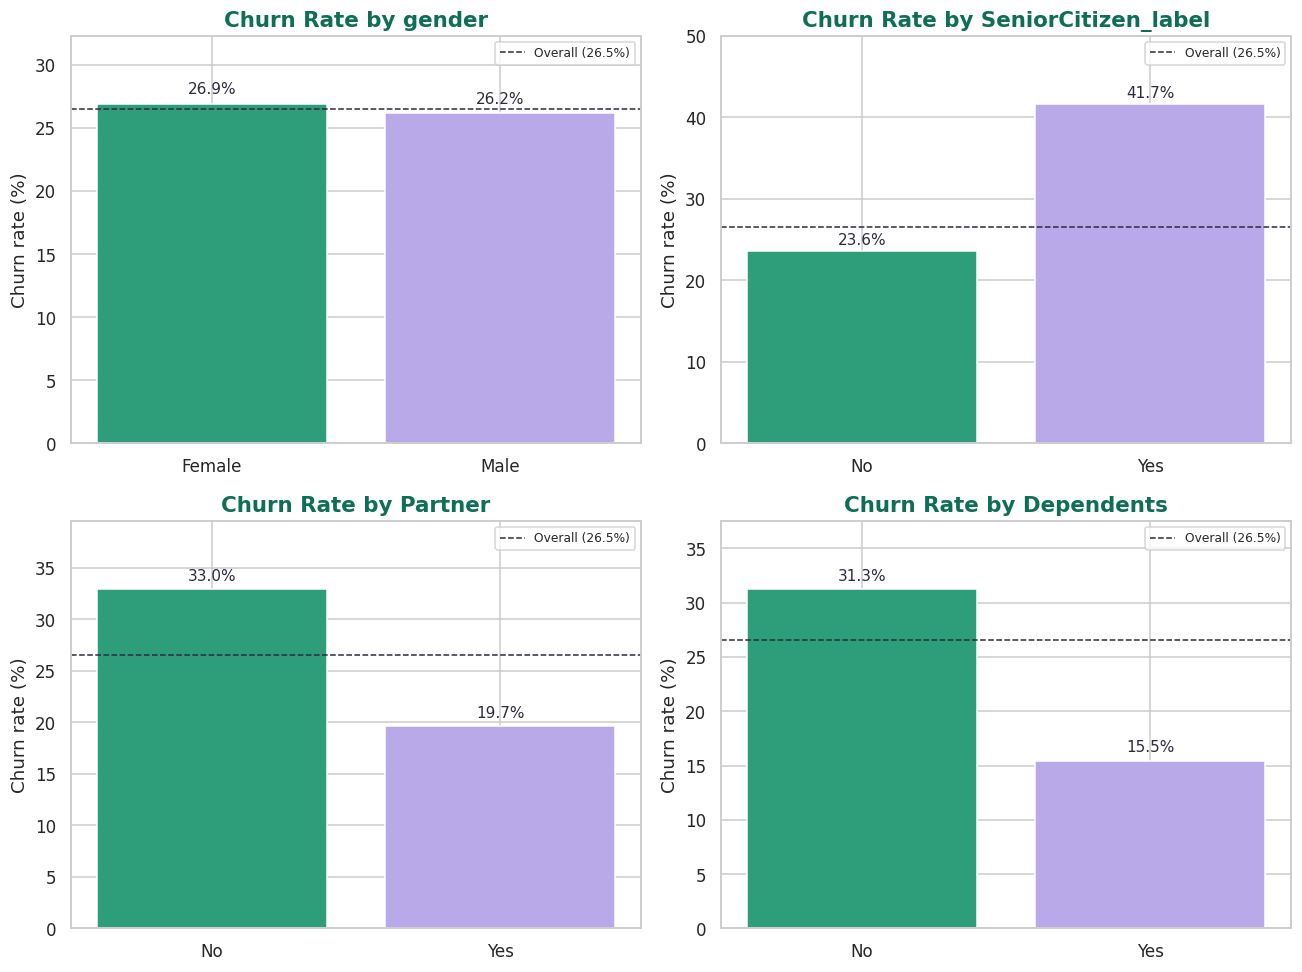

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.ravel(), ['gender', 'SeniorCitizen_label', 'Partner', 'Dependents']):
    churn_rate_plot(col, ax)
plt.tight_layout()
plt.show()

**Observations:**
- **Gender has almost no effect:** 26.9% of female and 26.2% of male customers churn.
- **Senior citizens churn much more:** 41.7% compared with 23.6% for non-seniors. They make up only 1,142 of 7,043 customers (about 16%), but they are a high-risk group.
- **Customers with a partner or dependents are more loyal:** churn is 19.7% with a partner versus 33.0% without, and 15.5% with dependents versus 31.3% without. Customers living alone, without family, are more likely to leave.

## 5.5 Churn by Subscribed Services
This section studies the services a customer uses: phone, internet type and the optional add-ons. We first look at the main services, then at the six add-on services (security, backup, device protection, tech support and streaming).

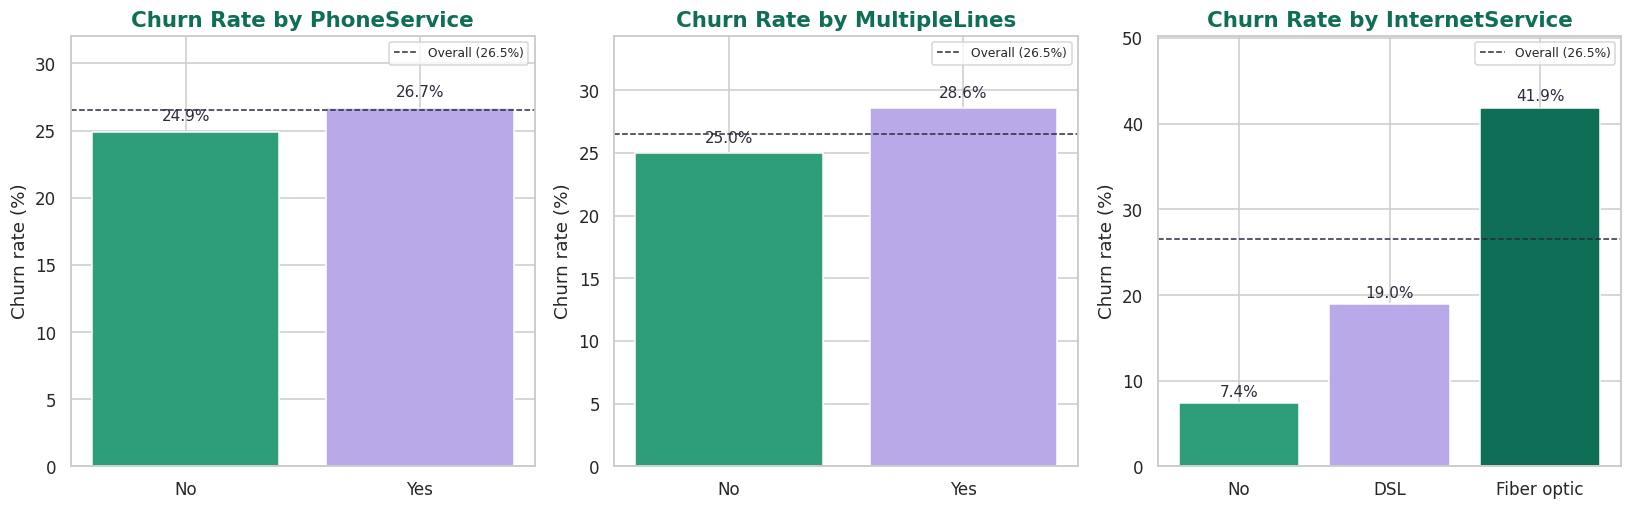

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
churn_rate_plot('PhoneService', axes[0])
churn_rate_plot('MultipleLines', axes[1])
churn_rate_plot('InternetService', axes[2], order=['No', 'DSL', 'Fiber optic'])
plt.tight_layout()
plt.show()

**Observations:**
- **Internet type matters a lot:** fiber optic customers churn at **41.9%**, DSL customers at 19.0%, and customers with no internet at only 7.4%. Fiber customers pay more and are the most likely to leave, which could point to price or service-quality issues.
- **Phone service has little effect** (24.9% without, 26.7% with), and multiple lines only slightly raises churn (28.6% vs 25.0%).
- **Protective add-ons reduce churn strongly:** customers *without* Online Security churn at 31.3% versus 14.6% with it, and *without* Tech Support at 31.2% versus 15.2% with it. Backup and Device Protection show a smaller gap.
- **Streaming services slightly increase churn** (about 30% with streaming vs 24% without), which probably reflects that streaming users are mostly fiber customers.

## 5.6 Churn by Account and Billing Information
Account columns describe the customer's contract and how they pay. These are business decisions the company controls, so patterns here are the most useful for designing retention strategies.

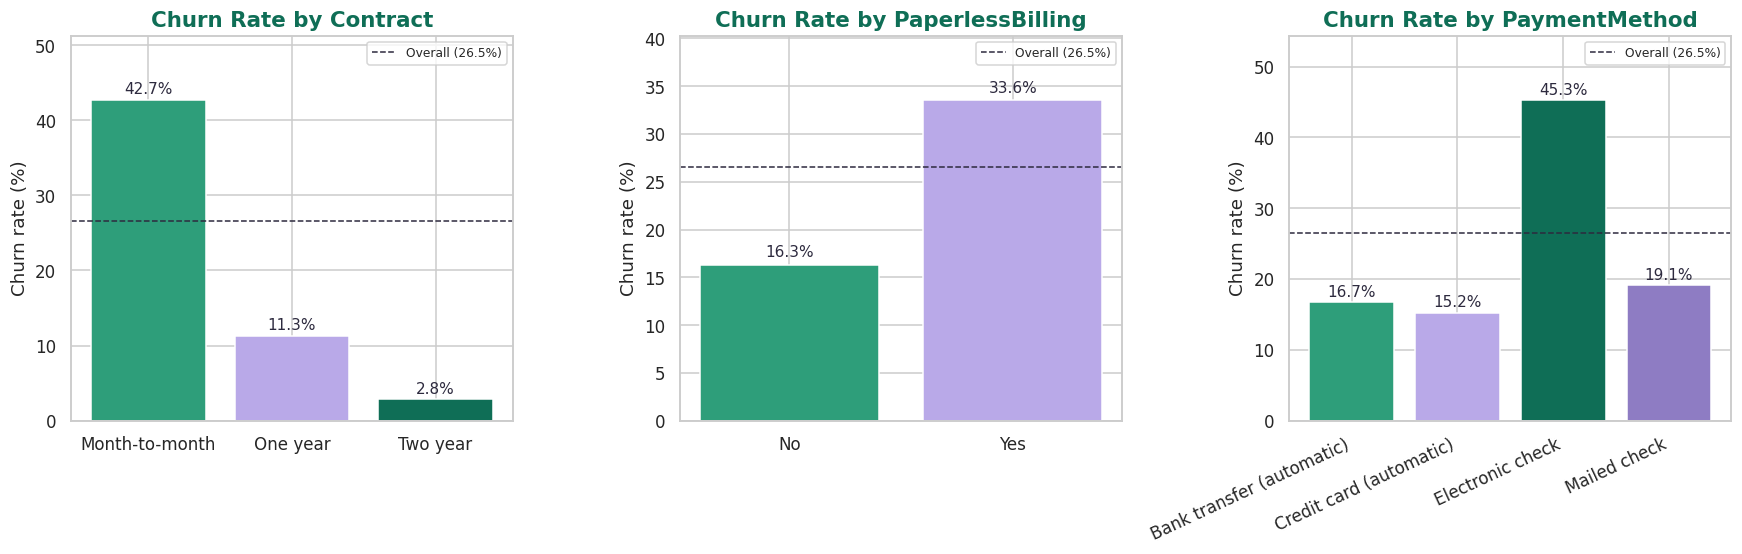

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
churn_rate_plot('Contract', axes[0], order=['Month-to-month', 'One year', 'Two year'])
churn_rate_plot('PaperlessBilling', axes[1])
churn_rate_plot('PaymentMethod', axes[2], rotate=True)
plt.tight_layout()
plt.show()

**Observations:**
- **Contract type is the strongest pattern in the whole dataset:** churn is **42.7%** for month-to-month, 11.3% for one-year and only **2.8%** for two-year contracts. Customers on month-to-month plans are free to leave at any time.
- **Electronic check users churn the most (45.3%)**, while customers paying by bank transfer (16.7%), credit card (15.2%) or mailed check (19.1%) churn far less. Automatic payment methods seem to make customers more "sticky".
- **Paperless billing customers churn more:** 33.6% vs 16.3%.

## 5.7 Numeric Variables vs Churn
Here we compare the distributions of tenure, MonthlyCharges and TotalCharges for customers who stayed and those who churned. The top row shows density curves (the shape of the distribution), and the bottom row shows boxplots (median and spread).

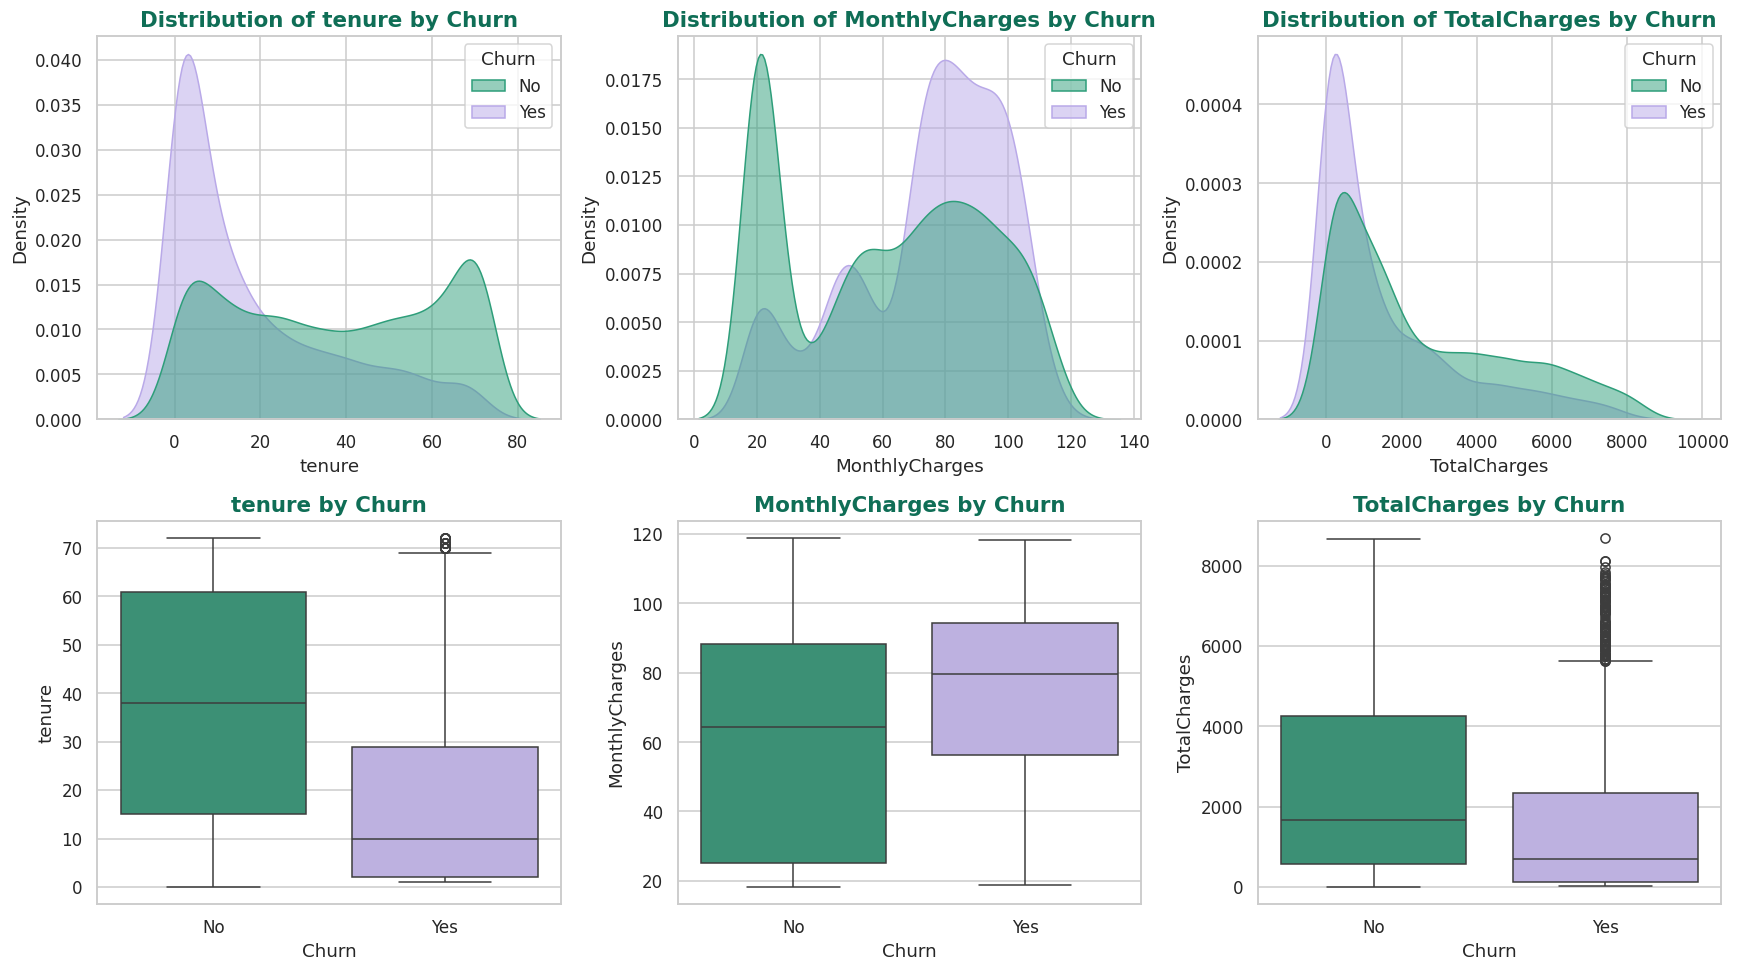

tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43      2549.91  1679.52
Yes    17.98   10.0          74.44  79.65      1531.80   703.55

In [ ]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for i, col in enumerate(num_cols):
    sns.kdeplot(data=df_eda, x=col, hue='Churn', palette=CHURN_COLORS,
                fill=True, common_norm=False, alpha=0.5, ax=axes[0, i])
    axes[0, i].set_title(f'Distribution of {col} by Churn')
    sns.boxplot(data=df_eda, x='Churn', y=col, palette=CHURN_COLORS, ax=axes[1, i])
    axes[1, i].set_title(f'{col} by Churn')
plt.tight_layout()
plt.show()

display(df_eda.groupby('Churn')[num_cols].agg(['mean', 'median']).round(2))

**Observations:**
- **Tenure:** customers who stayed have an average tenure of **37.6 months** (median 38), while churned customers average only **18.0 months** (median **10**). Most churn happens early in the customer relationship.
- **MonthlyCharges:** churners pay more on average (**74.44** vs 61.27), and their median is also higher (79.65 vs 64.43).
- **TotalCharges:** churners have a lower total (mean 1,531.80 vs 2,549.91). This does not mean they paid less per month. It reflects their short tenure, since TotalCharges ≈ tenure × MonthlyCharges.

## 5.8 Churn Rate by Tenure Group and Monthly Charge Band
A continuous variable is easier to interpret when grouped into bands. We divide tenure into five groups (in months) and monthly charges into four price bands, then compute the churn rate in each band. These groups may also be useful engineered features in Chapter 6.

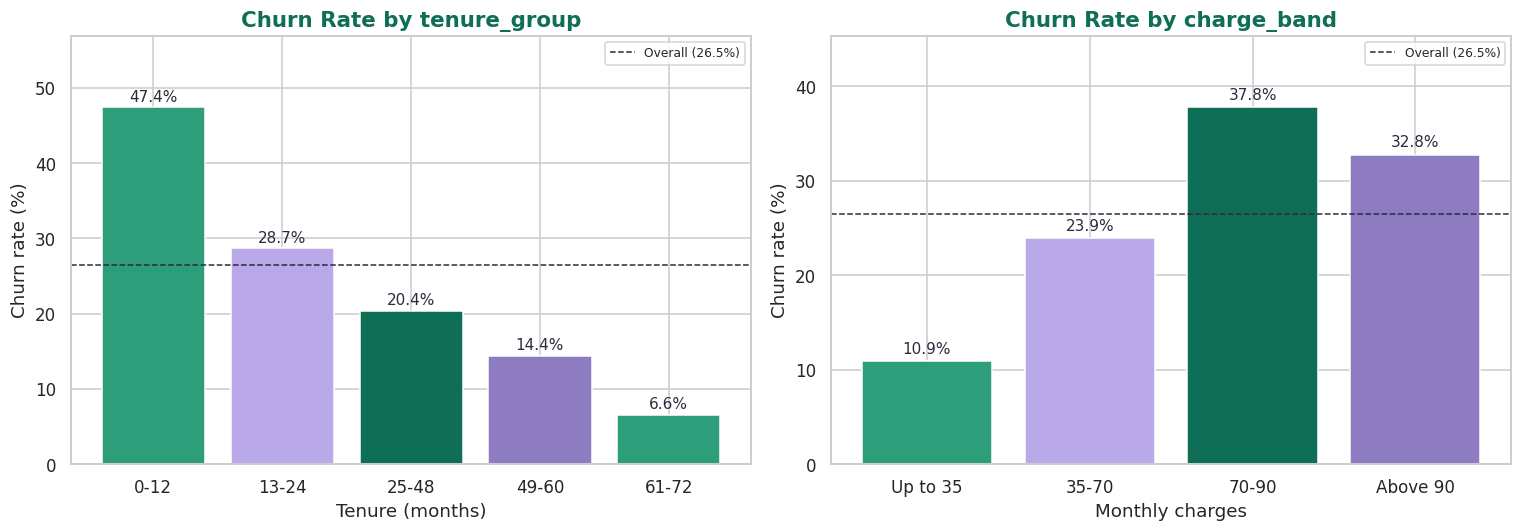

,Customers,Churn_rate_pct
tenure_group,,
0-12,2186,47.4
13-24,1024,28.7
25-48,1594,20.4
49-60,832,14.4
61-72,1407,6.6


,Customers,Churn_rate_pct
charge_band,,
Up to 35,1735,10.9
35-70,1725,23.9
70-90,1844,37.8
Above 90,1739,32.8


In [ ]:
df_eda['tenure_group'] = pd.cut(df_eda['tenure'], bins=[-1, 12, 24, 48, 60, 72],
                                labels=['0-12', '13-24', '25-48', '49-60', '61-72'])
df_eda['charge_band'] = pd.cut(df_eda['MonthlyCharges'], bins=[0, 35, 70, 90, 120],
                               labels=['Up to 35', '35-70', '70-90', 'Above 90'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
churn_rate_plot('tenure_group', axes[0])
churn_rate_plot('charge_band', axes[1])
axes[0].set_xlabel('Tenure (months)')
axes[1].set_xlabel('Monthly charges')
plt.tight_layout()
plt.show()

display(df_eda.groupby('tenure_group', observed=True)['Churn_num']
        .agg(Customers='count', Churn_rate_pct=lambda s: round(s.mean() * 100, 1)))
display(df_eda.groupby('charge_band', observed=True)['Churn_num']
        .agg(Customers='count', Churn_rate_pct=lambda s: round(s.mean() * 100, 1)))

**Observations:**
- **Churn falls steadily as tenure grows:** 47.4% in the first year, 28.7% in year two, 20.4% for 25-48 months, 14.4% for 49-60 months, and just **6.6%** for customers with more than 5 years. The first 12 months are the most critical period, and this group contains 2,186 customers.
- **Churn rises with price up to a point:** 10.9% for charges up to 35, 23.9% for 35-70, and **37.8%** for 70-90. For charges above 90 it is slightly lower (32.8%), so the relationship with price is not perfectly linear.

## 5.9 Combined Effect of Contract Type and Internet Service
So far we looked at one feature at a time. A heatmap of churn rate across two features together shows how they interact. We combine the two strongest categorical drivers, contract type and internet service.

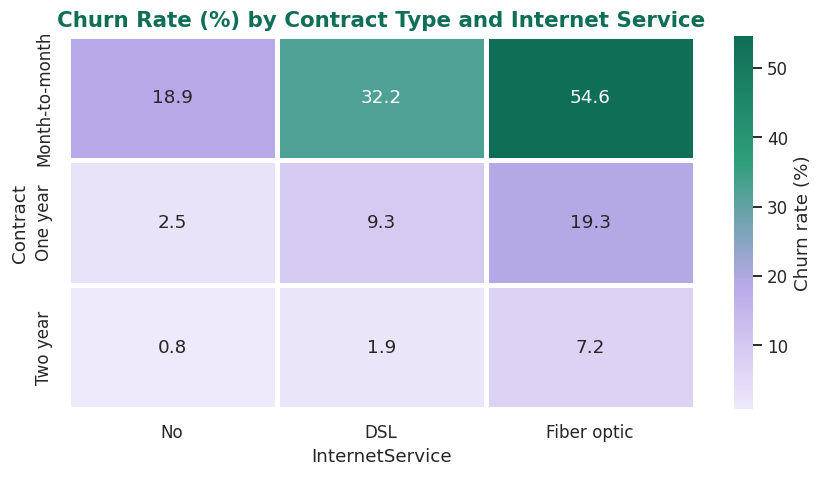

In [ ]:
pivot = (df_eda.pivot_table(index='Contract', columns='InternetService',
                            values='Churn_num', aggfunc='mean')
         .mul(100).round(1)
         .reindex(index=['Month-to-month', 'One year', 'Two year'],
                  columns=['No', 'DSL', 'Fiber optic']))

plt.figure(figsize=(8, 4.5))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap=CMAP, linewidths=2, linecolor='white',
            cbar_kws={'label': 'Churn rate (%)'})
plt.title('Churn Rate (%) by Contract Type and Internet Service')
plt.tight_layout()
plt.show()

**Observations:**
- The **highest-risk combination is month-to-month contract with fiber optic internet, at 54.6% churn**: more than one in two customers leaves.
- Moving to a longer contract lowers churn for every internet type. For fiber customers, churn drops from 54.6% (month-to-month) to 19.3% (one year) and 7.2% (two year).
- This shows that features **work together**, which is why models that can capture interactions (such as tree-based models) may perform well here.

## 5.10 Correlation Analysis of Numeric Variables
We compute the Pearson correlation coefficient (Section 5.2b) between all numeric variables and the numeric churn indicator. The heatmap shows the correlation of every pair, and the bar chart ranks the correlation with churn. This reveals both the drivers of churn and any pairs of input features that are strongly related to each other.

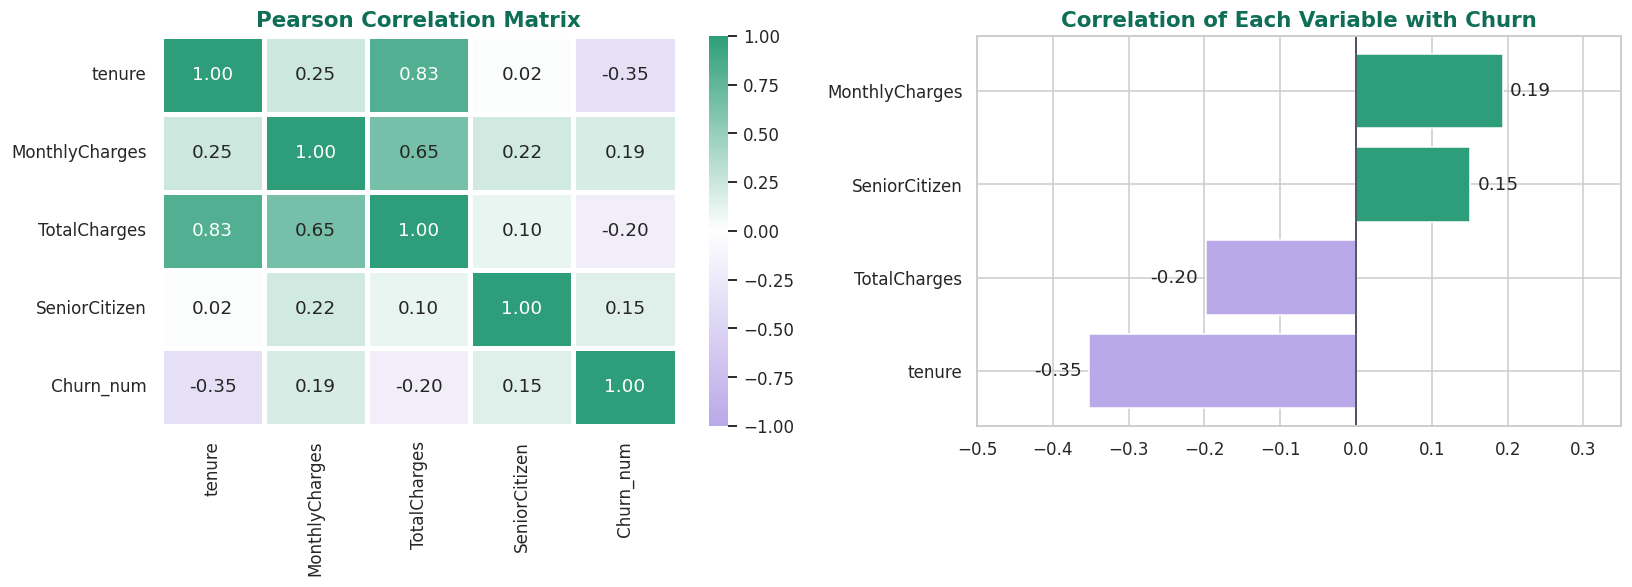

In [ ]:
from matplotlib.colors import LinearSegmentedColormap
DIV_CMAP = LinearSegmentedColormap.from_list('div_lav_em', [LAVENDER, '#FFFFFF', EMERALD])

corr_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'Churn_num']
corr = df_eda[corr_cols].corr()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.heatmap(corr, annot=True, fmt='.2f', cmap=DIV_CMAP, vmin=-1, vmax=1,
            linewidths=2, linecolor='white', ax=axes[0])
axes[0].set_title('Pearson Correlation Matrix')

with_churn = corr['Churn_num'].drop('Churn_num').sort_values()
axes[1].barh(with_churn.index, with_churn.values,
             color=[LAVENDER if v < 0 else EMERALD for v in with_churn.values])
for i, v in enumerate(with_churn.values):
    axes[1].text(v + (0.01 if v >= 0 else -0.01), i, f'{v:.2f}',
                 va='center', ha='left' if v >= 0 else 'right')
axes[1].set_title('Correlation of Each Variable with Churn')
axes[1].set_xlim(-0.5, 0.35)
axes[1].axvline(0, color='#2D2A3E', linewidth=1)

plt.tight_layout()
plt.show()

**Observations:**
- **tenure has the strongest correlation with churn (r = -0.35).** It is negative: the longer a customer has stayed, the less likely they are to churn.
- **MonthlyCharges (r = +0.19) and SeniorCitizen (r = +0.15)** are weakly positively related to churn. TotalCharges (r = -0.20) is negative, mainly because it grows with tenure.
- **Input features are correlated with each other:** tenure and TotalCharges have r = **0.83**, and MonthlyCharges and TotalCharges have r = 0.65. This is **multicollinearity**, because TotalCharges is mostly tenure × MonthlyCharges. It can make linear models such as Logistic Regression unstable, so we will consider it in Chapter 6.
- All correlations with churn are **weak to moderate** (none above 0.4 in size), so no single numeric variable predicts churn on its own, which supports using a multi-feature model.

## 5.11 Association of Categorical Features with Churn (Chi-Square Test)
Pearson correlation only works for numeric variables, so for categorical features we use the chi-square test of independence and Cramér's V (Section 5.2c, 5.2d). The test tells us whether a feature is significantly related to churn, and Cramér's V tells us how strong the relationship is, so we can rank all features.

,Feature,Chi-square,df,p-value,Cramers V,Significant (p<0.05)
0,Contract,1184.60,2,5.86e-258,0.410,Yes
1,InternetService,732.31,2,9.57e-160,0.322,Yes
2,PaymentMethod,648.14,3,3.68e-140,0.303,Yes
3,PaperlessBilling,258.28,1,4.07e-58,0.191,Yes
4,OnlineSecurity,205.63,1,1.23e-46,0.171,Yes
5,TechSupport,190.17,1,2.92e-43,0.164,Yes
6,Dependents,189.13,1,4.92e-43,0.164,Yes
7,SeniorCitizen_label,159.43,1,1.51e-36,0.150,Yes
8,Partner,158.73,1,2.14e-36,0.150,Yes
9,OnlineBackup,47.26,1,6.21e-12,0.082,Yes


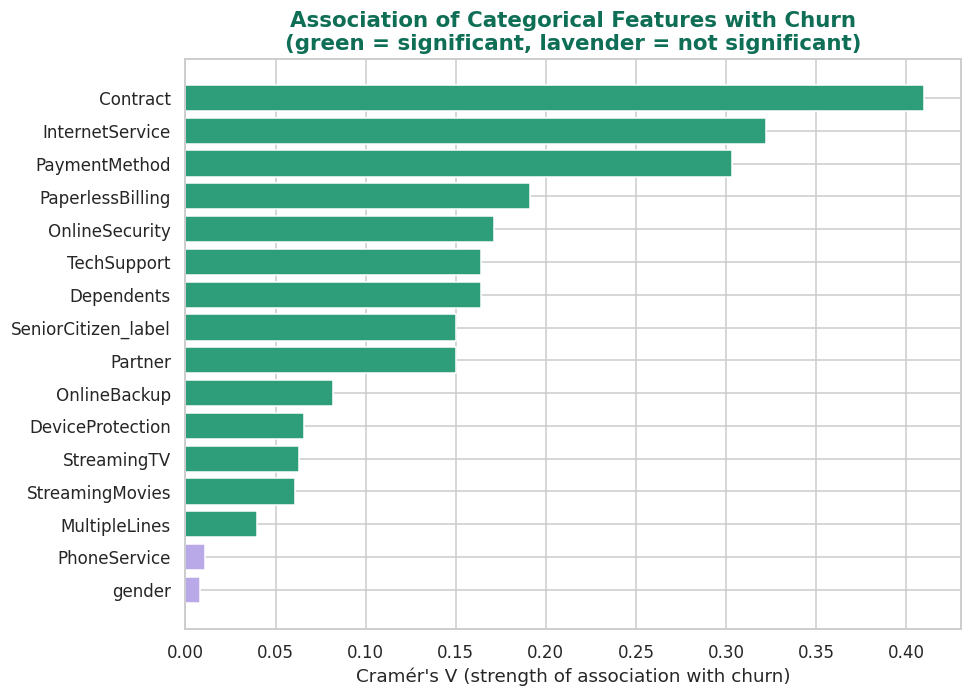

In [ ]:
from scipy.stats import chi2_contingency

cat_features = ['SeniorCitizen_label', 'gender', 'Partner', 'Dependents', 'PhoneService',
                'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
                'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
                'Contract', 'PaperlessBilling', 'PaymentMethod']

rows = []
for col in cat_features:
    table = pd.crosstab(df_eda[col], df_eda['Churn'])
    chi2, p, dof, expected = chi2_contingency(table)
    n = table.values.sum()
    k = min(table.shape) - 1
    v = np.sqrt(chi2 / (n * k))
    rows.append([col, round(chi2, 2), dof, p, round(v, 3), 'Yes' if p < 0.05 else 'No'])

chi_df = (pd.DataFrame(rows, columns=['Feature', 'Chi-square', 'df', 'p-value',
                                      'Cramers V', 'Significant (p<0.05)'])
          .sort_values('Cramers V', ascending=False).reset_index(drop=True))

plot_df = chi_df.copy()
chi_df['p-value'] = chi_df['p-value'].apply(lambda x: f'{x:.2e}')
display(chi_df)

plt.figure(figsize=(9, 6.5))
colors = [EMERALD if s == 'Yes' else LAVENDER for s in plot_df['Significant (p<0.05)']]
plt.barh(plot_df['Feature'][::-1], plot_df['Cramers V'][::-1], color=colors[::-1])
plt.xlabel("Cramér's V (strength of association with churn)")
plt.title("Association of Categorical Features with Churn\n(green = significant, lavender = not significant)")
plt.tight_layout()
plt.show()

**Observations:**
- **Contract has the strongest association** with churn (chi-square ≈ 1,184.6, Cramér's V = **0.41**), followed by **InternetService (0.32)** and **PaymentMethod (0.30)**. These three are the main categorical drivers.
- **Moderate/weak but significant features:** PaperlessBilling (0.19), OnlineSecurity (0.17), TechSupport (0.16), Dependents (0.16), SeniorCitizen (0.15) and Partner (0.15).
- **gender (V = 0.008, p = 0.49) and PhoneService (V = 0.011, p = 0.34) are NOT significant.** There is no evidence that they are related to churn, so they add almost no predictive value and are candidates for removal in feature selection.
- MultipleLines is statistically significant (p < 0.001) but its strength is negligible (V = 0.04).
- Association does not prove causation: for example, customers on month-to-month plans may also be the ones who are newer or unhappier for other reasons.

## 5.13 Summary of Key Findings from EDA

**Strongest churn drivers**
1. **Contract type:** month-to-month customers are 15 times more likely to churn than two-year customers (42.7% vs 2.8%).
2. **Tenure:** the first 12 months carry the highest risk (47.4% churn).
3. **Internet service:** fiber optic customers churn at 41.9%, and month-to-month fiber customers at 54.6%.
4. **Payment method:** electronic check users churn at 45.3%, about three times more than automatic payment users.
5. **Support add-ons:** customers without Online Security or Tech Support churn about twice as much.

**Weak or irrelevant features:** gender and PhoneService show no significant relationship with churn.

**Implications for modelling (Chapter 6 onwards):**
- Tenure and TotalCharges are highly correlated (r = 0.83), so multicollinearity must be handled or monitored.
- Categorical features dominate, so encoding is essential.
- Features interact (for example Contract × InternetService), so tree-based models are worth trying alongside Logistic Regression.
- Tenure groups and an "average monthly spend" or "number of services" feature may add useful signal.
- Because only 26.5% of customers churn, we will use stratified splitting and imbalance-aware evaluation.

**Business insight:** the company should focus retention efforts on new customers, month-to-month and fiber optic subscribers, and electronic-check payers, for example by offering discounts for moving to longer contracts, bundling Online Security and Tech Support, and encouraging automatic payments.

# Chapter 6: Feature Engineering and Preprocessing

## 6.1 Introduction
Machine learning models cannot work directly with text labels, and they perform better when the input features are informative, non-redundant and on comparable scales. This chapter converts the cleaned data from Chapter 4 into a model-ready form, guided by the findings of Chapter 5.

The steps, in order, are:
1. **Feature engineering:** create new features that capture patterns found in EDA
2. **Feature selection:** remove identifiers, irrelevant and redundant columns
3. **Encoding:** convert categorical text into numbers
4. **Train-test split:** separate data for learning and for honest evaluation
5. **Scaling:** put numeric features on a common scale
6. **Handling class imbalance:** prevent the model from ignoring the minority class (churners)

The order matters: we split the data *before* scaling and balancing, so that no information from the test set leaks into training.

## 6.2 Mathematical Foundations Used in This Chapter

**(a) Variance Inflation Factor (VIF)** measures multicollinearity, meaning how well one feature can be predicted from the other features. For feature j, we regress it on all other features and take the resulting R²:

$$VIF_j = \frac{1}{1 - R_j^2}$$

A VIF of 1 means no correlation with other features. Common rules: VIF above 5 is a concern, and above 10 is severe.

**(b) One-hot encoding and the dummy variable trap.** A categorical feature with k categories is converted into k - 1 binary (0/1) columns. The omitted category is the *reference* category, represented by all zeros. Keeping all k columns would make them sum to 1 exactly, creating perfect multicollinearity (the "dummy variable trap"). For example, Contract has 3 categories, so we create two columns, `Contract_One year` and `Contract_Two year`. Month-to-month is the reference, where both are 0.

**(c) Standardisation (z-score scaling)** rescales a feature to have mean 0 and standard deviation 1:

$$z = \frac{x - \mu_{train}}{\sigma_{train}}$$

A related method is **min-max scaling**, which maps values into the range [0, 1]:

$$x' = \frac{x - x_{min}}{x_{max} - x_{min}}$$

We use standardisation because it is less affected by extreme values and suits Logistic Regression. The mean μ and standard deviation σ are computed **only from the training set** and then applied to the test set, to avoid *data leakage*.

**(d) Stratified train-test split.** We keep the same churn proportion p in both sets. With a test fraction of 0.2:

$$N_{test} = 0.2 \times 7043 \approx 1409 \qquad\qquad \text{Churners in test} \approx 0.2 \times 1869 \approx 374$$

**(e) Imbalance ratio and class weights.** The imbalance ratio is the size of the majority class divided by the minority class. A **balanced class weight** gives each class an importance inversely proportional to its frequency (N = number of samples, K = number of classes, n_c = samples in class c):

$$w_c = \frac{N}{K \cdot n_c}$$

During training, errors on class c are multiplied by w_c, so mistakes on the rare class cost more.

**(f) SMOTE (Synthetic Minority Over-sampling Technique)** creates new minority-class samples by interpolating between a minority sample x_i and one of its k nearest minority neighbours x_nn:

$$x_{new} = x_i + \lambda\,(x_{nn} - x_i), \qquad \lambda \sim \text{Uniform}(0,1)$$

The new point lies on the straight line between the two real points.

## 6.3 Feature Engineering
Feature engineering creates new columns that express the patterns we discovered in EDA in a form models can use directly. We build five new features, each linked to a finding from Chapter 5:

| New feature | Definition | Reason (from EDA) |
|---|---|---|
| `num_addons` | Number of add-on services used (0 to 6) | Customers with more bundled services may be more loyal |
| `has_security_support` | 1 if the customer has Online Security or Tech Support | Churn is about half for customers with these services |
| `new_customer` | 1 if tenure is 12 months or less | Churn is highest in the first year (47.4%) |
| `auto_pay` | 1 if the payment method is automatic (bank transfer or credit card) | Electronic check users churn most |
| `has_family` | 1 if the customer has a partner or dependents | Customers living alone churn more |

We also tried an "average monthly spend" feature (TotalCharges ÷ tenure), but it turned out to be 99.6% correlated with MonthlyCharges, so it adds no new information and was rejected.

In [ ]:
df_fe = df_clean.copy()
df_fe['Churn_num'] = (df_fe['Churn'] == 'Yes').astype(int)

addon_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
              'TechSupport', 'StreamingTV', 'StreamingMovies']

df_fe['num_addons'] = (df_fe[addon_cols] == 'Yes').sum(axis=1)
df_fe['has_security_support'] = ((df_fe['OnlineSecurity'] == 'Yes') |
                                 (df_fe['TechSupport'] == 'Yes')).astype(int)
df_fe['new_customer'] = (df_fe['tenure'] <= 12).astype(int)
df_fe['auto_pay'] = df_fe['PaymentMethod'].str.contains('automatic').astype(int)
df_fe['has_family'] = ((df_fe['Partner'] == 'Yes') | (df_fe['Dependents'] == 'Yes')).astype(int)

new_feats = ['num_addons', 'has_security_support', 'new_customer', 'auto_pay', 'has_family']
display(df_fe[new_feats].head())

corr_new = df_fe[new_feats].corrwith(df_fe['Churn_num']).round(3).rename('Correlation with Churn')
display(corr_new.to_frame())

,num_addons,has_security_support,new_customer,auto_pay,has_family
0,1,0,1,0,1
1,2,1,0,0,0
2,2,1,1,0,0
3,3,1,0,1,0
4,0,0,1,0,0


,Correlation with Churn
num_addons,-0.088
has_security_support,-0.183
new_customer,0.318
auto_pay,-0.210
has_family,-0.163


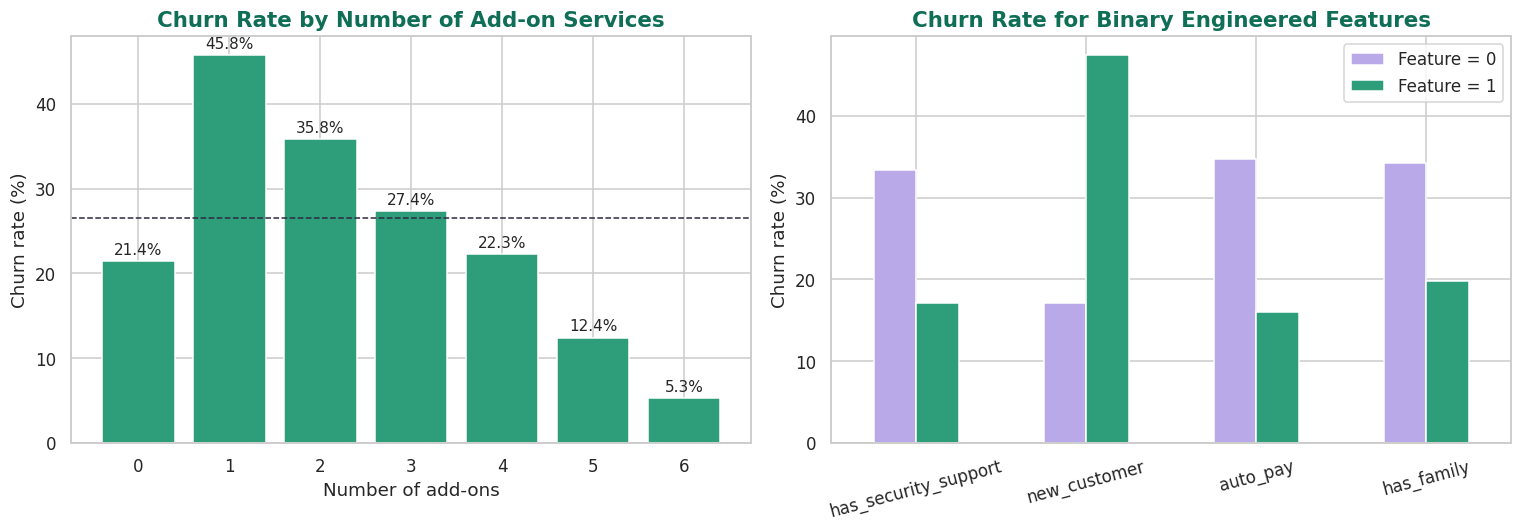

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: churn rate by number of add-ons
rate = df_fe.groupby('num_addons')['Churn_num'].mean().mul(100)
bars = axes[0].bar(rate.index.astype(str), rate.values, color=EMERALD, edgecolor='white')
for b, v in zip(bars, rate.values):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 0.8, f'{v:.1f}%', ha='center', fontsize=10)
axes[0].axhline(overall_churn, color='#2D2A3E', linestyle='--', linewidth=1)
axes[0].set_title('Churn Rate by Number of Add-on Services')
axes[0].set_xlabel('Number of add-ons')
axes[0].set_ylabel('Churn rate (%)')

# Right: churn rate for the four binary engineered features (0 vs 1)
bin_feats = ['has_security_support', 'new_customer', 'auto_pay', 'has_family']
rates = pd.DataFrame({f: df_fe.groupby(f)['Churn_num'].mean() * 100 for f in bin_feats}).T
rates.columns = ['Feature = 0', 'Feature = 1']
rates.plot(kind='bar', ax=axes[1], color=[LAVENDER, EMERALD], rot=15, edgecolor='white')
axes[1].set_title('Churn Rate for Binary Engineered Features')
axes[1].set_ylabel('Churn rate (%)')

plt.tight_layout()
plt.show()

**Observations:**
- **new_customer** has the strongest correlation with churn (r = **+0.32**), stronger than MonthlyCharges (0.19). Churn is 47.4% for new customers versus 17.1% for others.
- **auto_pay** (r = -0.21): churn is 16.0% for automatic payers vs 34.7% for others. **has_security_support** (r = -0.18): 17.1% vs 33.4%. **has_family** (r = -0.16): 19.8% vs 34.2%.
- **num_addons** shows a non-linear pattern. Customers with 0 add-ons churn at 21.4%, but this group includes 1,526 customers with no internet, who rarely churn. Among internet users, churn peaks at **45.8% with just one add-on** and then falls steadily to **5.3% for customers with all six**. Customers who are more deeply bundled are much more loyal.
- Because of this non-linear pattern, tree-based models may use `num_addons` better than a linear model.

## 6.4 Feature Selection and Multicollinearity Check
Not every column should go into the model. We remove columns that carry no predictive value or that duplicate other information. First we check multicollinearity among the numeric features using the Variance Inflation Factor (Section 6.2a). In Chapter 5 we saw that tenure and TotalCharges are strongly correlated (r = 0.83), so we test whether this is a problem.

In [ ]:
from sklearn.linear_model import LinearRegression

def compute_vif(data, cols):
    result = {}
    for c in cols:
        others = [o for o in cols if o != c]
        r2 = LinearRegression().fit(data[others], data[c]).score(data[others], data[c])
        result[c] = round(1 / (1 - r2), 2)
    return pd.Series(result, name='VIF')

print('VIF with TotalCharges included:')
display(compute_vif(df_fe, ['tenure', 'MonthlyCharges', 'TotalCharges']).to_frame())

print('VIF after removing TotalCharges (and adding num_addons):')
display(compute_vif(df_fe, ['tenure', 'MonthlyCharges', 'num_addons']).to_frame())

VIF with TotalCharges included:


,VIF
tenure,5.84
MonthlyCharges,3.22
TotalCharges,9.51


VIF after removing TotalCharges (and adding num_addons):


,VIF
tenure,1.37
MonthlyCharges,2.18
num_addons,2.71


**Observations:**
- With TotalCharges included, its VIF is **9.51** (tenure 5.84, MonthlyCharges 3.22), which is close to the severe level. This confirms the multicollinearity seen in Chapter 5: TotalCharges is mostly tenure × MonthlyCharges.
- After removing TotalCharges, all VIF values fall to about **1.4 to 2.7** (well below 5), so multicollinearity is no longer a concern.

**Feature selection decisions:**

| Column | Decision | Reason |
|---|---|---|
| `customerID` | **Drop** | Identifier only, no predictive meaning |
| `gender` | **Drop** | Not significant (Cramér's V = 0.008, p = 0.49) |
| `PhoneService` | **Drop** | Not significant (V = 0.011, p = 0.34) |
| `TotalCharges` | **Drop** | Redundant (VIF 9.51); its information is contained in tenure and MonthlyCharges |
| `Churn` (text) | **Drop** | Replaced by the numeric target `Churn_num` |
| All other columns | **Keep** | Significant or useful |

In [ ]:
drop_cols = ['customerID', 'gender', 'PhoneService', 'TotalCharges', 'Churn']
df_model = df_fe.drop(columns=drop_cols)
print('Shape after dropping columns:', df_model.shape)
print('Columns:', list(df_model.columns))

Shape after dropping columns: (7043, 22)
Columns: ['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'Churn_num', 'num_addons', 'has_security_support', 'new_customer', 'auto_pay', 'has_family']


## 6.5 Encoding Categorical Variables
Models need numbers, not text. We use two encoding methods:
- **Binary encoding:** Yes/No columns become 1/0.
- **One-hot encoding:** columns with three or more categories (InternetService, Contract, PaymentMethod) become separate 0/1 columns, using k - 1 columns per feature to avoid the dummy variable trap (Section 6.2b).

One-hot encoding is used for Contract even though it has a natural order, because it lets the model learn a separate effect for each contract type without assuming equal spacing between them.

In [ ]:
binary_cols = ['Partner', 'Dependents', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
               'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
               'PaperlessBilling']
for c in binary_cols:
    df_model[c] = df_model[c].map({'Yes': 1, 'No': 0})

df_model = pd.get_dummies(df_model, columns=['InternetService', 'Contract', 'PaymentMethod'],
                          drop_first=True, dtype=int)

y = df_model.pop('Churn_num')
X = df_model

print('Feature matrix shape:', X.shape)
print('Missing values      :', X.isnull().sum().sum())
print('\nFeature columns:')
for i, c in enumerate(X.columns, 1):
    print(f'{i:2d}. {c}')
X.head()

Feature matrix shape: (7043, 25)
Missing values      : 0

Feature columns:
 1. SeniorCitizen
 2. Partner
 3. Dependents
 4. tenure
 5. MultipleLines
 6. OnlineSecurity
 7. OnlineBackup
 8. DeviceProtection
 9. TechSupport
10. StreamingTV
11. StreamingMovies
12. PaperlessBilling
13. MonthlyCharges
14. num_addons
15. has_security_support
16. new_customer
17. auto_pay
18. has_family
19. InternetService_Fiber optic
20. InternetService_No
21. Contract_One year
22. Contract_Two year
23. PaymentMethod_Credit card (automatic)
24. PaymentMethod_Electronic check
25. PaymentMethod_Mailed check


,SeniorCitizen,Partner,Dependents,tenure,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,MonthlyCharges,num_addons,has_security_support,new_customer,auto_pay,has_family,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,0,1,0,0,1,0,0,0,0,1,29.85,1,0,1,0,1,0,0,0,0,0,1,0
1,0,0,0,34,0,1,0,1,0,0,0,0,56.95,2,1,0,0,0,0,0,1,0,0,0,1
2,0,0,0,2,0,1,1,0,0,0,0,1,53.85,2,1,1,0,0,0,0,0,0,0,0,1
3,0,0,0,45,0,1,0,1,1,0,0,0,42.30,3,1,0,1,0,0,0,1,0,0,0,0
4,0,0,0,2,0,0,0,0,0,0,0,1,70.70,0,0,1,0,0,1,0,0,0,0,1,0


**Observations:**
- The final feature matrix has **7,043 rows and 25 numeric features**, with no missing values, and a separate target vector `y` (1 = churn).
- The three multi-category columns became: `InternetService_Fiber optic`, `InternetService_No` (reference = DSL), `Contract_One year`, `Contract_Two year` (reference = month-to-month), and three PaymentMethod columns (reference = bank transfer, automatic).
- Every feature is now numeric: 24 integer (0/1 or count) columns plus the decimal MonthlyCharges.

## 6.6 Train-Test Split
To measure how well a model works on *new* customers, we hold back part of the data that the model never sees during training. We use an **80/20 split** (80% to train, 20% to test) with **stratification**, which keeps the churn proportion the same in both sets. A fixed `random_state` makes the split reproducible.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

split_summary = pd.DataFrame({
    'Rows': [len(X_train), len(X_test)],
    'Churned (1)': [y_train.sum(), y_test.sum()],
    'Stayed (0)': [(y_train == 0).sum(), (y_test == 0).sum()],
    'Churn rate (%)': [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)]
}, index=['Training set', 'Test set'])
display(split_summary)

,Rows,Churned (1),Stayed (0),Churn rate (%)
Training set,5634,1495,4139,26.54
Test set,1409,374,1035,26.54


**Observations:**
- The **training set has 5,634 rows** (1,495 churners and 4,139 non-churners) and the **test set has 1,409 rows** (374 churners and 1,035 non-churners).
- Both sets have exactly the same churn rate of **26.54%**, as in the full dataset, so the test set is a fair representation of reality. The test set is kept untouched until final evaluation (Chapter 8).

## 6.7 Feature Scaling
Features such as tenure (0 to 72) and MonthlyCharges (18 to 119) have different ranges. Models that use distances or gradients (Logistic Regression, SVM, KNN) can be dominated by features with large values. We standardise the three numeric features (tenure, MonthlyCharges, num_addons) using the formula in Section 6.2c. The binary 0/1 features are left as they are.

The scaler learns the mean and standard deviation **from the training set only** (`fit`), and then applies them to both sets (`transform`). Fitting on the full data would leak information from the test set. Tree-based models do not need scaling, so we keep both an unscaled and a scaled version.

,Mean (train),Std dev (train)
tenure,32.49,24.57
MonthlyCharges,64.93,30.14
num_addons,2.06,1.85



Scaled training set, mean and std:


,tenure,MonthlyCharges,num_addons
mean,-0.0,-0.0,0.0
std,1.0,1.0,1.0


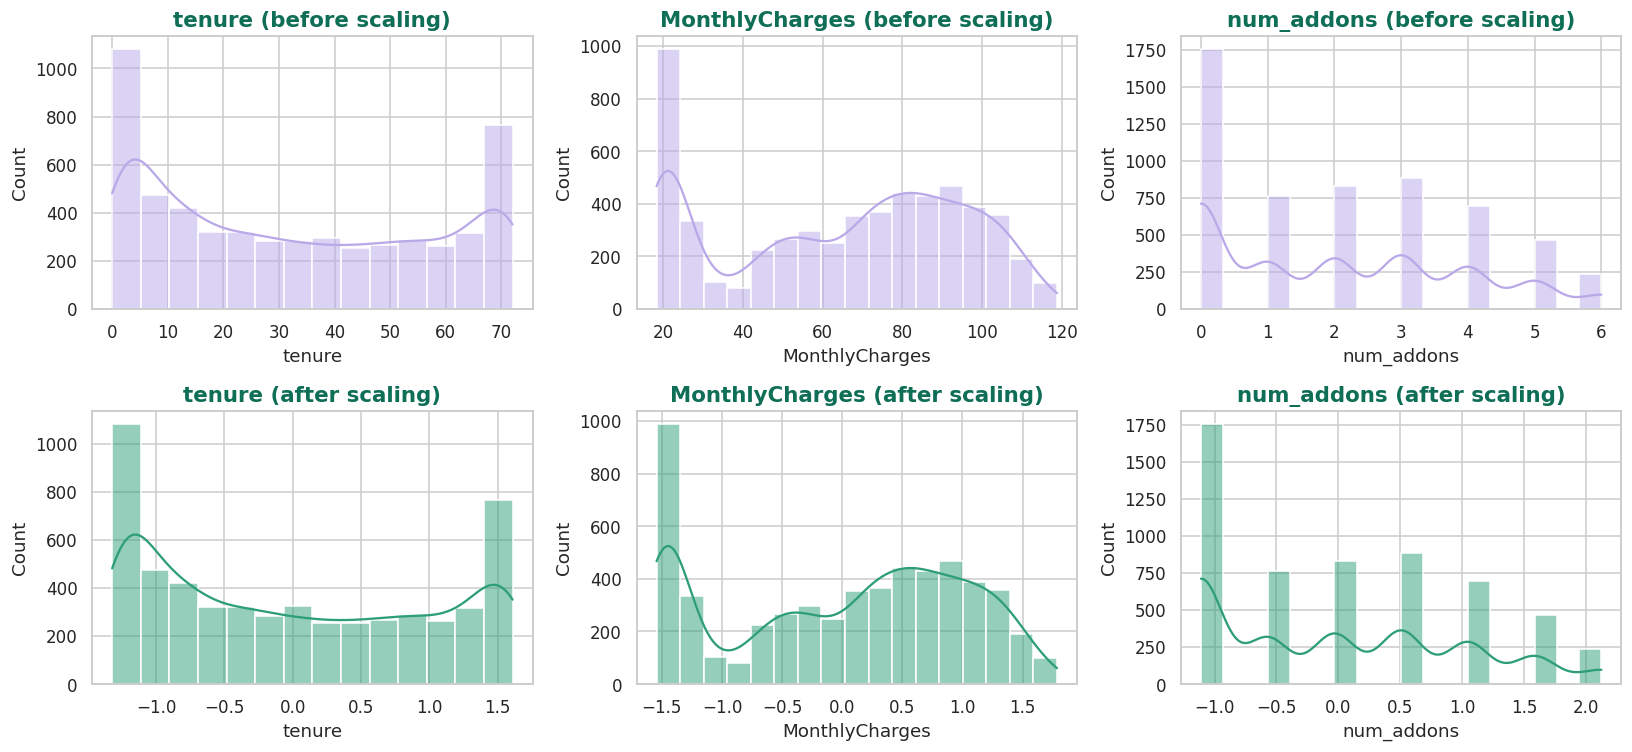

In [ ]:
from sklearn.preprocessing import StandardScaler

num_features = ['tenure', 'MonthlyCharges', 'num_addons']

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_features] = scaler.fit_transform(X_train[num_features])
X_test_scaled[num_features] = scaler.transform(X_test[num_features])

learned = pd.DataFrame({'Mean (train)': scaler.mean_, 'Std dev (train)': scaler.scale_},
                       index=num_features).round(2)
display(learned)

print('\nScaled training set, mean and std:')
display(X_train_scaled[num_features].agg(['mean', 'std']).round(3))

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, c in enumerate(num_features):
    sns.histplot(X_train[c], kde=True, color=LAVENDER, ax=axes[0, i])
    axes[0, i].set_title(f'{c} (before scaling)')
    sns.histplot(X_train_scaled[c], kde=True, color=EMERALD, ax=axes[1, i])
    axes[1, i].set_title(f'{c} (after scaling)')
plt.tight_layout()
plt.show()

**Observations:**
- The scaler learned from the training data: tenure mean ≈ 32.49 (std 24.57), MonthlyCharges mean ≈ 64.93 (std 30.14), num_addons mean ≈ 2.06 (std 1.85).
- After scaling, each of the three features has a **mean of 0 and a standard deviation of 1**. The *shape* of each distribution is unchanged, only the scale on the x-axis moves.
- The test set is scaled with the **training** mean and standard deviation, so its values will be close to, but not exactly, 0 and 1. This is expected and correct.

## 6.8 Handling Class Imbalance
In the training set, 4,139 customers stayed and 1,495 churned, an imbalance ratio of about **2.77 : 1**. A model trained naively may favour the majority class, because predicting "No churn" is already right 73.5% of the time. Since the whole purpose of this project is to find churners, we use two techniques:

1. **Class weights** (Section 6.2e): no change to the data, but errors on churners count more during training. Balanced weights are w(No) = 5,634 / (2 × 4,139) ≈ **0.68** and w(Yes) = 5,634 / (2 × 1,495) ≈ **1.88**.
2. **SMOTE** (Section 6.2f): creates synthetic churner samples until both classes are equal. It is applied **only to the training set**, never to the test set, and it is applied to the *scaled* data because SMOTE relies on distances between points.

We will compare both approaches, and a baseline with no balancing, in Chapter 7 and Chapter 9.

Imbalance ratio (train): 2.77 : 1
Class weights: {0: np.float64(0.6806), 1: np.float64(1.8843)}

Training set before SMOTE: (5634, 25) {0: 4139, 1: 1495}
Training set after SMOTE : (8278, 25) {0: 4139, 1: 4139}


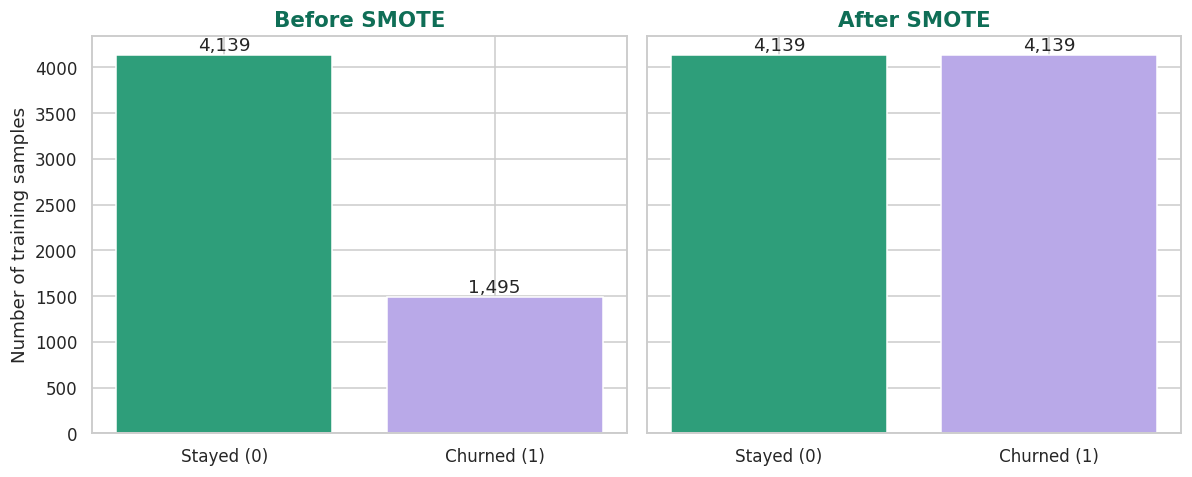

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE   # if missing in Colab: !pip install imbalanced-learn

# 1) Balanced class weights (computed from the training labels)
weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_train)
class_weights = {0: weights[0], 1: weights[1]}
print('Imbalance ratio (train): {:.2f} : 1'.format((y_train == 0).sum() / (y_train == 1).sum()))
print('Class weights:', {k: round(v, 4) for k, v in class_weights.items()})

# 2) SMOTE on the scaled training data only
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print('\nTraining set before SMOTE:', X_train_scaled.shape, y_train.value_counts().to_dict())
print('Training set after SMOTE :', X_train_smote.shape, y_train_smote.value_counts().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, labels, title in zip(axes, [y_train, y_train_smote],
                             ['Before SMOTE', 'After SMOTE']):
    vc = labels.value_counts().sort_index()
    bars = ax.bar(['Stayed (0)', 'Churned (1)'], vc.values, color=[EMERALD, LAVENDER], edgecolor='white')
    for b, v in zip(bars, vc.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 40, f'{v:,}', ha='center')
    ax.set_title(title)
axes[0].set_ylabel('Number of training samples')
plt.tight_layout()
plt.show()

**Observations:**
- The training imbalance ratio is **2.77 : 1**, and the balanced class weights are **0.68 for "Stayed" and 1.88 for "Churned"**. A churner's mistake counts almost 2.8 times as much as a non-churner's.
- SMOTE increases the training set from 5,634 to **8,278 rows**, with **4,139 samples in each class**, by adding 2,644 synthetic churners.
- **Caution:** synthetic points for binary 0/1 columns can take fractional values, such as 0.4, which do not exist in real customers. This is a known limitation of SMOTE with many binary features, which is why we compare it against simple class weighting instead of assuming it is better.
- The test set is **not** changed. It keeps the true 26.5% churn rate, so the final evaluation reflects the real-world situation.

## 6.9 Summary of Preprocessing
| Step | What was done | Result |
|---|---|---|
| Feature engineering | Created `num_addons`, `has_security_support`, `new_customer`, `auto_pay`, `has_family` | 5 new features, `new_customer` strongest (r = 0.32) |
| Multicollinearity | Computed VIF; TotalCharges had VIF 9.51 | TotalCharges dropped; VIFs fall to 1.4-2.7 |
| Feature selection | Dropped `customerID`, `gender`, `PhoneService`, `TotalCharges` | Irrelevant/redundant columns removed |
| Encoding | Binary mapping + one-hot (k-1) for 3 columns | 25 numeric features, no missing values |
| Train-test split | 80/20 stratified, `random_state = 42` | 5,634 train rows, 1,409 test rows, 26.54% churn in both |
| Scaling | Standardised tenure, MonthlyCharges, num_addons using training statistics | Mean 0, std 1; no data leakage |
| Class imbalance | Balanced class weights (0.68 / 1.88) and SMOTE (train only) | Two balancing options ready for comparison |

The data is now ready for model building in Chapter 7. Four versions of the training data are available:
`X_train` (unscaled), `X_train_scaled`, `X_train_smote`, and the test sets `X_test` / `X_test_scaled`.

# Chapter 7: Model Building.

## 7.1 Introduction to Model Building
A machine learning model is a mathematical function that learns the relationship between the input features (customer details) and the target (churn) from past examples, so that it can predict the target for new customers. Our task is **supervised binary classification**, so we choose algorithms that output the probability that a customer will churn.

We build four algorithms of increasing complexity, plus a baseline:

| Model | Why it is included |
|---|---|
| **Baseline (majority class)** | A "do-nothing" reference. Any useful model must beat it |
| **Logistic Regression** | Simple, fast and highly interpretable; the standard benchmark for churn |
| **Decision Tree** | Easy to visualise as if-then rules; captures non-linear interactions |
| **Random Forest** | Many trees averaged together; reduces the overfitting of a single tree |
| **Gradient Boosting** | Trees built one after another, each fixing the previous errors; often the most accurate on tabular data |

Each algorithm is tested with **three imbalance strategies** from Chapter 6: no balancing, class weights, and SMOTE.

## 7.2 Mathematical Foundations of the Models

**(a) Baseline classifier.** It always predicts the majority class ("Stayed"). Its accuracy equals the majority share of the training data, which is 4,139 / 5,634 = 73.5%, while it finds **zero** churners (recall = 0).

**(b) Logistic Regression.** The model first computes a weighted sum of the features, called the log-odds (z):

$$z = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p$$

The **sigmoid function** converts z into a probability between 0 and 1:

$$P(\text{churn}=1 \mid x) = \sigma(z) = \frac{1}{1+e^{-z}}$$

Equivalently, $\ln\frac{p}{1-p} = z$. This gives the model its interpretability: each coefficient β_j changes the log-odds of churn by β_j for a one-unit increase in x_j, so the **odds ratio** is $e^{\beta_j}$. An odds ratio above 1 means the feature raises churn odds, and below 1 means it lowers them. A customer is predicted to churn if p ≥ 0.5.

The coefficients are found by minimising the **weighted log-loss (binary cross-entropy)**, where w is the class weight from Section 6.2e (w = 1 when no weighting is used):

$$J(\beta) = -\frac{1}{N}\sum_{i=1}^{N} w_{y_i}\Big[\,y_i \ln p_i + (1-y_i)\ln(1-p_i)\Big] \;+\; \frac{1}{2C}\sum_{j}\beta_j^2$$

The last term is an **L2 regularisation penalty** that keeps coefficients small and prevents overfitting (C controls its strength; the scikit-learn default is C = 1). Minimisation uses gradient-based optimisation, which repeatedly updates the coefficients in the direction that reduces the loss:

$$\beta \leftarrow \beta - \eta \,\nabla J(\beta)$$

**(c) Decision Tree and Gini impurity.** A tree splits the data again and again with yes/no questions (for example "Is the contract two-year?"). Each split is chosen to make the resulting groups as *pure* as possible, measured by the **Gini impurity**, where p_k is the share of class k in a node:

$$G = 1 - \sum_{k} p_k^{2}$$

A pure node has G = 0, and for two classes the worst case is G = 0.5. A candidate split into a left part (n_L samples) and a right part (n_R samples) is scored by the weighted average impurity of its children, and the split with the lowest score is chosen:

$$G_{split} = \frac{n_L}{n}G_L + \frac{n_R}{n}G_R$$

*Worked example.* In our training set 26.5% of customers churn, so the root node's impurity without weighting is G = 1 - (0.735² + 0.265²) = 1 - (0.540 + 0.070) = **0.390**. With balanced class weights the classes count equally, so the root impurity becomes **0.5**.

**(d) Random Forest.** B trees (here B = 300) are each trained on a random *bootstrap sample* (a sample drawn with replacement) of the training data, and each split only considers a random subset of the features. The forest predicts the average of the trees' probabilities, which reduces variance:

$$\hat{p}(x) = \frac{1}{B}\sum_{b=1}^{B}\hat{p}_b(x)$$

**(e) Gradient Boosting.** Trees are added one at a time. Each new small tree h_m is fitted to the current errors (for log-loss, the residual y - p), and added with a small learning rate ν:

$$F_m(x) = F_{m-1}(x) + \nu \, h_m(x), \qquad p(x) = \sigma\big(F_M(x)\big)$$

We use ν = 0.05 and M = 200 trees of depth at most 3.

**(f) Stratified K-fold cross-validation.** The training set is split into K = 5 parts that keep the churn proportion. The model is trained on 4 parts and scored on the remaining part, five times, so every customer is used for validation once. The reported score is the mean over the folds, and the standard deviation shows how stable the result is:

$$\text{CV score} = \frac{1}{K}\sum_{k=1}^{K}\text{score}_k$$

**(g) Metrics used in this chapter** (full treatment in Chapter 8), where TP, FP, FN and TN are true/false positives and negatives for the churn class:

$$\text{Accuracy}=\frac{TP+TN}{N}\quad \text{Precision}=\frac{TP}{TP+FP}\quad \text{Recall}=\frac{TP}{TP+FN}\quad F_1=\frac{2\cdot\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}$$

**ROC-AUC** is the probability that a randomly chosen churner receives a higher predicted probability than a randomly chosen non-churner. It is 0.5 for random guessing and 1.0 for a perfect ranking.

In [ ]:
import time
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import f1_score, roc_auc_score
from imblearn.pipeline import Pipeline          # allows SMOTE inside a pipeline
from imblearn.over_sampling import SMOTE

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
results = []          # every experiment is stored here

def make_preprocessor():
    # scales the 3 numeric features; the 0/1 columns pass through unchanged
    return ColumnTransformer([('scale', StandardScaler(), num_features)],
                             remainder='passthrough', verbose_feature_names_out=False)

def build_pipeline(model, strategy):
    steps = [('prep', make_preprocessor())]
    if strategy == 'SMOTE':
        steps.append(('smote', SMOTE(random_state=42)))
    steps.append(('clf', model))
    return Pipeline(steps)

def evaluate(name, strategy, model):
    pipe = build_pipeline(model, strategy)
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    row = {'Model': name, 'Strategy': strategy}
    for m in scoring:
        row[m] = scores['test_' + m].mean()
        row[m + '_sd'] = scores['test_' + m].std()
    results.append(row)
    return pd.Series({m: round(row[m], 3) for m in scoring}, name=f'{name} | {strategy}')

print('Setup complete')

Setup complete


## 7.4 Baseline Model
Before building real models, we set a reference point: a classifier that always predicts "Stayed". It shows what accuracy we get with zero learning and why accuracy alone cannot be trusted on this dataset.

In [ ]:
display(evaluate('Baseline (majority)', 'None', DummyClassifier(strategy='most_frequent')).to_frame().T)

,accuracy,precision,recall,f1,roc_auc
Baseline (majority) | None,0.735,0.0,0.0,0.0,0.5


**Observation:** The baseline reaches **73.5% accuracy** without learning anything, but its precision, recall and F1 are all **0** and its ROC-AUC is **0.50** (random). It never identifies a single churner. This confirms that accuracy is misleading here, and that a useful model must be judged mainly on recall, F1 and ROC-AUC.

## 7.5 Model 1: Logistic Regression
Logistic Regression is trained with the three imbalance strategies and scored by cross-validation. We then fit the class-weighted version on the whole training set and read its coefficients, which show how each feature changes the odds of churn.

In [ ]:
lr_runs = [evaluate('Logistic Regression', s,
                    LogisticRegression(max_iter=1000, class_weight=cw, random_state=42))
           for s, cw in [('None', None), ('Class weight', 'balanced'), ('SMOTE', None)]]
display(pd.DataFrame(lr_runs))

,accuracy,precision,recall,f1,roc_auc
Logistic Regression | None,0.805,0.667,0.528,0.589,0.846
Logistic Regression | Class weight,0.749,0.518,0.793,0.626,0.846
Logistic Regression | SMOTE,0.754,0.525,0.781,0.627,0.845


,Feature,Coefficient,Odds ratio
0,Contract_Two year,-1.581,0.206
1,InternetService_No,-1.347,0.260
2,Contract_One year,-0.739,0.478
3,MonthlyCharges,-0.580,0.560
4,tenure,-0.491,0.612


,Feature,Coefficient,Odds ratio
20,PaperlessBilling,0.345,1.412
21,MultipleLines,0.392,1.480
22,num_addons,0.401,1.494
23,new_customer,0.618,1.856
24,InternetService_Fiber optic,1.365,3.917


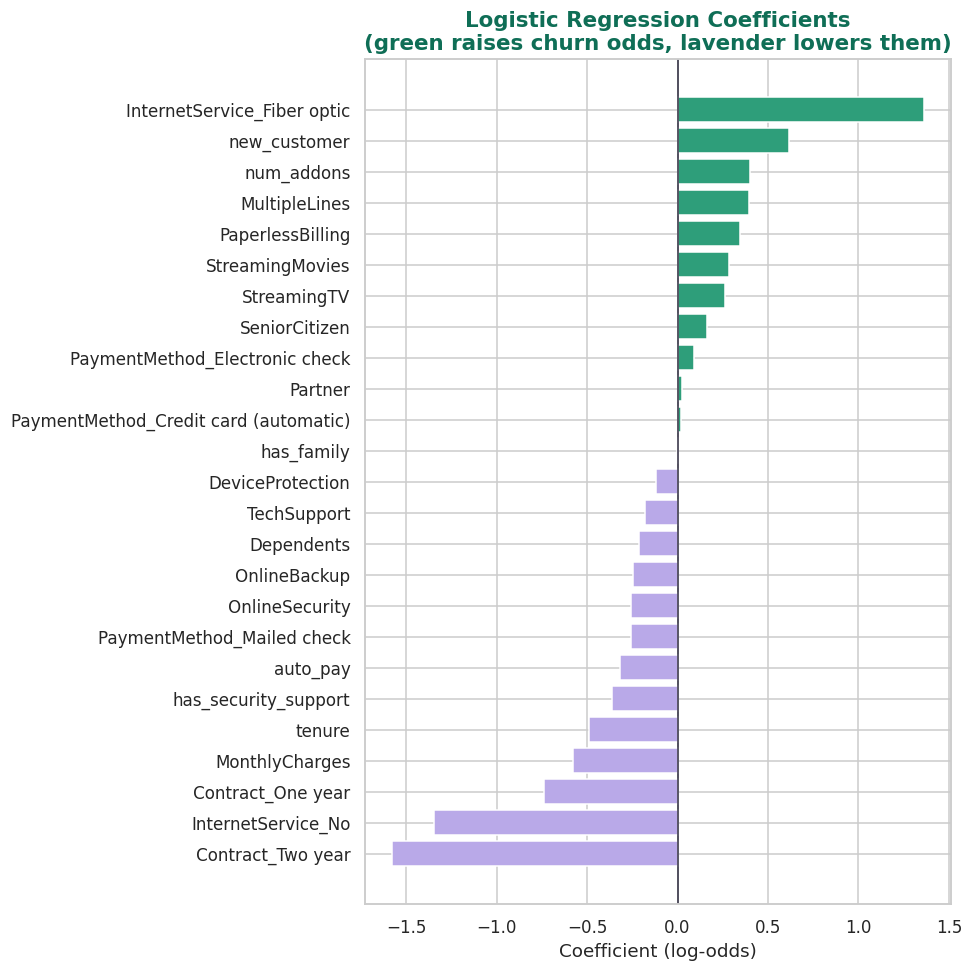

In [ ]:
lr_pipe = build_pipeline(LogisticRegression(max_iter=1000, class_weight='balanced',
                                            random_state=42), 'Class weight').fit(X_train, y_train)
feature_names = lr_pipe.named_steps['prep'].get_feature_names_out()
coef = lr_pipe.named_steps['clf'].coef_[0]

coef_df = (pd.DataFrame({'Feature': feature_names, 'Coefficient': coef,
                         'Odds ratio': np.exp(coef)})
           .sort_values('Coefficient').reset_index(drop=True).round(3))
display(coef_df.head(5))
display(coef_df.tail(5))

plot_df = coef_df.sort_values('Coefficient')
plt.figure(figsize=(9, 9))
plt.barh(plot_df['Feature'], plot_df['Coefficient'],
         color=[LAVENDER if c < 0 else EMERALD for c in plot_df['Coefficient']])
plt.axvline(0, color='#2D2A3E', linewidth=1)
plt.title('Logistic Regression Coefficients\n(green raises churn odds, lavender lowers them)')
plt.xlabel('Coefficient (log-odds)')
plt.tight_layout()
plt.show()

**Observations:**
- **Logistic Regression is already strong.** Without balancing it reaches 80.5% accuracy but finds only **52.8%** of churners (recall). With class weights, recall jumps to **79.3%** (F1 0.626), and SMOTE gives almost the same result (recall 78.1%, F1 0.627). Accuracy falls to about 75% because the model now raises more false alarms (precision about 52%).
- **ROC-AUC is the same in all three versions (about 0.846).** Balancing does not make the model better at *ranking* customers by risk. It mainly shifts where the decision line sits, trading precision for recall.
- **Strongest effects (odds ratios):** `InternetService_Fiber optic` has an odds ratio of **3.92** compared with DSL customers. `new_customer` raises the odds by 1.86 times. A two-year contract multiplies the odds by only **0.21** and a one-year contract by 0.48, compared with month-to-month. Having no internet service multiplies them by 0.26.
- These agree with the EDA findings in Chapter 5, which gives confidence that the model has learned real patterns.
- **Interpret with care:** a coefficient shows the effect of a feature while *holding all others fixed*. For example, `MonthlyCharges` has a negative coefficient even though its raw correlation with churn is positive, because the price is already largely explained by service columns (fiber, add-ons) in the model. Also, `num_addons` is exactly the sum of the six add-on columns, so the coefficients of these related features share their effect between them and should not be read one by one. This does not harm the predictions. We test its effect in Chapter 9.

## 7.6 Model 2: Decision Tree
A decision tree learns a set of if-then rules. We limit the depth to 5 and require at least 20 customers in each leaf, so the tree stays readable and does not memorise the training data. After scoring it, we draw the top of the tree and rank the features by importance.

,accuracy,precision,recall,f1,roc_auc
Decision Tree | None,0.792,0.632,0.529,0.573,0.827
Decision Tree | Class weight,0.730,0.497,0.769,0.602,0.826
Decision Tree | SMOTE,0.747,0.520,0.756,0.613,0.827


Tree nodes: 59 | Leaves: 30 | Depth: 5


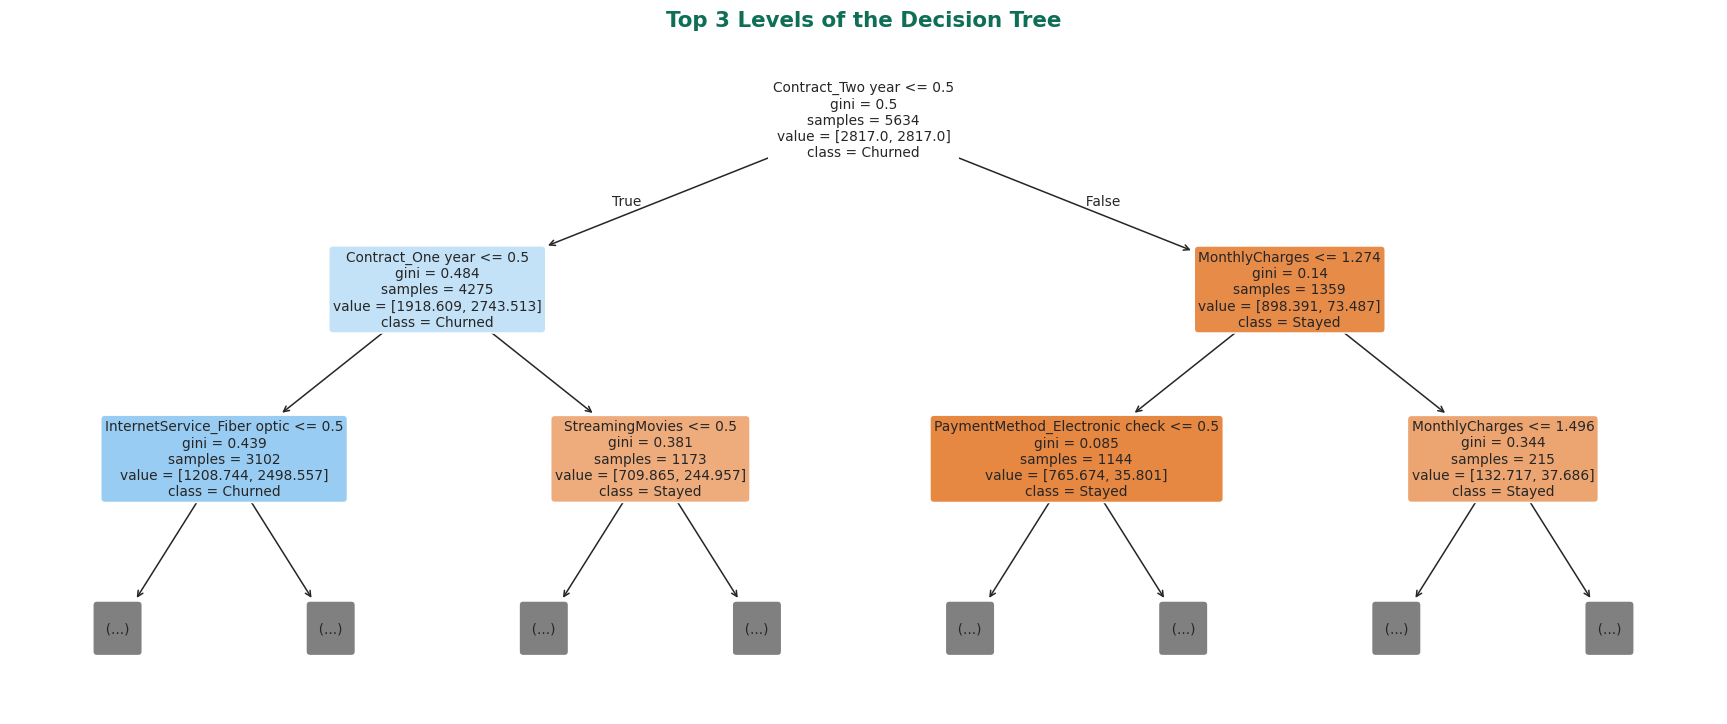

,Importance
Contract_Two year,0.406
Contract_One year,0.254
InternetService_Fiber optic,0.112
tenure,0.104
StreamingMovies,0.035
MonthlyCharges,0.033
PaymentMethod_Electronic check,0.031
InternetService_No,0.015


In [ ]:
dt_runs = [evaluate('Decision Tree', s,
                    DecisionTreeClassifier(max_depth=5, min_samples_leaf=20,
                                           class_weight=cw, random_state=42))
           for s, cw in [('None', None), ('Class weight', 'balanced'), ('SMOTE', None)]]
display(pd.DataFrame(dt_runs))

dt_pipe = build_pipeline(DecisionTreeClassifier(max_depth=5, min_samples_leaf=20,
                                                class_weight='balanced', random_state=42),
                         'Class weight').fit(X_train, y_train)
dt = dt_pipe.named_steps['clf']
print('Tree nodes:', dt.tree_.node_count, '| Leaves:', dt.get_n_leaves(), '| Depth:', dt.get_depth())

fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(dt, feature_names=list(feature_names), class_names=['Stayed', 'Churned'],
          max_depth=2, filled=True, rounded=True, fontsize=9, ax=ax)
plt.title('Top 3 Levels of the Decision Tree')
plt.show()

imp = pd.Series(dt.feature_importances_, index=feature_names).sort_values(ascending=False).head(8)
display(imp.round(3).to_frame('Importance'))

**Observations:**
- With class weights, the tree reaches recall **76.9%** and F1 **0.602**, with ROC-AUC **0.826**. Its ROC-AUC is the **lowest of the four models** (0.827 without weights as well), which is expected for a single, shallow tree.
- The tree has 59 nodes and 30 leaves. The very first split uses `Contract_Two year`, and the next one uses `Contract_One year`. The root node shows an impurity of 0.5 because the class weights make both classes count equally (Section 7.2c).
- **Feature importance:** `Contract_Two year` (0.41) and `Contract_One year` (0.25) together account for about two thirds of the tree's decisions, followed by `InternetService_Fiber optic` (0.11) and `tenure` (0.10). Again this matches the EDA.
- The big advantage of the tree is **explainability**: a retention manager can follow the rules from the root down to each leaf.

## 7.7 Model 3: Random Forest
A Random Forest averages 300 trees, each trained on a different random sample of customers and features. Averaging cancels out the errors of individual trees and usually gives a more stable model than a single tree.

,accuracy,precision,recall,f1,roc_auc
Random Forest | None,0.799,0.664,0.490,0.564,0.843
Random Forest | Class weight,0.779,0.566,0.720,0.633,0.843
Random Forest | SMOTE,0.786,0.584,0.676,0.627,0.837


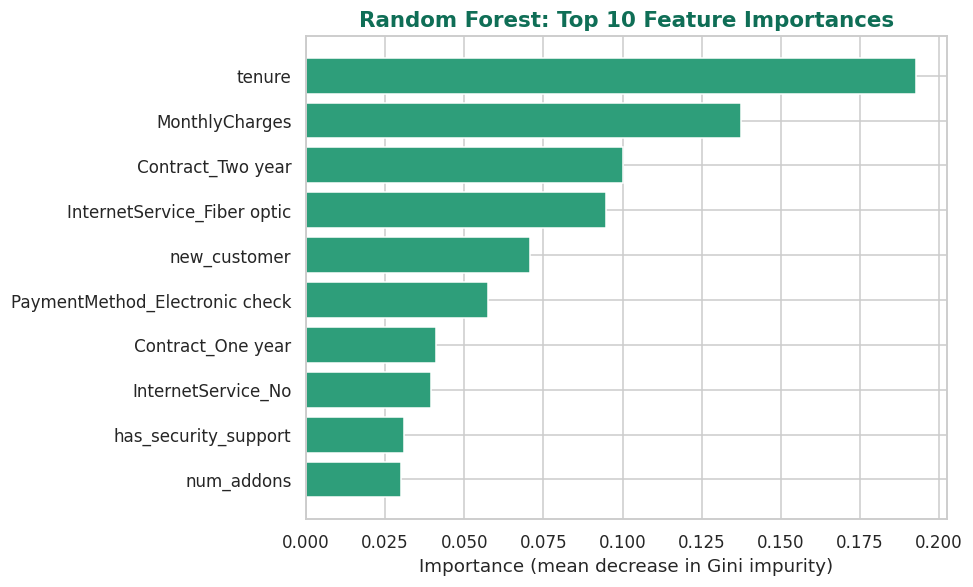

In [ ]:
rf_runs = [evaluate('Random Forest', s,
                    RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                           class_weight=cw, random_state=42, n_jobs=-1))
           for s, cw in [('None', None), ('Class weight', 'balanced'), ('SMOTE', None)]]
display(pd.DataFrame(rf_runs))

rf_pipe = build_pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                class_weight='balanced', random_state=42,
                                                n_jobs=-1), 'Class weight').fit(X_train, y_train)
rf_imp = (pd.Series(rf_pipe.named_steps['clf'].feature_importances_, index=feature_names)
          .sort_values(ascending=False).head(10))

plt.figure(figsize=(9, 5.5))
plt.barh(rf_imp.index[::-1], rf_imp.values[::-1], color=EMERALD)
plt.title('Random Forest: Top 10 Feature Importances')
plt.xlabel('Importance (mean decrease in Gini impurity)')
plt.tight_layout()
plt.show()

**Observations:**
- Random Forest with class weights achieves the **highest F1 of all experiments (0.633)**, with recall **72.0%**, precision 56.6% and the best accuracy among the balanced models (**77.9%**). It is the most "conservative" balanced model: fewer false alarms than Logistic Regression, but it finds fewer churners.
- SMOTE gives a very similar F1 (0.627) but a slightly lower ROC-AUC (0.837), so it brings no benefit over class weighting here.
- **Feature importance:** the forest ranks `tenure` (0.19) and `MonthlyCharges` (0.14) at the top, followed by `Contract_Two year` (0.10), `InternetService_Fiber optic` (0.095) and our engineered `new_customer` (0.07). Importance values from forests tend to favour continuous features, because they offer many possible split points, so this ranking should be read together with the Logistic Regression and tree results.
- The engineered features `has_security_support` (0.031) and `num_addons` (0.030) also appear in the top 10, which shows that the feature engineering of Chapter 6 added useful information.

## 7.8 Model 4: Gradient Boosting
Gradient Boosting builds shallow trees in sequence, each correcting the errors of the ones before it. We use scikit-learn's histogram-based implementation, which is fast and supports class weights directly.

In [ ]:
gb_runs = [evaluate('Gradient Boosting', s,
                    HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, max_depth=3,
                                                   class_weight=cw, random_state=42))
           for s, cw in [('None', None), ('Class weight', 'balanced'), ('SMOTE', None)]]
display(pd.DataFrame(gb_runs))

gb_pipe = build_pipeline(HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200,
                                                        max_depth=3, class_weight='balanced',
                                                        random_state=42),
                         'Class weight').fit(X_train, y_train)

,accuracy,precision,recall,f1,roc_auc
Gradient Boosting | None,0.806,0.675,0.521,0.588,0.848
Gradient Boosting | Class weight,0.750,0.519,0.794,0.627,0.847
Gradient Boosting | SMOTE,0.781,0.572,0.696,0.628,0.845


**Observations:**
- Gradient Boosting has the **highest ROC-AUC of all models (0.848 without balancing, 0.847 with class weights)**, so it ranks customers by churn risk slightly better than the others.
- With class weights it finds **79.4%** of churners (precision 51.9%, F1 0.627), almost identical to Logistic Regression. With SMOTE, recall is 69.6% and precision 57.2%.
- The very small gap between this complex model and the simple Logistic Regression suggests that the relationship between features and churn is mostly simple, and that the dataset's information limit has been nearly reached at ROC-AUC of about 0.85.

## 7.9 Comparison of All Models
We now collect all 13 experiments (baseline + 4 models × 3 strategies) into one table of cross-validated results, written as mean ± standard deviation over the 5 folds. The heatmaps show recall, F1 and ROC-AUC side by side for easy comparison.

,Model,Strategy,accuracy,precision,recall,f1,roc_auc
0,Baseline (majority),None,0.735 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
1,Logistic Regression,None,0.805 ± 0.009,0.667 ± 0.020,0.528 ± 0.038,0.589 ± 0.027,0.846 ± 0.012
2,Logistic Regression,Class weight,0.749 ± 0.017,0.518 ± 0.021,0.793 ± 0.042,0.626 ± 0.027,0.846 ± 0.013
3,Logistic Regression,SMOTE,0.754 ± 0.017,0.525 ± 0.022,0.781 ± 0.040,0.627 ± 0.027,0.845 ± 0.013
4,Decision Tree,None,0.792 ± 0.008,0.632 ± 0.027,0.529 ± 0.061,0.573 ± 0.032,0.827 ± 0.011
5,Decision Tree,Class weight,0.730 ± 0.020,0.497 ± 0.026,0.769 ± 0.046,0.602 ± 0.017,0.826 ± 0.007
6,Decision Tree,SMOTE,0.747 ± 0.029,0.520 ± 0.039,0.756 ± 0.058,0.613 ± 0.021,0.827 ± 0.013
7,Random Forest,None,0.799 ± 0.012,0.664 ± 0.039,0.490 ± 0.021,0.564 ± 0.022,0.843 ± 0.010
8,Random Forest,Class weight,0.779 ± 0.011,0.566 ± 0.017,0.720 ± 0.033,0.633 ± 0.020,0.843 ± 0.010
9,Random Forest,SMOTE,0.786 ± 0.012,0.584 ± 0.023,0.676 ± 0.031,0.627 ± 0.020,0.837 ± 0.011


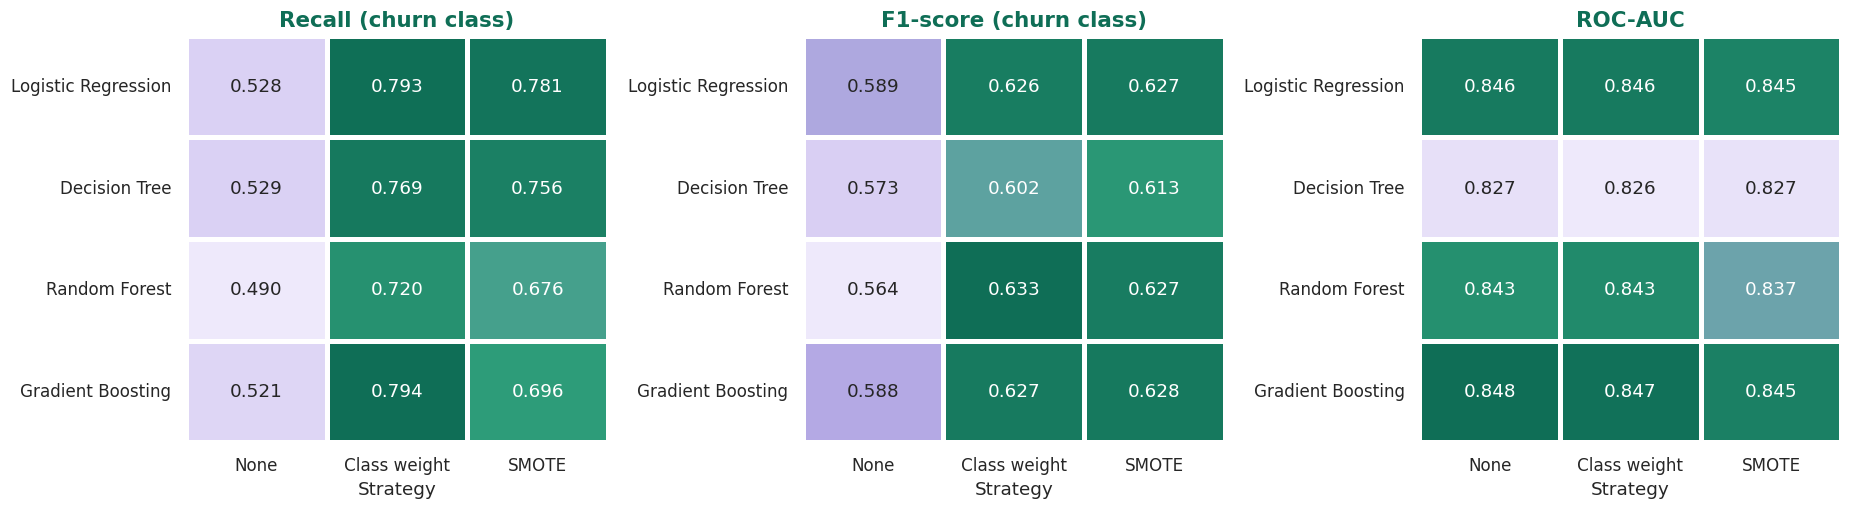

In [ ]:
res = pd.DataFrame(results)

table = res[['Model', 'Strategy']].copy()
for m in scoring:
    table[m] = res.apply(lambda r: f"{r[m]:.3f} ± {r[m + '_sd']:.3f}", axis=1)
display(table)

models_only = res[res['Model'] != 'Baseline (majority)']
order_models = ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting']
order_strat = ['None', 'Class weight', 'SMOTE']

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, metric, title in zip(axes, ['recall', 'f1', 'roc_auc'],
                             ['Recall (churn class)', 'F1-score (churn class)', 'ROC-AUC']):
    pv = models_only.pivot(index='Model', columns='Strategy', values=metric)
    pv = pv.reindex(index=order_models, columns=order_strat)
    sns.heatmap(pv, annot=True, fmt='.3f', cmap=CMAP, linewidths=2, linecolor='white',
                cbar=False, ax=ax)
    ax.set_title(title)
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

**Observations:**
1. **Without balancing, every model misses nearly half the churners.** Their accuracy looks good (79 to 81%), but recall is only 49 to 53%. This is the accuracy trap discussed in Chapter 3.
2. **Class weights and SMOTE raise recall to roughly 68 to 79%**, at the cost of accuracy (about 73 to 78%) and precision (about 50 to 58%). This is the usual recall-precision trade-off. For churn, missing a churner usually costs more than contacting a loyal customer, so this trade-off is acceptable.
3. **ROC-AUC barely changes with the strategy** (for example Logistic Regression 0.846, 0.846, 0.845). Balancing changes *where the cut-off falls*, not *how well customers are ranked*. This is an important point for Chapter 8, where we also study the decision threshold.
4. **Model differences are small.** The best F1 is 0.633 (Random Forest, class weights), but four other combinations lie between 0.626 and 0.628, and the standard deviation across folds is about 0.02. These differences are **within the noise** and cannot be called real. The same holds for ROC-AUC: Gradient Boosting 0.848 vs Logistic Regression 0.846 (fold standard deviation about 0.012).
5. **The Decision Tree is consistently the weakest** (ROC-AUC 0.827), as expected from a single shallow tree.
6. **Class weights and SMOTE perform about equally** (differences of 0.001 to 0.011 in F1, again within the noise). Class weighting is simpler, faster and avoids creating artificial customers, so we use it as the main strategy from here on.

## 7.10 Checking for Overfitting
A model **overfits** when it memorises the training data and performs much worse on new data. We compare each class-weighted model's score on the data it was trained on with its cross-validated score on unseen folds. A large gap warns of overfitting.

,Model,F1 (train),F1 (CV),AUC (train),AUC (CV),F1 gap,AUC gap
0,Logistic Regression,0.632,0.626,0.850,0.846,0.006,0.004
1,Decision Tree,0.620,0.602,0.845,0.826,0.017,0.018
2,Random Forest,0.752,0.633,0.931,0.843,0.119,0.088
3,Gradient Boosting,0.652,0.627,0.873,0.847,0.025,0.025


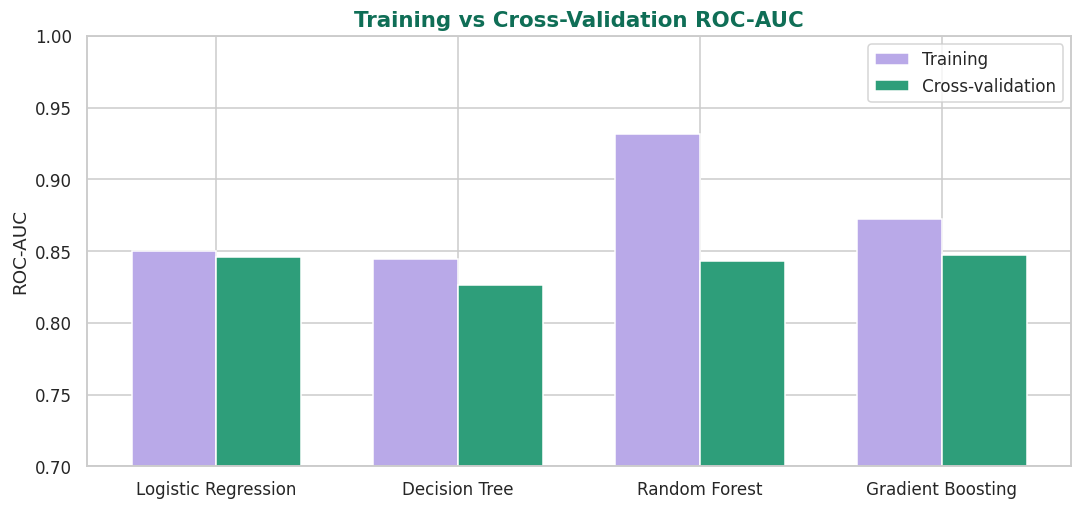

In [ ]:
fitted = {'Logistic Regression': lr_pipe, 'Decision Tree': dt_pipe,
          'Random Forest': rf_pipe, 'Gradient Boosting': gb_pipe}

rows = []
for name, pipe in fitted.items():
    pred = pipe.predict(X_train)
    proba = pipe.predict_proba(X_train)[:, 1]
    cvrow = res[(res['Model'] == name) & (res['Strategy'] == 'Class weight')].iloc[0]
    rows.append([name, f1_score(y_train, pred), cvrow['f1'],
                 roc_auc_score(y_train, proba), cvrow['roc_auc']])

gap = pd.DataFrame(rows, columns=['Model', 'F1 (train)', 'F1 (CV)', 'AUC (train)', 'AUC (CV)'])
gap['F1 gap'] = gap['F1 (train)'] - gap['F1 (CV)']
gap['AUC gap'] = gap['AUC (train)'] - gap['AUC (CV)']
display(gap.round(3))

x = np.arange(len(gap)); w = 0.35
plt.figure(figsize=(10, 4.8))
plt.bar(x - w/2, gap['AUC (train)'], w, color=LAVENDER, label='Training')
plt.bar(x + w/2, gap['AUC (CV)'], w, color=EMERALD, label='Cross-validation')
plt.xticks(x, gap['Model'])
plt.ylim(0.7, 1.0)
plt.ylabel('ROC-AUC')
plt.title('Training vs Cross-Validation ROC-AUC')
plt.legend()
plt.tight_layout()
plt.show()

**Observations:**
- **Logistic Regression shows no overfitting:** F1 is 0.632 on the training data and 0.626 in cross-validation (a gap of 0.006), and the AUC values are 0.850 and 0.846.
- **Random Forest overfits clearly:** its training F1 is 0.752 and AUC 0.931, but the cross-validated values are 0.633 and 0.843. The gap of about **0.12 in F1 and 0.09 in AUC** means it memorises part of the training data, so its true performance is the cross-validated one. Tuning (for example, shallower trees) is a priority in Chapter 9.
- **Gradient Boosting** shows a moderate gap (AUC 0.873 vs 0.847), and the **Decision Tree** a small one (0.845 vs 0.826).
- Judging models only by their training scores would have wrongly made the Random Forest look best, which is why we rely on cross-validation.

## 7.11 Summary of Model Building

| Finding | Detail |
|---|---|
| Baseline | 73.5% accuracy but 0% recall: accuracy alone is useless here |
| Best ranking ability | Gradient Boosting, ROC-AUC 0.848 (Logistic Regression 0.846, Random Forest 0.843, Decision Tree 0.827) |
| Best F1 (churn class) | Random Forest + class weights, 0.633 (others 0.626-0.628, within noise) |
| Highest recall | Gradient Boosting and Logistic Regression + class weights, about 79% |
| Imbalance handling | Class weights and SMOTE perform equally; class weights chosen as the default |
| Overfitting | Random Forest clearly overfits; Logistic Regression does not |
| Interpretability | Logistic Regression coefficients and the tree rules confirm the EDA findings |

**Decision for the next chapters:** all four class-weighted models move forward. In Chapter 8 they are evaluated on the untouched test set with a full set of metrics and the decision threshold is studied. In Chapter 9 we tune the hyperparameters of the most promising models (Gradient Boosting, Random Forest and Logistic Regression) and select the final model.

# Chapter 8: Model Evaluation

## 8.1 Introduction to Model Evaluation
Evaluation answers the question: *how well will the model work on customers it has never seen?* In Chapter 7 we compared models with cross-validation on the training data. Now we evaluate the four class-weighted models on the **held-out test set** (1,409 customers, of whom 374 churned), which was never used for training, scaling, balancing or model comparison.

Rules followed in this chapter:
- The test set is used **only to report performance**. Decisions about thresholds are made on out-of-fold training predictions, never on the test set.
- Model *selection and tuning* in Chapter 9 will rely on cross-validation only, so that the test results stay an honest estimate.
- We do not rely on one number. We look at the confusion matrix, several metrics, curves, uncertainty ranges, the decision threshold, business cost and probability calibration.

## 8.2 Mathematical Foundations of the Evaluation Metrics

**(a) Confusion matrix.** Churn is the *positive* class. Every prediction falls in one of four cells:

| | Predicted: Churn | Predicted: Stay |
|---|---|---|
| **Actually churned** | True Positive (TP): churner correctly caught | False Negative (FN): churner missed |
| **Actually stayed** | False Positive (FP): false alarm | True Negative (TN): loyal customer correctly left alone |

**(b) Basic metrics:**

$$\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN}\qquad \text{Precision}=\frac{TP}{TP+FP}\qquad \text{Recall (TPR)}=\frac{TP}{TP+FN}$$

$$\text{Specificity (TNR)}=\frac{TN}{TN+FP}\qquad \text{FPR}=\frac{FP}{FP+TN}=1-\text{Specificity}$$

Precision answers "of the customers we flag, how many really churn?". Recall answers "of all churners, how many do we catch?".

**(c) F-scores** combine precision (P) and recall (R). F1 is their harmonic mean. The general form F-beta gives recall β times the importance of precision (F2 favours recall):

$$F_1 = \frac{2PR}{P+R} \qquad\qquad F_\beta = (1+\beta^2)\,\frac{P\cdot R}{\beta^2 P + R}$$

**(d) Balanced accuracy and Matthews Correlation Coefficient (MCC)** are summary scores that stay honest under imbalance:

$$\text{Balanced Accuracy}=\frac{\text{Recall}+\text{Specificity}}{2}\qquad MCC=\frac{TP\cdot TN-FP\cdot FN}{\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}}$$

MCC ranges from -1 to +1. A value of 0 means no better than random guessing.

**(e) ROC curve and AUC.** The model outputs a probability, and we predict churn when it is at least a threshold t. Varying t from 1 down to 0 and plotting TPR against FPR gives the ROC curve. The **AUC** is the area under it, and equals the probability that a randomly chosen churner is given a higher score than a randomly chosen non-churner. AUC = 0.5 means random ranking and 1.0 means perfect.

**(f) Precision-Recall curve and Average Precision (AP).** Plotting precision against recall for all thresholds gives the PR curve, summarised by:

$$AP=\sum_{n}(R_n - R_{n-1})\,P_n$$

Unlike ROC-AUC, the PR curve focuses only on the positive (churn) class, and its no-skill baseline equals the churn rate (here 0.265), not 0.5. It is therefore more demanding on imbalanced data.

**(g) Brier score** measures the accuracy of the predicted probabilities themselves (lower is better):

$$\text{Brier}=\frac{1}{N}\sum_{i=1}^{N}(p_i-y_i)^2$$

A model that always predicts the churn rate 0.265 scores 0.265 × 0.735 = **0.195**, which is the reference to beat.

**(h) Bootstrap confidence interval.** To measure uncertainty, we resample the test set with replacement B = 1,000 times, recompute the metric each time, and report the 2.5th and 97.5th percentiles as a 95% interval.

**(i) Expected cost.** Missing a churner is usually more costly than a wasted retention offer. With costs c_FN and c_FP and the ratio r = c_FN / c_FP:

$$\text{Cost}=c_{FN}\cdot FN + c_{FP}\cdot FP$$

For a **well-calibrated** probability the cost-minimising threshold is:

$$t^{*}=\frac{c_{FP}}{c_{FP}+c_{FN}}=\frac{1}{1+r}$$

For r = 5, this gives t* = 1/6 ≈ 0.167.

## 8.3 Confusion Matrices on the Test Set
We predict churn for every test customer whose model probability is at least 0.5, and compare the predictions with what really happened. The confusion matrix shows exactly which kinds of mistakes each model makes.

Test set: (1409, 25) | churners: 374 | stayers: 1035


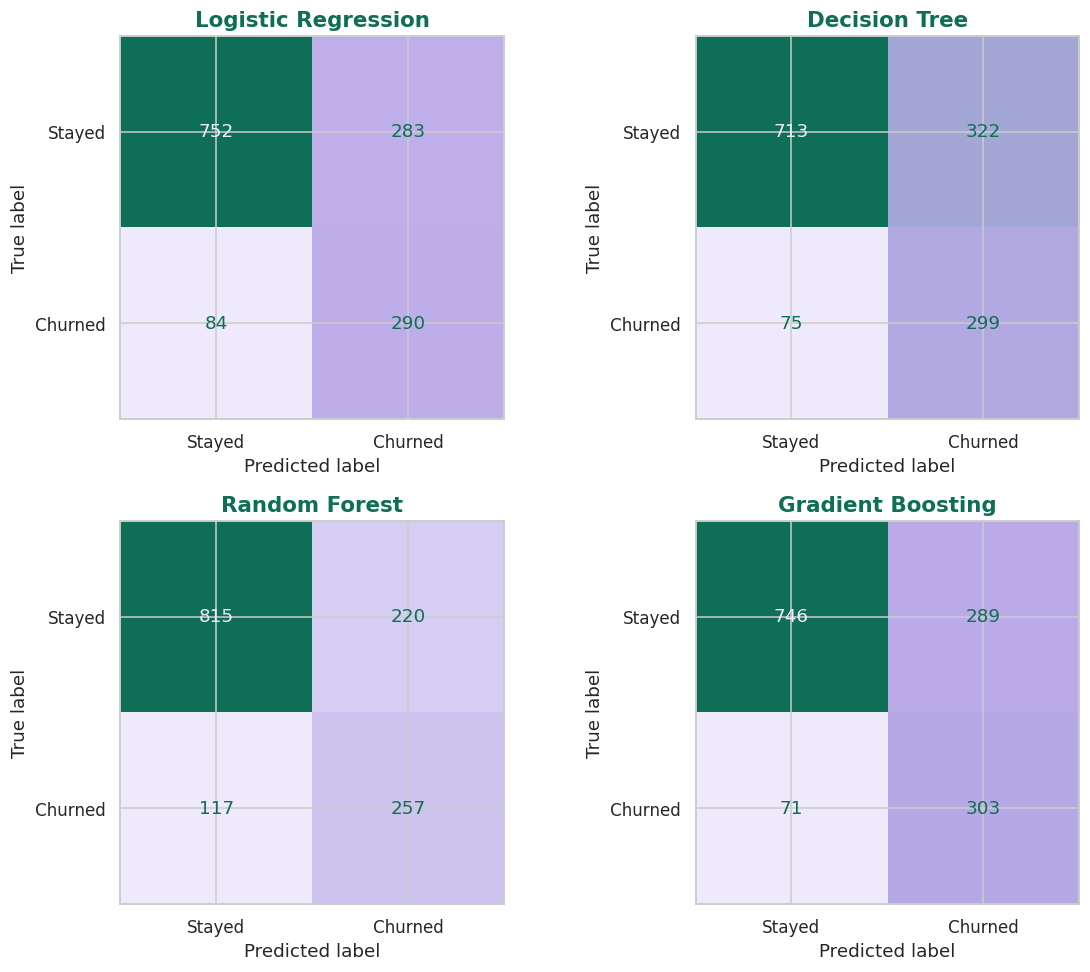

,Model,TP,FP,FN,TN
0,Logistic Regression,290,283,84,752
1,Decision Tree,299,322,75,713
2,Random Forest,257,220,117,815
3,Gradient Boosting,303,289,71,746


In [ ]:
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, fbeta_score, roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    balanced_accuracy_score, matthews_corrcoef, brier_score_loss, ConfusionMatrixDisplay)
from sklearn.model_selection import cross_val_predict
from sklearn.calibration import calibration_curve

candidates = {'Logistic Regression': lr_pipe, 'Decision Tree': dt_pipe,
              'Random Forest': rf_pipe, 'Gradient Boosting': gb_pipe}
colors = {'Logistic Regression': EMERALD, 'Decision Tree': '#B9A9E8',
          'Random Forest': DEEP, 'Gradient Boosting': '#8E7CC3'}

test_proba = {n: p.predict_proba(X_test)[:, 1] for n, p in candidates.items()}
test_pred = {n: (pr >= 0.5).astype(int) for n, pr in test_proba.items()}
print('Test set:', X_test.shape, '| churners:', int(y_test.sum()), '| stayers:', int((y_test == 0).sum()))

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (n, pred) in zip(axes.ravel(), test_pred.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Stayed', 'Churned'],
                                            cmap=CMAP, colorbar=False, ax=ax, values_format='d')
    ax.set_title(n)
plt.tight_layout()
plt.show()

cm_rows = []
for n, pred in test_pred.items():
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    cm_rows.append([n, tp, fp, fn, tn])
display(pd.DataFrame(cm_rows, columns=['Model', 'TP', 'FP', 'FN', 'TN']))

**Observations (test set: 374 churners, 1,035 loyal customers):**
- **Gradient Boosting** catches the most churners: **303 of 374 (81.0%)** and misses only **71**. The price is 289 false alarms (27.9% of loyal customers).
- **Random Forest** raises the fewest false alarms (**220**) but misses the most churners (**117**, so it catches only 68.7%).
- **Logistic Regression** (290 caught, 84 missed, 283 false alarms) and the **Decision Tree** (299 caught, 75 missed, 322 false alarms) sit in between.
- The models differ in *where* they place themselves on the trade-off between catching churners and avoiding false alarms. Whether a trade-off is good depends on the business costs, which we study in Section 8.10.

## 8.4 Full Metric Comparison on the Test Set
We now compute every metric from Section 8.2 for all four models at the standard threshold of 0.5. Looking at several metrics together prevents a misleading picture from any single number.

In [ ]:
rows = []
for n, pred in test_pred.items():
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({'Model': n,
        'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred), 'Specificity': tn / (tn + fp),
        'F1': f1_score(y_test, pred), 'F2': fbeta_score(y_test, pred, beta=2),
        'Balanced Acc': balanced_accuracy_score(y_test, pred), 'MCC': matthews_corrcoef(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, test_proba[n]),
        'PR-AUC': average_precision_score(y_test, test_proba[n]),
        'Brier': brier_score_loss(y_test, test_proba[n])})
test_table = pd.DataFrame(rows).set_index('Model')
display(test_table.round(3))

base_rate = y_test.mean()
print(f'Churn rate in test set: {base_rate:.3f}  |  "always Stay" accuracy: {1 - base_rate:.3f}')

,Accuracy,Precision,Recall,Specificity,F1,F2,Balanced Acc,MCC,ROC-AUC,PR-AUC,Brier
Model,,,,,,,,,,,
Logistic Regression,0.740,0.506,0.775,0.727,0.612,0.701,0.751,0.451,0.841,0.628,0.167
Decision Tree,0.718,0.481,0.799,0.689,0.601,0.706,0.744,0.434,0.829,0.599,0.171
Random Forest,0.761,0.539,0.687,0.787,0.604,0.651,0.737,0.443,0.838,0.642,0.154
Gradient Boosting,0.744,0.512,0.810,0.721,0.627,0.726,0.765,0.475,0.841,0.663,0.165


Churn rate in test set: 0.265  |  "always Stay" accuracy: 0.735


**Observations:**
- **Gradient Boosting has the best overall balance:** recall **0.810**, F1 **0.627**, F2 **0.726**, balanced accuracy **0.765**, MCC **0.475** and PR-AUC **0.663**.
- **Random Forest** has the highest accuracy (0.761), specificity (0.787) and the lowest Brier score (0.154), but its recall (0.687) is the lowest.
- **ROC-AUC is almost identical** for Logistic Regression and Gradient Boosting (**0.841** each), with Random Forest at 0.838 and the Decision Tree lowest at 0.829.
- **All models far exceed the "always Stay" baseline** in the ways that matter. The baseline has 73.5% accuracy but recall 0, whereas these models have an MCC of 0.43 to 0.48 (baseline 0).
- Accuracy (0.72 to 0.76) is *below* the 73.5% of the trivial baseline for two models. This is the deliberate cost of balancing: the models accept more false alarms to catch churners, and accuracy alone would wrongly punish them.

## 8.5 Do the Test Results Agree with Cross-Validation?
If the test scores are close to the cross-validated scores from Chapter 7, the cross-validation was a reliable guide and the models generalise. A big drop would signal overfitting or leakage.

In [ ]:
cv_cw = res[res['Strategy'] == 'Class weight'].set_index('Model')
compare = pd.DataFrame({
    'F1 (CV)': cv_cw['f1'], 'F1 (Test)': test_table['F1'],
    'ROC-AUC (CV)': cv_cw['roc_auc'], 'ROC-AUC (Test)': test_table['ROC-AUC']
}).loc[list(candidates)]
compare['F1 change'] = compare['F1 (Test)'] - compare['F1 (CV)']
compare['AUC change'] = compare['ROC-AUC (Test)'] - compare['ROC-AUC (CV)']
display(compare.round(3))

,F1 (CV),F1 (Test),ROC-AUC (CV),ROC-AUC (Test),F1 change,AUC change
Model,,,,,,
Logistic Regression,0.626,0.612,0.846,0.841,-0.014,-0.005
Decision Tree,0.602,0.601,0.826,0.829,-0.001,0.002
Random Forest,0.633,0.604,0.843,0.838,-0.029,-0.005
Gradient Boosting,0.627,0.627,0.847,0.841,-0.000,-0.006


**Observations:**
- Test results are **close to the cross-validation results**: ROC-AUC moved from 0.846 to 0.841 (Logistic Regression), from 0.847 to 0.841 (Gradient Boosting) and from 0.843 to 0.838 (Random Forest). Gradient Boosting's F1 was identical (0.627 in both).
- **Random Forest shows the largest drop in F1** (0.633 in CV to 0.604 on test), consistent with the overfitting we measured in Section 7.10.
- Small drops of about 0.005 to 0.015 are normal and within the expected sampling noise, so the test set confirms that the pipeline has no data leakage and the models generalise.

## 8.6 ROC and Precision-Recall Curves
The confusion matrix depends on one threshold (0.5). ROC and Precision-Recall curves instead show the model's performance across **all** thresholds, which tells us how well it *ranks* customers by churn risk, independent of where we place the cut-off.

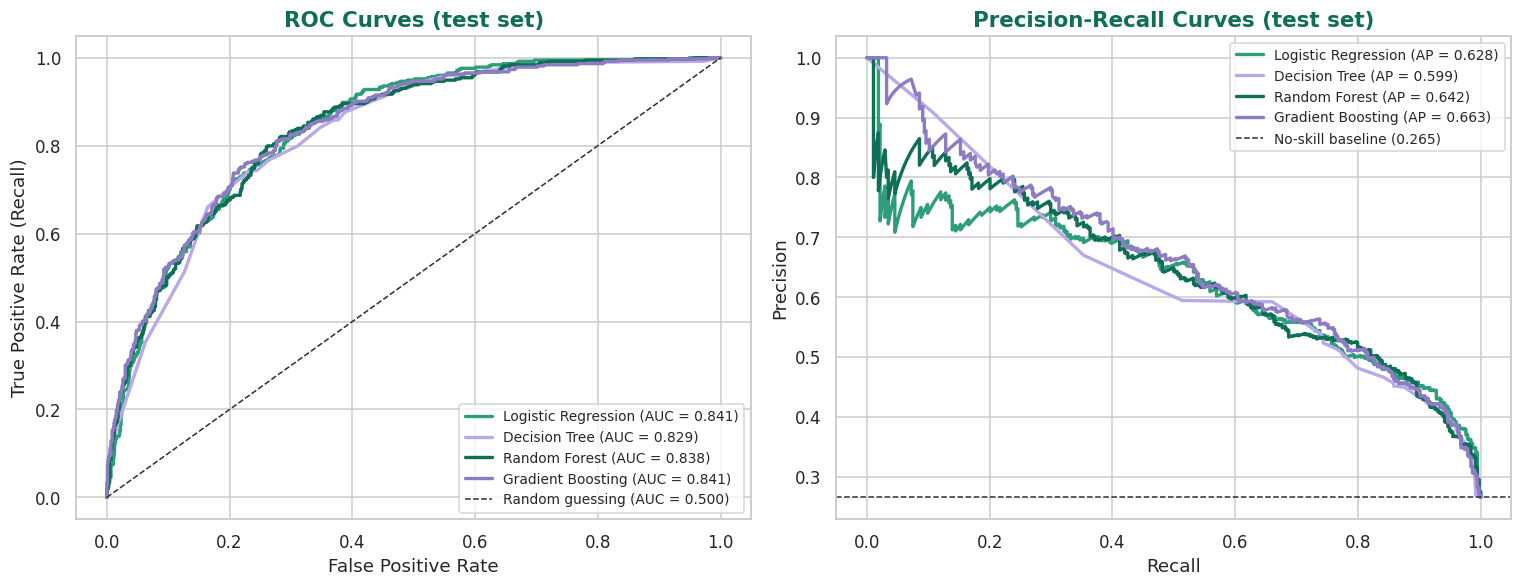

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for n, pr in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, pr)
    axes[0].plot(fpr, tpr, color=colors[n], lw=2.2, label=f'{n} (AUC = {roc_auc_score(y_test, pr):.3f})')
axes[0].plot([0, 1], [0, 1], '--', color='#2D2A3E', lw=1, label='Random guessing (AUC = 0.500)')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].set_title('ROC Curves (test set)')
axes[0].legend(loc='lower right', fontsize=9)

for n, pr in test_proba.items():
    prec, rec, _ = precision_recall_curve(y_test, pr)
    axes[1].plot(rec, prec, color=colors[n], lw=2.2,
                 label=f'{n} (AP = {average_precision_score(y_test, pr):.3f})')
axes[1].axhline(base_rate, ls='--', color='#2D2A3E', lw=1, label=f'No-skill baseline ({base_rate:.3f})')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curves (test set)')
axes[1].legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

**Observations:**
- **The ROC curves of the four models lie very close together**, with AUC between 0.829 and 0.841. All are far above the diagonal (random guessing), so each model separates churners from non-churners well: a randomly chosen churner gets a higher risk score than a randomly chosen loyal customer about **84% of the time**.
- On the **Precision-Recall curves**, Gradient Boosting (AP **0.663**) is highest, followed by Random Forest (0.642), Logistic Regression (0.628) and the Decision Tree (0.599). The no-skill baseline is only 0.265, so the best model is about **2.5 times better than random** at the same recall.
- All curves show the same trade-off: precision falls as recall rises. For example, to catch most churners we must accept that only about half of the flagged customers are real churners.

## 8.7 Uncertainty: Bootstrap Confidence Intervals
A test set of 1,409 customers is a sample, so every metric has some sampling error. The bootstrap method (Section 8.2h) gives a 95% interval around each metric. The same 1,000 resamples are used for all models, which also lets us test whether the *difference* between two models is real.

,Model,Recall,F1,ROC-AUC
0,Logistic Regression,"0.775 [0.732, 0.814]","0.612 [0.574, 0.646]","0.841 [0.819, 0.861]"
1,Decision Tree,"0.799 [0.757, 0.837]","0.601 [0.563, 0.637]","0.829 [0.805, 0.850]"
2,Random Forest,"0.687 [0.640, 0.731]","0.604 [0.562, 0.640]","0.838 [0.816, 0.860]"
3,Gradient Boosting,"0.810 [0.768, 0.848]","0.627 [0.588, 0.661]","0.841 [0.818, 0.863]"


ROC-AUC difference (Gradient Boosting - Logistic Regression): mean 0.0005, 95% CI [-0.008   0.0087]
F1 difference (Random Forest - Logistic Regression): 95% CI [-0.0311  0.0136]


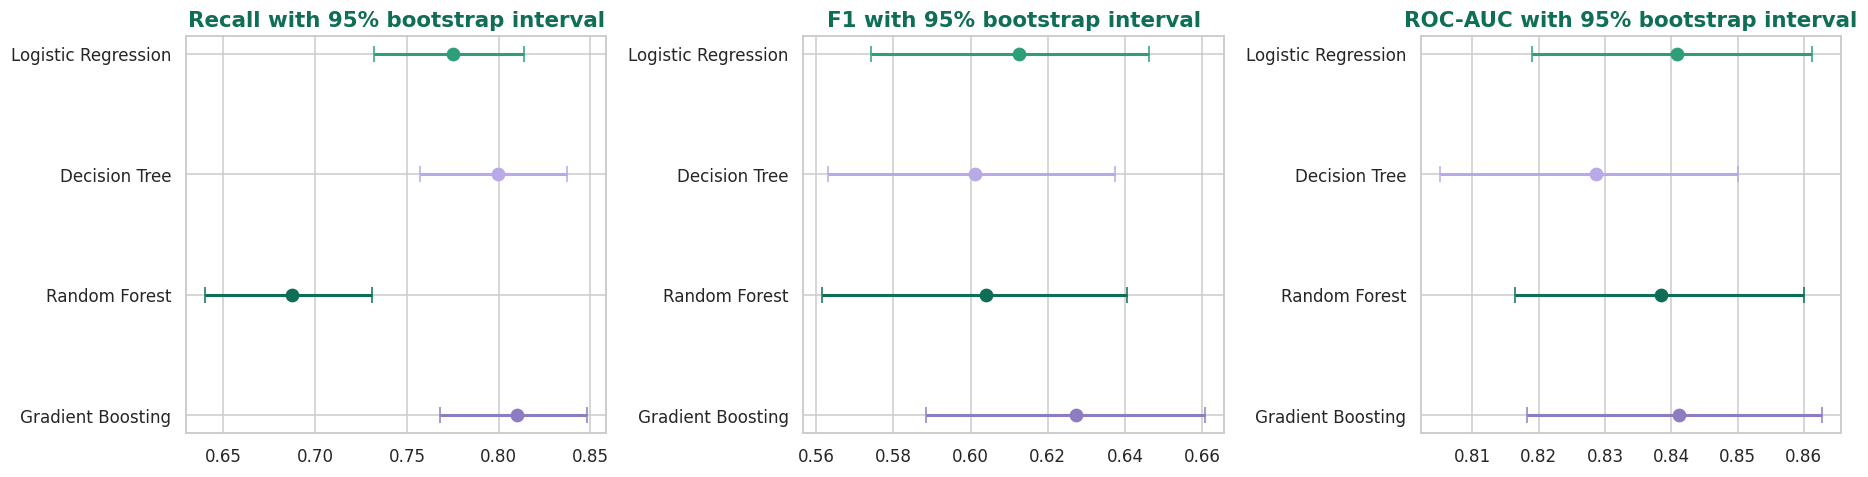

In [ ]:
rng = np.random.default_rng(42)
n_test = len(y_test)
y_arr = y_test.values
boot_idx = [rng.integers(0, n_test, n_test) for _ in range(1000)]

boot = {n: {'Recall': [], 'F1': [], 'ROC-AUC': []} for n in candidates}
for idx in boot_idx:
    yb = y_arr[idx]
    for n in candidates:
        pb = test_proba[n][idx]
        pr = (pb >= 0.5).astype(int)
        boot[n]['Recall'].append(recall_score(yb, pr))
        boot[n]['F1'].append(f1_score(yb, pr))
        boot[n]['ROC-AUC'].append(roc_auc_score(yb, pb))

ci_rows = []
for n in candidates:
    r = {'Model': n}
    for m in ['Recall', 'F1', 'ROC-AUC']:
        lo, hi = np.percentile(boot[n][m], [2.5, 97.5])
        r[m] = f'{test_table.loc[n, m]:.3f}  [{lo:.3f}, {hi:.3f}]'
    ci_rows.append(r)
display(pd.DataFrame(ci_rows))

# Paired differences between models (same resamples)
d_auc = np.array(boot['Gradient Boosting']['ROC-AUC']) - np.array(boot['Logistic Regression']['ROC-AUC'])
d_f1 = np.array(boot['Random Forest']['F1']) - np.array(boot['Logistic Regression']['F1'])
print('ROC-AUC difference (Gradient Boosting - Logistic Regression): mean {:.4f}, 95% CI {}'
      .format(d_auc.mean(), np.percentile(d_auc, [2.5, 97.5]).round(4)))
print('F1 difference (Random Forest - Logistic Regression): 95% CI', np.percentile(d_f1, [2.5, 97.5]).round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, m in zip(axes, ['Recall', 'F1', 'ROC-AUC']):
    for i, n in enumerate(candidates):
        lo, hi = np.percentile(boot[n][m], [2.5, 97.5])
        v = test_table.loc[n, m]
        ax.errorbar(v, i, xerr=[[v - lo], [hi - v]], fmt='o', color=colors[n], capsize=5, lw=2, ms=8)
    ax.set_yticks(range(len(candidates)))
    ax.set_yticklabels(list(candidates))
    ax.invert_yaxis()
    ax.set_title(f'{m} with 95% bootstrap interval')
plt.tight_layout()
plt.show()

**Observations:**
- Each metric has a margin of roughly **±0.02 to ±0.04**. For example, Gradient Boosting's F1 of 0.627 has a 95% interval of **[0.588, 0.661]**, and its ROC-AUC of 0.841 has an interval of **[0.818, 0.863]**.
- **The intervals of the four models overlap heavily** for F1 and ROC-AUC. The paired test confirms this: the ROC-AUC difference between Gradient Boosting and Logistic Regression is about 0.0005, with a 95% interval of **[-0.008, +0.009]**, which includes zero. The F1 difference between Random Forest and Logistic Regression has an interval of **[-0.031, +0.014]**, also including zero.
- **Conclusion:** we cannot claim that any of the three leading models is truly better than the others in ROC-AUC or F1. Only recall differs clearly, as expected from the different operating points: Random Forest's recall interval [0.640, 0.731] lies below those of Gradient Boosting [0.768, 0.848] and the Decision Tree [0.757, 0.837].
- This is an honest and important finding. A simple, explainable Logistic Regression performs as well as the more complex models on this dataset.

## 8.8 Which Evaluation Metric Is Best for This Problem?
No single metric is best in every situation, so the metric must match the goal. Our goal is to find customers likely to churn so that the company can offer them retention incentives, and the data is imbalanced (26.5% churn). The table shows how each metric fits.

| Metric | Verdict | Reason |
|---|---|---|
| **Accuracy** | Not suitable alone | A model that never predicts churn scores 73.5%. It hides the failure to find churners |
| **Precision** | Useful, secondary | Tells us how many retention offers are wasted on loyal customers |
| **Recall** | **Primary metric** | Measures the share of churners we actually catch, which is the purpose of the project |
| **F1 / F2** | **Primary summary** | Combines recall and precision into one number; F2 weights recall more, which suits a case where missing a churner costs more |
| **ROC-AUC** | **Best for comparing models** | Independent of the threshold, measures ranking ability. Can look optimistic on imbalanced data |
| **PR-AUC (AP)** | **Best for comparing models** | Focuses on the churn class and is more sensitive to imbalance than ROC-AUC |
| **MCC / Balanced accuracy** | Good single-number checks | Honest under imbalance; use them to confirm the ranking of models |
| **Expected cost** | **Best for the final decision** | Turns errors into business terms and chooses the operating threshold |
| **Brier score / calibration** | Needed if probabilities are shown | Checks whether a predicted "40% risk" really means 40% |

**Our evaluation strategy:**
1. **Compare models** with the threshold-free metrics **ROC-AUC and PR-AUC**, supported by confidence intervals.
2. **Describe each model's behaviour** at its operating point using **Recall, Precision and F1/F2** (never accuracy alone).
3. **Choose the decision threshold** by **expected cost**, using out-of-fold training predictions.
4. **Check calibration** before reporting probabilities to the business.

## 8.9 Choosing the Decision Threshold
The default threshold of 0.5 is arbitrary. Lowering it flags more customers, which raises recall but lowers precision, and raising it does the opposite. To choose a threshold without touching the test set, we use **out-of-fold predictions on the training set**: each training customer is predicted by a model that did not see that customer, using the same 5 folds as before.

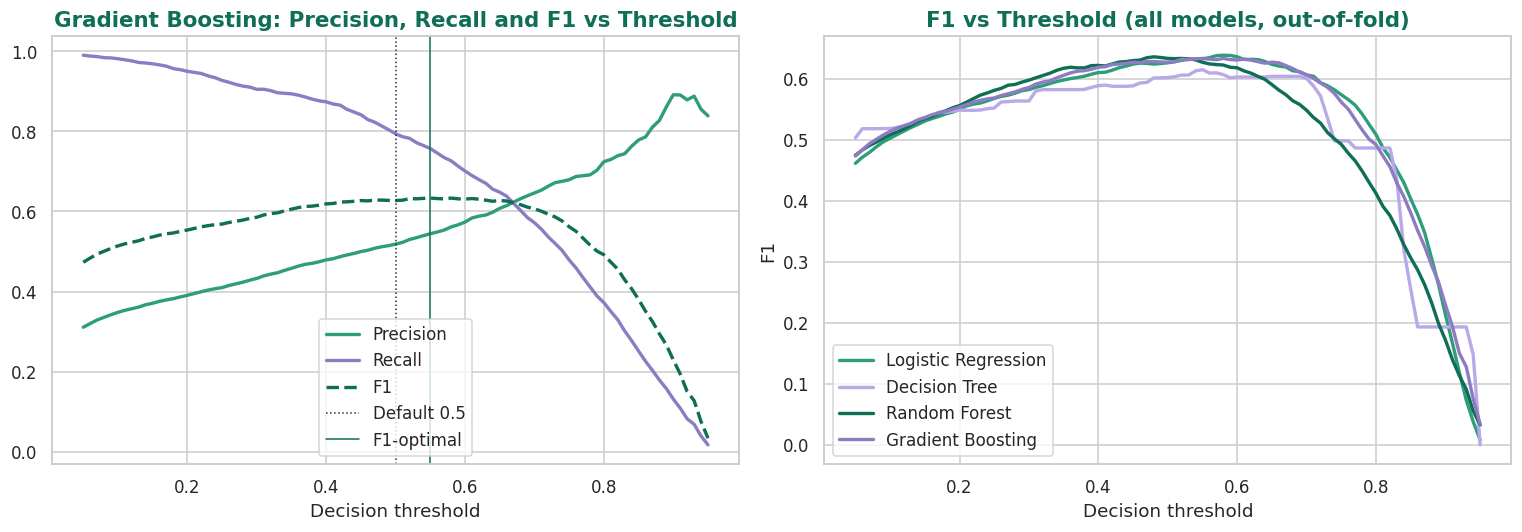

,Model,F1-opt threshold,Precision,Recall,F1 (new),F1 (at 0.5),TP,FP,FN,TN
0,Logistic Regression,0.58,0.548,0.727,0.625,0.612,272,224,102,811
1,Decision Tree,0.55,0.529,0.743,0.618,0.601,278,248,96,787
2,Random Forest,0.48,0.538,0.719,0.616,0.604,269,231,105,804
3,Gradient Boosting,0.55,0.531,0.767,0.628,0.627,287,253,87,782


In [ ]:
oof = {n: cross_val_predict(p, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
       for n, p in candidates.items()}
thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)

def counts(y, proba, t):
    pred = (proba >= t).astype(int)
    y = np.asarray(y)
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    return tp, fp, fn, tn

def f1_at(y, proba, t):
    tp, fp, fn, tn = counts(y, proba, t)
    return 0 if tp == 0 else 2 * tp / (2 * tp + fp + fn)

def prf_curve(y, proba):
    out = []
    for t in thresholds:
        tp, fp, fn, tn = counts(y, proba, t)
        out.append((tp / (tp + fp) if tp + fp else np.nan, tp / (tp + fn), 2 * tp / (2 * tp + fp + fn)))
    return np.array(out)

best_f1_t = {n: thresholds[np.argmax([f1_at(y_train, oof[n], t) for t in thresholds])]
             for n in candidates}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
c = prf_curve(y_train, oof['Gradient Boosting'])
axes[0].plot(thresholds, c[:, 0], color=EMERALD, lw=2.2, label='Precision')
axes[0].plot(thresholds, c[:, 1], color='#8E7CC3', lw=2.2, label='Recall')
axes[0].plot(thresholds, c[:, 2], color=DEEP, lw=2.2, ls='--', label='F1')
axes[0].axvline(0.5, color='#2D2A3E', lw=1, ls=':', label='Default 0.5')
axes[0].axvline(best_f1_t['Gradient Boosting'], color=DEEP, lw=1, label='F1-optimal')
axes[0].set_xlabel('Decision threshold')
axes[0].set_title('Gradient Boosting: Precision, Recall and F1 vs Threshold')
axes[0].legend()
for n in candidates:
    axes[1].plot(thresholds, prf_curve(y_train, oof[n])[:, 2], color=colors[n], lw=2.2, label=n)
axes[1].set_xlabel('Decision threshold'); axes[1].set_ylabel('F1')
axes[1].set_title('F1 vs Threshold (all models, out-of-fold)')
axes[1].legend()
plt.tight_layout()
plt.show()

# Apply the thresholds chosen on training data to the test set
rows = []
for n in candidates:
    t = best_f1_t[n]
    tp, fp, fn, tn = counts(y_test, test_proba[n], t)
    rows.append([n, t, round(tp / (tp + fp), 3), round(tp / (tp + fn), 3),
                 round(f1_at(y_test, test_proba[n], t), 3), round(test_table.loc[n, 'F1'], 3), tp, fp, fn, tn])
display(pd.DataFrame(rows, columns=['Model', 'F1-opt threshold', 'Precision', 'Recall',
                                    'F1 (new)', 'F1 (at 0.5)', 'TP', 'FP', 'FN', 'TN']))

**Observations:**
- The F1-optimal thresholds found on training data are close to 0.5: **0.58** (Logistic Regression), **0.55** (Decision Tree and Gradient Boosting) and **0.48** (Random Forest).
- The F1 curves are **very flat** around the optimum, so moving the threshold changes F1 only slightly. On the test set, F1 improves from 0.612 to 0.625 for Logistic Regression, 0.627 to 0.628 for Gradient Boosting, 0.604 to 0.616 for Random Forest and 0.601 to 0.618 for the Decision Tree.
- The real effect of a threshold is on the **precision-recall balance**: for Gradient Boosting at 0.55, precision is 0.531 and recall 0.767, compared with 0.512 and 0.810 at 0.5.
- Maximising F1 treats a missed churner and a false alarm as equally costly. In practice this is rarely true, so we choose the threshold by business cost next.

## 8.10 Cost-Based Evaluation and Business Value
To choose the operating point we translate errors into cost. We make one clear assumption: **a missed churner (FN) costs 5 times as much as an unnecessary retention offer (FP)**, for example because the lost customer's future revenue is about five times the cost of a discount or a call. Costs are in relative units, with one false alarm = 1 unit. This ratio is an assumption, so we also test other values from 1:1 to 10:1.

Two simple strategies serve as references:
- **Contact nobody:** every churner is missed, so cost = r × (number of churners).
- **Contact everyone:** no churner is missed but every loyal customer receives an offer, so cost = number of loyal customers.

A model is only valuable if it costs **less than both** of these simple strategies.

Test set cost of "contact nobody"  : 1870
Test set cost of "contact everyone": 1035



,Model,Threshold,Customers flagged,TP,FP,FN,Recall,Precision,Cost,Saving vs best simple (%)
0,Logistic Regression,0.34,768,343,425,31,0.917,0.447,580,44.0
1,Decision Tree,0.38,704,321,383,53,0.858,0.456,648,37.4
2,Random Forest,0.27,786,339,447,35,0.906,0.431,622,39.9
3,Gradient Boosting,0.36,725,329,396,45,0.880,0.454,621,40.0


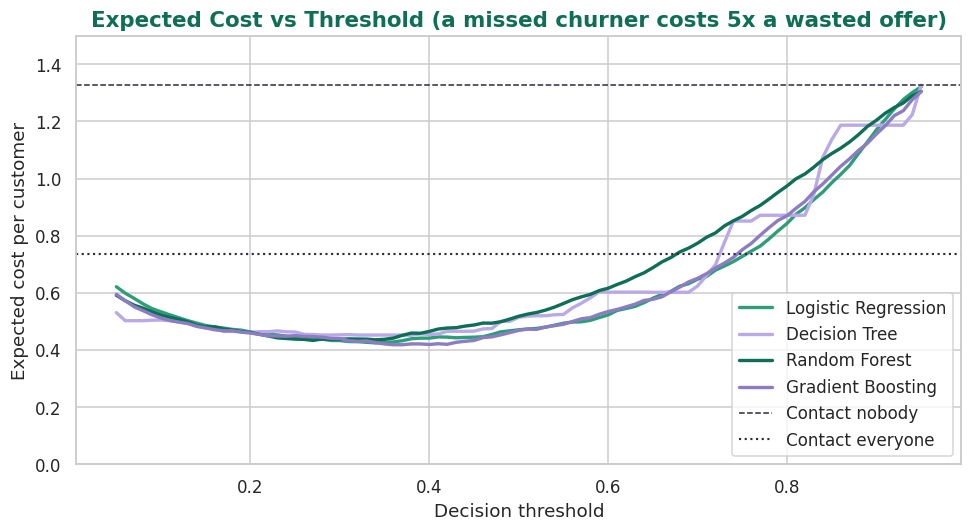

In [ ]:
RATIO = 5   # assumption: a missed churner costs 5x a wasted retention offer

def cost_at(y, proba, t, ratio):
    tp, fp, fn, tn = counts(y, proba, t)
    return ratio * fn + fp

cost_t = {n: thresholds[np.argmin([cost_at(y_train, oof[n], t, RATIO) for t in thresholds])]
          for n in candidates}

n_churn = int(y_test.sum()); n_stay = int((y_test == 0).sum())
print(f'Test set cost of "contact nobody"  : {RATIO * n_churn}')
print(f'Test set cost of "contact everyone": {n_stay}\n')

rows = []
for n in candidates:
    t = cost_t[n]
    tp, fp, fn, tn = counts(y_test, test_proba[n], t)
    cost = RATIO * fn + fp
    rows.append([n, t, tp + fp, tp, fp, fn, round(tp / (tp + fn), 3), round(tp / (tp + fp), 3),
                 cost, round((n_stay - cost) / n_stay * 100, 1)])
display(pd.DataFrame(rows, columns=['Model', 'Threshold', 'Customers flagged', 'TP', 'FP', 'FN',
                                    'Recall', 'Precision', 'Cost', 'Saving vs best simple (%)']))

fig, ax = plt.subplots(figsize=(9, 5))
for n in candidates:
    cc = [cost_at(y_train, oof[n], t, RATIO) / len(y_train) for t in thresholds]
    ax.plot(thresholds, cc, color=colors[n], lw=2.2, label=n)
ax.axhline(RATIO * y_train.mean(), color='#2D2A3E', ls='--', lw=1, label='Contact nobody')
ax.axhline(1 - y_train.mean(), color='#2D2A3E', ls=':', lw=1.4, label='Contact everyone')
ax.set_xlabel('Decision threshold'); ax.set_ylabel('Expected cost per customer')
ax.set_ylim(0, 1.5)
ax.set_title(f'Expected Cost vs Threshold (a missed churner costs {RATIO}x a wasted offer)')
ax.legend()
plt.tight_layout()
plt.show()

**Observations (cost ratio 5:1):**
- On the test set, "contact nobody" costs **1,870** units and "contact everyone" costs **1,035**. Because a missed churner is expensive, contacting everyone is actually the better simple strategy.
- **All four models beat both simple strategies.** At the cost-optimal threshold, Logistic Regression costs **580**, Gradient Boosting **621**, Random Forest **622** and the Decision Tree **648**, savings of **44.0%**, 40.0%, 39.9% and 37.4% compared with contacting everyone.
- The optimal thresholds (about **0.27 to 0.38**) are much **lower than 0.5**. In this setting, even customers with a moderate risk score are worth contacting.
- For Logistic Regression, this means flagging 768 customers (54% of the test set) and catching **91.7% of all churners**, with precision of 44.7%.
- **Consistency check with theory:** for a calibrated model the ideal threshold at r = 5 is 1/6 ≈ 0.167 (Section 8.2i). Class weighting multiplies the odds of churn by about 1.884 / 0.681 ≈ 2.77, which moves 0.167 to roughly **0.357**. This is very close to the thresholds found from the data (0.34 for Logistic Regression, 0.36 for Gradient Boosting), which supports the correctness of the analysis.
- The cost differences between the models (580 vs 621) are small and well within the sampling uncertainty seen in Section 8.7, so they should not be interpreted as a real ranking.

### Sensitivity to the Cost Assumption
Because the 5:1 ratio is an assumption, we repeat the analysis for several ratios. The table shows how the best threshold, the number of customers contacted, and the savings change.

In [ ]:
rows = []
for n in ['Logistic Regression', 'Gradient Boosting']:
    for r in [1, 2, 3, 5, 10]:
        t = thresholds[np.argmin([cost_at(y_train, oof[n], tt, r) for tt in thresholds])]
        tp, fp, fn, tn = counts(y_test, test_proba[n], t)
        model_cost = r * fn + fp
        nobody, everyone = r * n_churn, n_stay
        best_simple = min(nobody, everyone)
        rows.append([n, f'{r}:1', t, tp + fp, round(tp / (tp + fn), 3), model_cost,
                     nobody, everyone, round((best_simple - model_cost) / best_simple * 100, 1)])
sens = pd.DataFrame(rows, columns=['Model', 'FN:FP cost', 'Threshold', 'Customers flagged', 'Recall',
                                   'Model cost', 'Contact nobody', 'Contact everyone',
                                   'Saving vs best simple (%)'])
display(sens)

,Model,FN:FP cost,Threshold,Customers flagged,Recall,Model cost,Contact nobody,Contact everyone,Saving vs best simple (%)
0,Logistic Regression,1:1,0.76,261,0.468,285,374,1035,23.8
1,Logistic Regression,2:1,0.59,487,0.719,428,748,1035,42.8
2,Logistic Regression,3:1,0.46,620,0.821,514,1122,1035,50.3
3,Logistic Regression,5:1,0.34,768,0.917,580,1870,1035,44.0
4,Logistic Regression,10:1,0.21,906,0.957,708,3740,1035,31.6
5,Gradient Boosting,1:1,0.73,288,0.513,278,374,1035,25.7
6,Gradient Boosting,2:1,0.61,448,0.684,428,748,1035,42.8
7,Gradient Boosting,3:1,0.42,659,0.848,513,1122,1035,50.4
8,Gradient Boosting,5:1,0.36,725,0.880,621,1870,1035,40.0
9,Gradient Boosting,10:1,0.16,967,0.965,736,3740,1035,28.9


**Observations:**
- **The models beat both simple strategies at every cost ratio**, with savings of about **24% to 50%** compared with the better of "contact nobody" and "contact everyone".
- **The higher the cost of missing a churner, the lower the threshold and the more customers are contacted.** For Gradient Boosting, at 1:1 only 288 customers are flagged (recall 51%), at 5:1 it is 725 (recall 88%), and at 10:1 it is 967 customers (69% of the test set, recall 96.5%).
- The savings are largest around a ratio of 3:1 (about 50%), because that is where "contact nobody" and "contact everyone" cost about the same and the model can be most selective.
- **Business insight:** the right operating point is a business decision, not just a statistical one. The company should estimate the real values of a retained customer and of a retention offer, and then pick the matching threshold from this table.

## 8.11 Calibration of the Predicted Probabilities
So far we only used the probabilities to rank customers and compare them with thresholds. If the business wants to read them as "this customer has a 60% chance of leaving", they must be **calibrated**, meaning that among customers given about 60%, roughly 60% really churn. A calibration curve compares the predicted probability with the actual churn rate in each probability bin; a perfect model follows the diagonal.

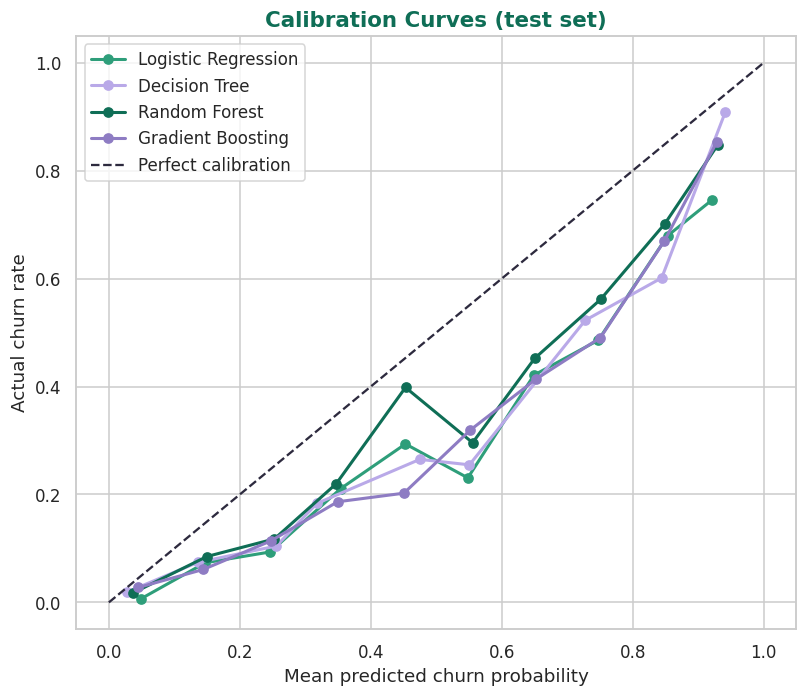

,Mean predicted probability,Actual churn rate
Logistic Regression,0.415,0.265
Decision Tree,0.410,0.265
Random Forest,0.373,0.265
Gradient Boosting,0.408,0.265


Brier score of the constant "always 26.5%" prediction: 0.195


In [ ]:
plt.figure(figsize=(7.5, 6.5))
for n, pr in test_proba.items():
    frac_pos, mean_pred = calibration_curve(y_test, pr, n_bins=10)
    plt.plot(mean_pred, frac_pos, marker='o', color=colors[n], lw=2, label=n)
plt.plot([0, 1], [0, 1], '--', color='#2D2A3E', label='Perfect calibration')
plt.xlabel('Mean predicted churn probability')
plt.ylabel('Actual churn rate')
plt.title('Calibration Curves (test set)')
plt.legend()
plt.tight_layout()
plt.show()

display(pd.DataFrame({'Mean predicted probability': {n: pr.mean() for n, pr in test_proba.items()},
                      'Actual churn rate': y_test.mean()}).round(3))
print('Brier score of the constant "always 26.5%" prediction:', round(base_rate * (1 - base_rate), 3))

**Observations:**
- **All curves lie below the diagonal**, so the models **overestimate** churn probability. The average predicted probability is about **0.37 to 0.42**, while the real churn rate is **0.265**. For example, Logistic Regression gives about 0.45 to a group of customers, but only about 29% of them churn.
- This is a **direct and expected result of class weighting**. Giving churners a higher weight pushes all predicted probabilities upwards.
- The Brier scores (Random Forest 0.154, Gradient Boosting 0.165, Logistic Regression 0.167, Decision Tree 0.171) are all better than the 0.195 of a constant prediction, so the probabilities carry real information.
- **Practical consequence:** the probabilities are fine for **ranking** customers and for threshold decisions (as in Section 8.10), but should **not** be shown to the business as literal churn chances. If real probabilities are needed, a recalibration step (Platt scaling or isotonic regression) must be added. This is included in the deployment plan in Chapter 11.

## 8.12 Summary of Model Evaluation

| Question | Finding |
|---|---|
| Do the models generalise? | Yes. Test ROC-AUC is 0.829 to 0.841, within about 0.01 of cross-validation |
| Which model catches the most churners at threshold 0.5? | Gradient Boosting (recall 0.810, F1 0.627, PR-AUC 0.663) |
| Which model has the fewest false alarms? | Random Forest (220 false alarms), but it misses the most churners (117) |
| Is any model clearly better? | No. Differences in ROC-AUC and F1 are within the 95% bootstrap intervals (about ±0.03) |
| Best metric for comparing models | ROC-AUC and PR-AUC; for operating points, Recall with F1/F2; never accuracy alone |
| Best metric for the business decision | Expected cost (5:1 assumed): models save 37% to 44% versus contacting everyone and 24% to 50% over the cost range 1:1 to 10:1 |
| Best threshold | About 0.35 for a 5:1 cost ratio (class-weighted models); chosen on training data only |
| Are the probabilities trustworthy as percentages? | No. Class weighting inflates them (mean 0.41 vs actual 0.265), so recalibration is needed |

**Next step:** In Chapter 9 we tune the hyperparameters of Gradient Boosting, Random Forest and Logistic Regression using cross-validation only, test the removal of the collinear `num_addons` feature, and select the final model. The test set stays reserved for one last confirmation of that final model.

# Chapter 9: Hyperparameter Tuning and Final Model Selection

## 9.1 Introduction
A model has two kinds of numbers. **Parameters** (such as regression coefficients) are learned from the data during training. **Hyperparameters** (such as the depth of a tree or the strength of regularisation) are chosen by us *before* training and control how flexible the model is. Poor choices cause **underfitting** (too simple) or **overfitting** (memorising the training data).

In this chapter we:
1. Study how key hyperparameters affect performance (validation curves)
2. Search for good settings for three models using cross-validation
3. Test whether the engineered features and the collinear `num_addons` feature help (ablation study)
4. Select the final model with a clear, pre-stated rule
5. Confirm it **once** on the test set, calibrate its probabilities, and fix its operating threshold

All tuning uses **only the training set**. The test set is touched once, for the final model.

## 9.2 Mathematical Foundations

**(a) Bias-variance trade-off.** The expected prediction error of a model splits into three parts:

$$E\big[(y-\hat{f}(x))^2\big] = \underbrace{\text{Bias}^2}_{\text{too simple}} + \underbrace{\text{Variance}}_{\text{too sensitive to the training sample}} + \underbrace{\sigma^2}_{\text{irreducible noise}}$$

Hyperparameters move the model along this trade-off. Too little flexibility gives high bias (underfitting), and too much gives high variance (overfitting). The best setting minimises the *validation* error.

**(b) Regularisation in Logistic Regression.** A penalty on the size of the coefficients limits flexibility. In scikit-learn's form, with log-loss terms ℓ_i, the L1 and L2 versions are:

$$\text{L1: } \min_{\beta}\; \sum_{j}|\beta_j| + C\sum_{i}\ell_i(\beta) \qquad\qquad \text{L2: } \min_{\beta}\; \tfrac{1}{2}\sum_{j}\beta_j^2 + C\sum_{i}\ell_i(\beta)$$

A **smaller C means a stronger penalty**. L2 shrinks all coefficients smoothly, while **L1 can shrink some coefficients exactly to zero**, which performs automatic feature selection.

**(c) Size of the search.** In a **grid search**, every combination is tried, so the number of configurations is the product of the number of options per hyperparameter, and the number of model fits is that number times K folds. In a **random search**, only n random combinations are tried. If 5% of all combinations are "very good", then the chance that at least one of n random trials lands in that top 5% is:

$$P = 1 - 0.95^{\,n} \qquad\Rightarrow\qquad n=20:\; 64\% \qquad n=40:\; 87\%$$

Random search is much cheaper than a full grid for models with many hyperparameters, and works well because many settings perform almost equally well.

**(d) Optimism of the best score.** Choosing the best of many configurations on the same cross-validation scores makes the winning score slightly too optimistic (a "winner's curse"). This is why a separate, untouched test set is needed for an honest final estimate.

**(e) One-standard-error rule.** Cross-validation gives a mean score and a standard deviation s over K folds. The standard error of the mean is:

$$SE = \frac{s}{\sqrt{K}}$$

Rule: among all models whose score is within one SE of the best score, choose the **simplest** one. If differences are smaller than the noise, extra complexity is not justified.

**(f) Platt scaling (sigmoid calibration).** If a model gives a raw score s (the log-odds), calibration learns two numbers A and B on held-out data so that the output matches real frequencies:

$$p_{cal} = \frac{1}{1+e^{-(A\,s+B)}}$$

For a calibrated probability, the cost-minimising threshold is t* = 1 / (1 + r), where r = c_FN / c_FP (Section 8.2i).

## 9.3 Tuning Strategy
**Tuning metric: ROC-AUC.** We tune for ROC-AUC because it measures ranking quality *independently of the decision threshold*. The threshold is chosen separately in Chapter 8 and 9.10, and class weights shift thresholds, so tuning directly on F1 would mix two different decisions. PR-AUC, F1 and recall are recorded as well. All searches use the same 5 stratified folds as before and the class-weighted setting chosen in Chapter 7.

| Model | Search type | Hyperparameters and options | Combinations | Tried |
|---|---|---|---|---|
| Logistic Regression | Grid | C (9 values from 0.001 to 100) × penalty (L1, L2) | 18 | 18 (90 fits) |
| Random Forest | Random | trees (100, 200, 300), max depth (3 to 10, None), min leaf size (1 to 40), max features (sqrt, 0.3, 0.5), class-weight mode (2) | 756 | 20 |
| Gradient Boosting | Random | learning rate (0.01 to 0.1), iterations (100 to 500), max depth (2, 3, 4, None), min leaf size (20, 40, 80), L2 penalty (0 to 10), max leaf nodes (8, 15, 31) | 2,304 | 40 |

The Decision Tree is dropped here: it was clearly the weakest model in Chapters 7 and 8.

## 9.4 Validation Curves: How Hyperparameters Affect Fit
A validation curve shows training and cross-validated scores while *one* hyperparameter varies. The gap between the two curves reveals underfitting (both low) and overfitting (training high, validation lower). We look at the regularisation strength C for Logistic Regression and the maximum depth for Random Forest.

In [ ]:
# Chapter 9 setup: imports and a check of variables from earlier chapters
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline      # the imblearn Pipeline, as in Chapter 7

required = ['X_train', 'X_test', 'y_train', 'y_test', 'num_features', 'cv',
            'make_preprocessor', 'res', 'test_table', 'CMAP', 'EMERALD', 'LAVENDER', 'DEEP']
missing = [v for v in required if v not in globals()]
print('Missing variables:', missing if missing else 'none, you are ready to run Cell 6')

Missing variables: ['X_train', 'X_test', 'y_train', 'y_test', 'num_features', 'cv', 'make_preprocessor', 'res', 'test_table', 'CMAP', 'EMERALD', 'LAVENDER', 'DEEP']


**Observations:**
- **Logistic Regression:** with very strong regularisation (C = 0.0001) the model **underfits** (CV AUC 0.834). AUC rises as C increases and **levels off at about 0.846 from C = 1 onwards**. The gap between training (0.850) and validation (0.846) stays tiny, so this model barely overfits and needs little regularisation.
- **Random Forest:** very shallow trees (depth 2) underfit (CV AUC 0.836). CV AUC peaks at **depth 6 to 8 (about 0.846)**. Beyond that, the training AUC keeps climbing to **0.93** while the CV AUC falls to **0.843**: the forest is **memorising** the training data. This is the overfitting seen in Chapter 7 and shows why limiting the depth is the most important Random Forest hyperparameter here.

## 9.5 Hyperparameter Search
We now run the searches described in Section 9.3. Each search tests many settings with 5-fold cross-validation, records ROC-AUC, PR-AUC, F1 and recall, and refits the best setting on the full training set (selected by ROC-AUC). The three searches together take about 4 to 5 minutes.

In [ ]:
# ===== CHAPTER 9 SETUP: rebuilds everything from the CSV (run this FIRST after any restart) =====
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

from sklearn.model_selection import (StratifiedKFold, train_test_split, cross_validate, cross_val_predict,
                                     validation_curve, learning_curve, GridSearchCV, RandomizedSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score, precision_score, f1_score,
                             fbeta_score, confusion_matrix, matthews_corrcoef, brier_score_loss)
from imblearn.pipeline import Pipeline            # the imblearn Pipeline, as in Chapter 7

# ---- colour theme ----
PALETTE = ['#2E9E7A', '#B9A9E8', '#0F6E56', '#8E7CC3', '#7FD1B0', '#D4C9F5']
EMERALD, LAVENDER, DEEP, MINT, PASTEL = '#2E9E7A', '#B9A9E8', '#0F6E56', '#DDF5EA', '#EEE9FB'
sns.set_theme(style='whitegrid', palette=PALETTE)
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': '#FBFAFF', 'axes.edgecolor': '#B9A9E8',
    'axes.labelcolor': '#2D2A3E', 'axes.titlecolor': DEEP, 'axes.titleweight': 'bold', 'axes.titlesize': 14,
    'axes.prop_cycle': cycler(color=PALETTE), 'grid.color': '#E6E0F8', 'xtick.color': '#2D2A3E',
    'ytick.color': '#2D2A3E', 'figure.figsize': (9, 5), 'figure.dpi': 110})
CMAP = LinearSegmentedColormap.from_list('lav_em', ['#EEE9FB', '#B9A9E8', '#2E9E7A', '#0F6E56'])

# ---- load the data (asks for the CSV only if it is not already in Colab) ----
CSV = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
if not os.path.exists(CSV):
    from google.colab import files
    files.upload()                      # choose WA_Fn-UseC_-Telco-Customer-Churn.csv
df = pd.read_csv(CSV)

# ---- Chapter 4: cleaning ----
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.loc[df['tenure'] == 0, 'TotalCharges'] = 0
addon_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df[addon_cols] = df[addon_cols].replace('No internet service', 'No')
df['MultipleLines'] = df['MultipleLines'].replace('No phone service', 'No')

# ---- Chapter 6: features, encoding, split ----
df_fe = df.copy()
df_fe['Churn_num'] = (df_fe['Churn'] == 'Yes').astype(int)
df_fe['num_addons'] = (df_fe[addon_cols] == 'Yes').sum(axis=1)
df_fe['has_security_support'] = ((df_fe['OnlineSecurity'] == 'Yes') | (df_fe['TechSupport'] == 'Yes')).astype(int)
df_fe['new_customer'] = (df_fe['tenure'] <= 12).astype(int)
df_fe['auto_pay'] = df_fe['PaymentMethod'].str.contains('automatic').astype(int)
df_fe['has_family'] = ((df_fe['Partner'] == 'Yes') | (df_fe['Dependents'] == 'Yes')).astype(int)

df_model = df_fe.drop(columns=['customerID', 'gender', 'PhoneService', 'TotalCharges', 'Churn'])
for c in ['Partner', 'Dependents', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
          'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling']:
    df_model[c] = df_model[c].map({'Yes': 1, 'No': 0})
df_model = pd.get_dummies(df_model, columns=['InternetService', 'Contract', 'PaymentMethod'],
                          drop_first=True, dtype=int)
y = df_model.pop('Churn_num')
X = df_model
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
num_features = ['tenure', 'MonthlyCharges', 'num_addons']
overall_churn = y.mean() * 100

# ---- Chapter 7: helpers ----
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def make_preprocessor():
    # scales the 3 numeric features; the 0/1 columns pass through unchanged
    return ColumnTransformer([('scale', StandardScaler(), num_features)],
                             remainder='passthrough', verbose_feature_names_out=False)

# ---- Chapter 7 result needed in 9.5 ("res"): default class-weighted models, 5-fold CV ----
default_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced',
                                            random_state=42, n_jobs=-1),
    'Gradient Boosting': HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, max_depth=3,
                                                        class_weight='balanced', random_state=42)}
res_rows = []
for name, model in default_models.items():
    s = cross_validate(Pipeline([('prep', make_preprocessor()), ('clf', model)]),
                       X_train, y_train, cv=cv, scoring=['roc_auc', 'f1', 'recall'])
    res_rows.append({'Model': name, 'Strategy': 'Class weight',
                     **{k: s['test_' + k].mean() for k in ['roc_auc', 'f1', 'recall']}})
res = pd.DataFrame(res_rows)

# ---- Chapter 8 result needed in 9.9 ("test_table"): untuned Logistic Regression on the test set ----
lr_default = Pipeline([('prep', make_preprocessor()),
                       ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))]
                      ).fit(X_train, y_train)
p0 = lr_default.predict_proba(X_test)[:, 1]
c0 = (p0 >= 0.5).astype(int)
tn0, fp0, fn0, tp0 = confusion_matrix(y_test, c0).ravel()
test_table = pd.DataFrame({'Logistic Regression': {
    'Accuracy': (tp0 + tn0) / len(y_test), 'Precision': precision_score(y_test, c0),
    'Recall': recall_score(y_test, c0), 'Specificity': tn0 / (tn0 + fp0), 'F1': f1_score(y_test, c0),
    'F2': fbeta_score(y_test, c0, beta=2), 'MCC': matthews_corrcoef(y_test, c0),
    'ROC-AUC': roc_auc_score(y_test, p0), 'PR-AUC': average_precision_score(y_test, p0),
    'Brier': brier_score_loss(y_test, p0)}}).T

# ---- check ----
print('X_train:', X_train.shape, '| X_test:', X_test.shape, '| features:', X_train.shape[1])
print('Churn rate train/test: %.2f%% / %.2f%%' % (y_train.mean() * 100, y_test.mean() * 100))
print('Setup finished. You can now run Cells 6, 9, 10, 11 ...')

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv
X_train: (5634, 25) | X_test: (1409, 25) | features: 25
Churn rate train/test: 26.54% / 26.54%
Setup finished. You can now run Cells 6, 9, 10, 11 ...


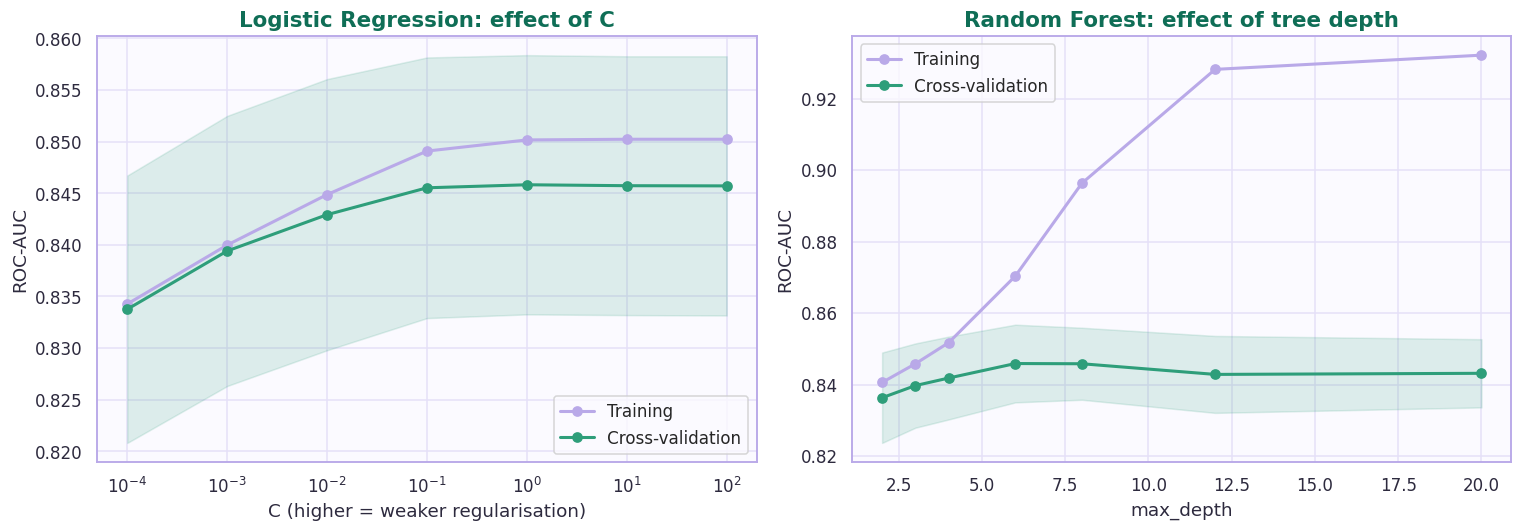

,C,Train AUC,CV AUC
0,0.0001,0.8343,0.8338
1,0.0010,0.8400,0.8394
2,0.0100,0.8449,0.8429
3,0.1000,0.8491,0.8455
4,1.0000,0.8502,0.8458
5,10.0000,0.8502,0.8457
6,100.0000,0.8502,0.8457


,max_depth,Train AUC,CV AUC
0,2,0.8406,0.8363
1,3,0.8458,0.8397
2,4,0.8517,0.8418
3,6,0.8703,0.8459
4,8,0.8963,0.8458
5,12,0.9282,0.8428
6,20,0.9321,0.8432


In [ ]:
lr_base = Pipeline([('prep', make_preprocessor()),
                    ('clf', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42))])
C_range = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
tr_lr, va_lr = validation_curve(lr_base, X_train, y_train, param_name='clf__C',
                                param_range=C_range, cv=cv, scoring='roc_auc')

rf_base = Pipeline([('prep', make_preprocessor()),
                    ('clf', RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                                   class_weight='balanced', random_state=42, n_jobs=-1))])
depth_range = [2, 3, 4, 6, 8, 12, 20]
tr_rf, va_rf = validation_curve(rf_base, X_train, y_train, param_name='clf__max_depth',
                                param_range=depth_range, cv=cv, scoring='roc_auc')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].semilogx(C_range, tr_lr.mean(1), 'o-', color=LAVENDER, lw=2, label='Training')
axes[0].semilogx(C_range, va_lr.mean(1), 'o-', color=EMERALD, lw=2, label='Cross-validation')
axes[0].fill_between(C_range, va_lr.mean(1) - va_lr.std(1), va_lr.mean(1) + va_lr.std(1),
                     color=EMERALD, alpha=0.15)
axes[0].set_xlabel('C (higher = weaker regularisation)'); axes[0].set_ylabel('ROC-AUC')
axes[0].set_title('Logistic Regression: effect of C'); axes[0].legend()

axes[1].plot(depth_range, tr_rf.mean(1), 'o-', color=LAVENDER, lw=2, label='Training')
axes[1].plot(depth_range, va_rf.mean(1), 'o-', color=EMERALD, lw=2, label='Cross-validation')
axes[1].fill_between(depth_range, va_rf.mean(1) - va_rf.std(1), va_rf.mean(1) + va_rf.std(1),
                     color=EMERALD, alpha=0.15)
axes[1].set_xlabel('max_depth'); axes[1].set_ylabel('ROC-AUC')
axes[1].set_title('Random Forest: effect of tree depth'); axes[1].legend()
plt.tight_layout()
plt.show()

display(pd.DataFrame({'C': C_range, 'Train AUC': tr_lr.mean(1), 'CV AUC': va_lr.mean(1)}).round(4))
display(pd.DataFrame({'max_depth': depth_range, 'Train AUC': tr_rf.mean(1), 'CV AUC': va_rf.mean(1)}).round(4))

In [ ]:
multi = {'roc_auc': 'roc_auc', 'average_precision': 'average_precision', 'f1': 'f1', 'recall': 'recall'}

def top_results(search, k=5):
    r = pd.DataFrame(search.cv_results_)
    cols = [c for c in r.columns if c.startswith('param_')] + \
           ['mean_test_roc_auc', 'std_test_roc_auc', 'mean_test_f1', 'mean_test_recall']
    return (r.sort_values('mean_test_roc_auc', ascending=False)[cols].head(k).round(4)
            .rename(columns=lambda c: c.replace('param_clf__', '')))

lr_grid = GridSearchCV(
    Pipeline([('prep', make_preprocessor()),
              ('clf', LogisticRegression(solver='liblinear', max_iter=2000,
                                         class_weight='balanced', random_state=42))]),
    {'clf__C': [0.001, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 100], 'clf__penalty': ['l1', 'l2']},
    cv=cv, scoring=multi, refit='roc_auc', n_jobs=-1)
lr_grid.fit(X_train, y_train)

print('Best Logistic Regression:', lr_grid.best_params_, '| CV ROC-AUC =', round(lr_grid.best_score_, 4))
display(top_results(lr_grid))

Best Logistic Regression: {'clf__C': 0.3, 'clf__penalty': 'l1'} | CV ROC-AUC = 0.846


,C,penalty,mean_test_roc_auc,std_test_roc_auc,mean_test_f1,mean_test_recall
8,0.3,l1,0.8460,0.0123,0.6259,0.7926
10,1.0,l1,0.8460,0.0125,0.6269,0.7940
9,0.3,l2,0.8458,0.0125,0.6264,0.7926
12,3.0,l1,0.8458,0.0125,0.6257,0.7940
11,1.0,l2,0.8458,0.0125,0.6269,0.7933


In [ ]:
rf_dist = {'clf__n_estimators': [100, 200, 300],
           'clf__max_depth': [3, 4, 5, 6, 8, 10, None],
           'clf__min_samples_leaf': [1, 3, 5, 10, 20, 40],
           'clf__max_features': ['sqrt', 0.3, 0.5],
           'clf__class_weight': ['balanced', 'balanced_subsample']}

rf_search = RandomizedSearchCV(
    Pipeline([('prep', make_preprocessor()),
              ('clf', RandomForestClassifier(random_state=42, n_jobs=1))]),
    rf_dist, n_iter=20, cv=cv, scoring=multi, refit='roc_auc', n_jobs=-1, random_state=42)
rf_search.fit(X_train, y_train)

print('Best Random Forest:', rf_search.best_params_, '| CV ROC-AUC =', round(rf_search.best_score_, 4))
display(top_results(rf_search))

Best Random Forest: {'clf__n_estimators': 300, 'clf__min_samples_leaf': 20, 'clf__max_features': 0.5, 'clf__max_depth': 8, 'clf__class_weight': 'balanced'} | CV ROC-AUC = 0.8471


,n_estimators,min_samples_leaf,max_features,max_depth,class_weight,mean_test_roc_auc,std_test_roc_auc,mean_test_f1,mean_test_recall
16,300,20,0.5,8,balanced,0.8471,0.0111,0.6313,0.7679
3,300,5,0.5,6,balanced_subsample,0.8470,0.0108,0.6301,0.7799
8,300,40,0.5,10,balanced,0.8466,0.0115,0.6337,0.7819
12,200,20,0.3,None,balanced,0.8460,0.0113,0.6320,0.7686
4,100,10,sqrt,8,balanced_subsample,0.8459,0.0106,0.6355,0.7699


**Observations:**
- **Best settings found:**
  - Logistic Regression: L1 penalty, C = 0.3
  - Random Forest: 300 trees, max depth 8, min leaf size 20, max features 50%, balanced class weights
  - Gradient Boosting: learning rate 0.1, only 100 iterations, **max depth 2**, min leaf size 80, no L2 penalty
- **Tuning gains are tiny.** Cross-validated ROC-AUC improved from 0.8458 to **0.8460** (Logistic Regression), from 0.8434 to **0.8471** (Random Forest) and from 0.8471 to **0.8489** (Gradient Boosting). The largest gain, +0.004 for Random Forest, comes from limiting its depth, as the validation curve suggested.
- **Logistic Regression was already almost optimal** at its defaults: C values from 0.3 to 10, with either penalty, all give AUC between 0.8457 and 0.8460.
- **The best Gradient Boosting models all use very shallow trees (depth 2) and few iterations.** Depth-2 trees can capture only simple pairwise interactions, so the data seems to have mostly additive structure. This agrees with the strong result of the simple linear model.
- **Recall changed more than AUC** (Random Forest 0.720 to 0.768, Gradient Boosting 0.794 to 0.815), but recall at a 0.5 threshold depends on the threshold, which we choose separately in Section 9.10.

## 9.6 Final Model Selection Rule
Instead of simply taking the highest score, we apply the **one-standard-error rule** (Section 9.2e). The best cross-validated ROC-AUC defines a margin of one standard error; every model within that margin is considered equally good, and among those we choose the **simplest and most interpretable** one. The rule is fixed *before* looking at test results.

In [ ]:
gb_dist = {'clf__learning_rate': [0.01, 0.03, 0.05, 0.1],
           'clf__max_iter': [100, 200, 300, 500],
           'clf__max_depth': [2, 3, 4, None],
           'clf__min_samples_leaf': [20, 40, 80],
           'clf__l2_regularization': [0, 0.1, 1, 10],
           'clf__max_leaf_nodes': [8, 15, 31]}

gb_search = RandomizedSearchCV(
    Pipeline([('prep', make_preprocessor()),
              ('clf', HistGradientBoostingClassifier(class_weight='balanced', random_state=42))]),
    gb_dist, n_iter=40, cv=cv, scoring=multi, refit='roc_auc', n_jobs=-1, random_state=42)
gb_search.fit(X_train, y_train)

print('Best Gradient Boosting:', gb_search.best_params_, '| CV ROC-AUC =', round(gb_search.best_score_, 4))
display(top_results(gb_search))

Best Gradient Boosting: {'clf__min_samples_leaf': 80, 'clf__max_leaf_nodes': 31, 'clf__max_iter': 100, 'clf__max_depth': 2, 'clf__learning_rate': 0.1, 'clf__l2_regularization': 0} | CV ROC-AUC = 0.8489


,min_samples_leaf,max_leaf_nodes,max_iter,max_depth,learning_rate,l2_regularization,mean_test_roc_auc,std_test_roc_auc,mean_test_f1,mean_test_recall
7,80,31,100,2,0.10,0.0,0.8489,0.0132,0.6337,0.8154
36,20,15,100,2,0.10,0.0,0.8488,0.0132,0.6328,0.8120
26,20,8,100,2,0.10,0.0,0.8488,0.0132,0.6328,0.8120
21,40,8,100,2,0.10,0.0,0.8487,0.0130,0.6322,0.8140
29,20,15,500,4,0.01,10.0,0.8479,0.0114,0.6335,0.8120


**Observations:**
- The best model is Gradient Boosting (CV AUC **0.8489**, standard deviation across folds 0.0132). The standard error is 0.0132 / √5 ≈ **0.0059**, so the acceptance cutoff is **0.8430**.
- **All three models are within one standard error** (Logistic Regression 0.8460, Random Forest 0.8471, Gradient Boosting 0.8489). The differences between them (at most 0.003) are about half the noise level, so no model is demonstrably better.

**Decision:** by the pre-stated rule, we select the simplest model within the margin: **Logistic Regression** (L1 penalty, C = 0.3, balanced class weights). It matches the accuracy of the complex models, is fast, and its coefficients can be explained directly to the business as odds ratios. This also agrees with the bootstrap result of Chapter 8, where Logistic Regression and Gradient Boosting were statistically indistinguishable.

## 9.7 Ablation Study: Do the Engineered Features Help?
An ablation study removes parts of the model to measure their contribution. We test two questions with the tuned Logistic Regression and the tuned Gradient Boosting:
1. Does removing `num_addons` change anything? (It is the exact sum of the six add-on columns, which made it collinear, as noted in Chapter 7.)
2. Do the five engineered features from Chapter 6 add predictive value at all?

In [ ]:
def best_row(search, name):
    r = pd.DataFrame(search.cv_results_)
    b = r.loc[r['rank_test_roc_auc'] == 1].iloc[0]
    return {'Model': name, 'ROC-AUC': b['mean_test_roc_auc'], 'AUC std': b['std_test_roc_auc'],
            'PR-AUC': b['mean_test_average_precision'], 'F1': b['mean_test_f1'],
            'Recall': b['mean_test_recall']}

tuned = pd.DataFrame([best_row(lr_grid, 'Logistic Regression'),
                      best_row(rf_search, 'Random Forest'),
                      best_row(gb_search, 'Gradient Boosting')]).set_index('Model')

default = (res[res['Strategy'] == 'Class weight'].set_index('Model')
           .loc[tuned.index, ['roc_auc', 'f1', 'recall']]
           .rename(columns={'roc_auc': 'ROC-AUC (default)', 'f1': 'F1 (default)',
                            'recall': 'Recall (default)'}))
comparison = pd.concat([default, tuned[['ROC-AUC', 'F1', 'Recall']].add_suffix(' (tuned)'),
                        tuned[['AUC std', 'PR-AUC']]], axis=1)
comparison['AUC gain'] = comparison['ROC-AUC (tuned)'] - comparison['ROC-AUC (default)']
display(comparison.round(4))

,ROC-AUC (default),F1 (default),Recall (default),ROC-AUC (tuned),F1 (tuned),Recall (tuned),AUC std,PR-AUC,AUC gain
Model,,,,,,,,,
Logistic Regression,0.8458,0.6261,0.7926,0.8460,0.6259,0.7926,0.0123,0.6599,0.0002
Random Forest,0.8434,0.6333,0.7197,0.8471,0.6313,0.7679,0.0111,0.6627,0.0037
Gradient Boosting,0.8471,0.6273,0.7940,0.8489,0.6337,0.8154,0.0132,0.6644,0.0018


**Observations:**
- **Removing `num_addons` changes nothing:** ROC-AUC is 0.8461 vs 0.8460 for Logistic Regression and 0.8489 in both cases for Gradient Boosting. The feature carries no extra information, because the six add-on columns already contain it.
- **Removing all five engineered features lowers the scores only slightly:** Logistic Regression AUC drops from 0.8460 to 0.8444 and PR-AUC from 0.6599 to 0.6561, while its F1 and recall are even a little higher (0.628 and 0.798). For Gradient Boosting the AUC changes from 0.8489 to 0.8483. All these differences are far smaller than the standard error of about 0.006.
- **Honest conclusion:** the engineered features do **not measurably improve predictive performance**. The models can already extract the same information from the raw columns. The features remain useful for **interpretation** (for example `new_customer` has an odds ratio of 1.78), but they are not a source of extra accuracy.

**Decisions:** drop `num_addons` (no benefit, and it is collinear with other columns). Keep the other four engineered features because they are harmless and make the model easier to explain. The final model therefore uses **24 features**.

## 9.8 The Final Model: Logistic Regression
We fit the selected model on the whole training set with 24 features. The L1 penalty has an extra benefit: it sets the coefficients of unhelpful features exactly to zero. We then read the remaining coefficients as odds ratios (Section 7.2b). Remember that tenure and MonthlyCharges are standardised, so their odds ratios refer to a change of **one standard deviation**.

In [ ]:
searches = {'Logistic Regression': lr_grid, 'Random Forest': rf_search, 'Gradient Boosting': gb_search}
best_name = max(searches, key=lambda k: searches[k].best_score_)
best_r = pd.DataFrame(searches[best_name].cv_results_).query('rank_test_roc_auc == 1').iloc[0]
se = best_r['std_test_roc_auc'] / np.sqrt(5)
cutoff = best_r['mean_test_roc_auc'] - se

print(f"Best model by CV ROC-AUC : {best_name} ({best_r['mean_test_roc_auc']:.4f})")
print(f"Standard error (std/sqrt(5)): {se:.4f}")
print(f"Acceptance cutoff (best - 1 SE): {cutoff:.4f}\n")

complexity = {'Logistic Regression': 1, 'Random Forest': 3, 'Gradient Boosting': 2}
sel = pd.DataFrame({'CV ROC-AUC': {n: s.best_score_ for n, s in searches.items()},
                    'Complexity rank (1 = simplest)': complexity})
sel['Within 1 SE of best?'] = np.where(sel['CV ROC-AUC'] >= cutoff, 'Yes', 'No')
display(sel.round(4))

Best model by CV ROC-AUC : Gradient Boosting (0.8489)
Standard error (std/sqrt(5)): 0.0059
Acceptance cutoff (best - 1 SE): 0.8430



,CV ROC-AUC,Complexity rank (1 = simplest),Within 1 SE of best?
Logistic Regression,0.8460,1,Yes
Random Forest,0.8471,3,Yes
Gradient Boosting,0.8489,2,Yes


In [ ]:
def prep_for(cols):
    # scale only those numeric features that are present in this feature set
    return ColumnTransformer([('scale', StandardScaler(), [c for c in num_features if c in cols])],
                             remainder='passthrough', verbose_feature_names_out=False)

engineered = ['num_addons', 'has_security_support', 'new_customer', 'auto_pay', 'has_family']
feature_sets = {
    'All 25 features': list(X_train.columns),
    'Without num_addons (24)': [c for c in X_train.columns if c != 'num_addons'],
    'Without all 5 engineered (20)': [c for c in X_train.columns if c not in engineered]}

gb_params = {k.replace('clf__', ''): v for k, v in gb_search.best_params_.items()}
tuned_models = {
    'Logistic Regression (tuned)': lambda: LogisticRegression(solver='liblinear', penalty='l1', C=0.3,
                                    class_weight='balanced', max_iter=2000, random_state=42),
    'Gradient Boosting (tuned)': lambda: HistGradientBoostingClassifier(**gb_params,
                                    class_weight='balanced', random_state=42)}

rows = []
for fs_name, cols in feature_sets.items():
    for m_name, make in tuned_models.items():
        pipe = Pipeline([('prep', prep_for(cols)), ('clf', make())])
        s = cross_validate(pipe, X_train[cols], y_train, cv=cv,
                           scoring=['roc_auc', 'average_precision', 'f1', 'recall'])
        rows.append([fs_name, m_name] + [s['test_' + m].mean() for m in
                     ['roc_auc', 'average_precision', 'f1', 'recall']] + [s['test_roc_auc'].std()])

ablation = pd.DataFrame(rows, columns=['Feature set', 'Model', 'ROC-AUC', 'PR-AUC', 'F1', 'Recall', 'AUC std'])
display(ablation.round(4))

,Feature set,Model,ROC-AUC,PR-AUC,F1,Recall,AUC std
0,All 25 features,Logistic Regression (tuned),0.8460,0.6599,0.6259,0.7926,0.0123
1,All 25 features,Gradient Boosting (tuned),0.8489,0.6644,0.6337,0.8154,0.0132
2,Without num_addons (24),Logistic Regression (tuned),0.8461,0.6598,0.6259,0.7926,0.0122
3,Without num_addons (24),Gradient Boosting (tuned),0.8489,0.6645,0.6336,0.8140,0.0130
4,Without all 5 engineered (20),Logistic Regression (tuned),0.8444,0.6561,0.6280,0.7980,0.0123
5,Without all 5 engineered (20),Gradient Boosting (tuned),0.8483,0.6639,0.6362,0.8234,0.0130


Features set to zero by L1: ['Partner', 'has_family', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check']


,Feature,Coefficient,Odds ratio
0,Contract_Two year,-1.561,0.210
1,InternetService_No,-1.121,0.326
2,Contract_One year,-0.732,0.481
3,tenure,-0.482,0.617
4,auto_pay,-0.398,0.671
5,has_security_support,-0.372,0.690
6,PaymentMethod_Mailed check,-0.345,0.708
7,MonthlyCharges,-0.219,0.804
8,Dependents,-0.200,0.819
9,OnlineSecurity,-0.097,0.908


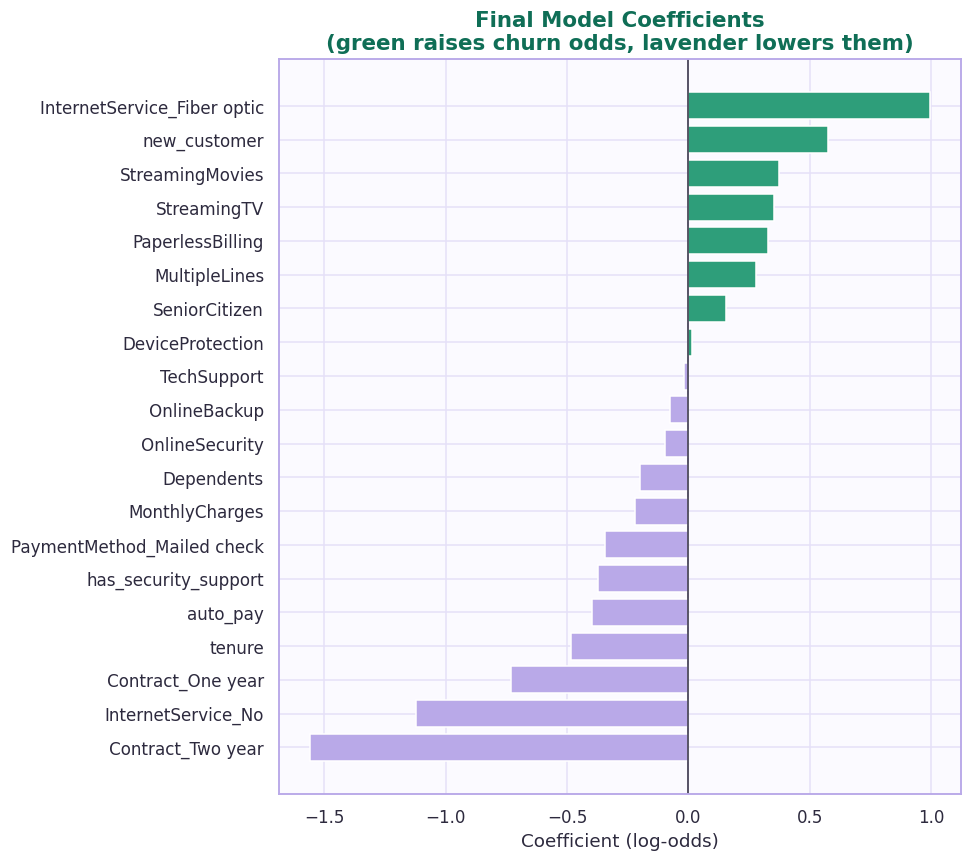

{'CV roc_auc': '0.8461 +/- 0.0122', 'CV average_precision': '0.6598 +/- 0.0145', 'CV f1': '0.6259 +/- 0.0256', 'CV recall': '0.7926 +/- 0.0376'}


In [ ]:
final_features = [c for c in X_train.columns if c != 'num_addons']
Xtr_f, Xte_f = X_train[final_features], X_test[final_features]

final_pipe = Pipeline([('prep', prep_for(final_features)),
                       ('clf', LogisticRegression(solver='liblinear', penalty='l1', C=0.3,
                                                  class_weight='balanced', max_iter=2000,
                                                  random_state=42))]).fit(Xtr_f, y_train)

names = final_pipe.named_steps['prep'].get_feature_names_out()
coef = final_pipe.named_steps['clf'].coef_[0]
coef_final = (pd.DataFrame({'Feature': names, 'Coefficient': coef, 'Odds ratio': np.exp(coef)})
              .sort_values('Coefficient').reset_index(drop=True))
print('Features set to zero by L1:', list(names[coef == 0]))
display(coef_final.round(3))

nz = coef_final[coef_final['Coefficient'] != 0]
plt.figure(figsize=(9, 8))
plt.barh(nz['Feature'], nz['Coefficient'],
         color=[LAVENDER if c < 0 else EMERALD for c in nz['Coefficient']])
plt.axvline(0, color='#2D2A3E', linewidth=1)
plt.title('Final Model Coefficients\n(green raises churn odds, lavender lowers them)')
plt.xlabel('Coefficient (log-odds)')
plt.tight_layout()
plt.show()

s = cross_validate(final_pipe, Xtr_f, y_train, cv=cv, scoring=['roc_auc', 'average_precision', 'f1', 'recall'])
print({k.replace('test_', 'CV '): f'{v.mean():.4f} +/- {v.std():.4f}' for k, v in s.items() if k.startswith('test')})

**Observations:**
- The L1 penalty removed **4 of the 24 features** by setting their coefficients to zero: `Partner`, `has_family`, `PaymentMethod_Electronic check` and `PaymentMethod_Credit card (automatic)`. Their information is already carried by other features (`Dependents`, `auto_pay`, `PaymentMethod_Mailed check`).
- **Strongest churn-increasing factors (odds ratios):** fiber optic internet **2.71** (compared with DSL), new customer (12 months or less) **1.78**, streaming movies 1.45, streaming TV 1.42, paperless billing 1.39 and multiple lines 1.32.
- **Strongest churn-reducing factors:** a two-year contract **0.21** and a one-year contract 0.48 (compared with month-to-month), no internet service 0.33, longer tenure 0.62 per standard deviation, automatic payment 0.67, and having security or tech support 0.69.
- These effects agree with the EDA and the earlier models. The final model is therefore both accurate and **explainable**, which matters if the company needs to justify retention decisions.
- Cross-validation of this final model gives **ROC-AUC 0.8461** (±0.0122), PR-AUC 0.660, F1 0.626 and recall 0.793.

## 9.9 Final Evaluation on the Test Set
This is the one and only evaluation of the final model on the test set. Selection and tuning are complete, so these numbers are an honest estimate of how the model will work on new customers. We also compare with the untuned Logistic Regression from Chapter 8 to see what tuning and feature selection achieved.

In [ ]:
proba_f = final_pipe.predict_proba(Xte_f)[:, 1]
pred_f = (proba_f >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred_f).ravel()

final_row = {'Accuracy': (tp + tn) / len(y_test), 'Precision': precision_score(y_test, pred_f),
             'Recall': recall_score(y_test, pred_f), 'Specificity': tn / (tn + fp),
             'F1': f1_score(y_test, pred_f), 'F2': fbeta_score(y_test, pred_f, beta=2),
             'MCC': matthews_corrcoef(y_test, pred_f), 'ROC-AUC': roc_auc_score(y_test, proba_f),
             'PR-AUC': average_precision_score(y_test, proba_f), 'Brier': brier_score_loss(y_test, proba_f)}

compare = pd.DataFrame({'Final model (tuned, 24 features)': final_row,
                        'Chapter 8: untuned LR (25 features)': test_table.loc['Logistic Regression']}).T
display(compare[['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1', 'F2', 'MCC',
                 'ROC-AUC', 'PR-AUC', 'Brier']].round(3))
print(f'Confusion matrix of the final model:  TP={tp}  FP={fp}  FN={fn}  TN={tn}')

# 95% bootstrap intervals
rng = np.random.default_rng(42)
ya = y_test.values; n = len(ya)
boots = {'ROC-AUC': [], 'PR-AUC': [], 'F1': [], 'Recall': []}
for _ in range(1000):
    i = rng.integers(0, n, n)
    p = (proba_f[i] >= 0.5).astype(int)
    boots['ROC-AUC'].append(roc_auc_score(ya[i], proba_f[i]))
    boots['PR-AUC'].append(average_precision_score(ya[i], proba_f[i]))
    boots['F1'].append(f1_score(ya[i], p))
    boots['Recall'].append(recall_score(ya[i], p))
for m, v in boots.items():
    lo, hi = np.percentile(v, [2.5, 97.5])
    print(f'{m:8s} {final_row[m]:.3f}   95% interval [{lo:.3f}, {hi:.3f}]')

,Accuracy,Precision,Recall,Specificity,F1,F2,MCC,ROC-AUC,PR-AUC,Brier
"Final model (tuned, 24 features)",0.74,0.507,0.786,0.724,0.616,0.708,0.457,0.841,0.626,0.168
Chapter 8: untuned LR (25 features),0.74,0.506,0.775,0.727,0.612,0.701,0.451,0.841,0.628,0.167


Confusion matrix of the final model:  TP=294  FP=286  FN=80  TN=749
ROC-AUC  0.841   95% interval [0.819, 0.861]
PR-AUC   0.626   95% interval [0.573, 0.678]
F1       0.616   95% interval [0.577, 0.651]
Recall   0.786   95% interval [0.743, 0.824]


**Observations:**
- **Test performance of the final model (threshold 0.5):** ROC-AUC **0.841** (95% interval [0.819, 0.861]), PR-AUC **0.626** [0.573, 0.678], recall **0.786** [0.743, 0.824], precision 0.507, F1 **0.616** [0.577, 0.651], F2 0.708, accuracy 0.740 and MCC 0.457.
- It correctly identifies **294 of the 374 churners** and misses 80, at the cost of 286 false alarms among 1,035 loyal customers.
- **Tuning and feature selection made practically no difference on the test set:** the untuned Chapter 8 Logistic Regression had ROC-AUC 0.841, recall 0.775 and F1 0.612. The tuned model's cross-validated AUC (0.846) and test AUC (0.841) agree closely, so the estimate is consistent.
- The ceiling of about **0.84 to 0.85 ROC-AUC** appears to be set by the information in the dataset, not by the choice of algorithm or the tuning. This is an important message for the report: to improve further, the company would need **new kinds of data** (such as usage patterns, complaints, or customer-service calls) rather than a more complex model.

## 9.10 Learning Curve: Would More Data Help?
A learning curve shows the training and cross-validated ROC-AUC as the training set grows. If the validation score keeps rising, more data would help. If both curves have flattened and converged, the model has learned what it can from these features.

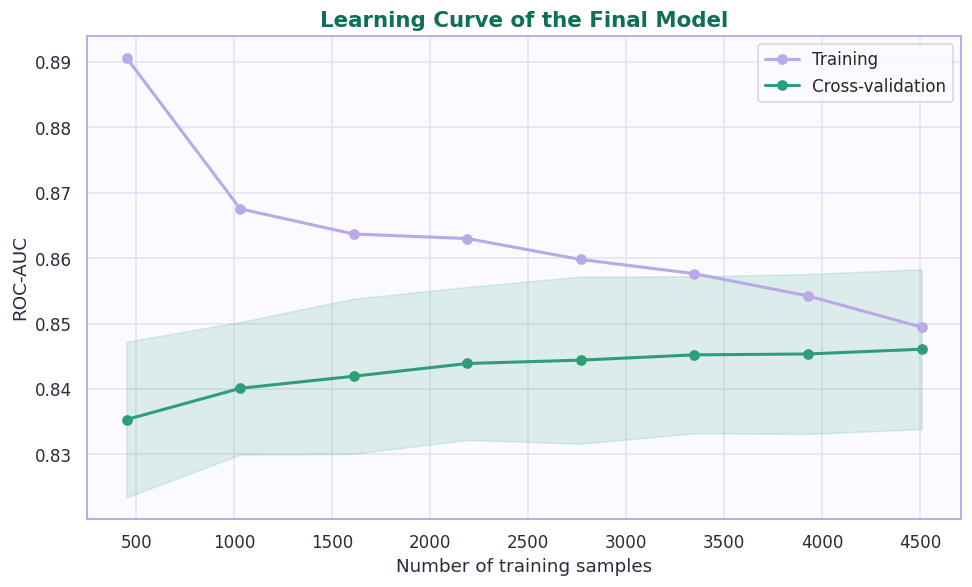

,Training samples,Train AUC,CV AUC,Gap
0,450,0.8907,0.8353,0.0553
1,1030,0.8676,0.8401,0.0275
2,1609,0.8637,0.8420,0.0217
3,2189,0.8630,0.8439,0.0191
4,2768,0.8598,0.8444,0.0154
5,3348,0.8576,0.8452,0.0124
6,3927,0.8542,0.8454,0.0089
7,4507,0.8495,0.8461,0.0034


In [ ]:
sizes, tr_sc, va_sc = learning_curve(final_pipe, Xtr_f, y_train, cv=cv, scoring='roc_auc',
                                     train_sizes=np.linspace(0.1, 1.0, 8), random_state=42)

plt.figure(figsize=(9, 5.5))
plt.plot(sizes, tr_sc.mean(1), 'o-', color=LAVENDER, lw=2, label='Training')
plt.plot(sizes, va_sc.mean(1), 'o-', color=EMERALD, lw=2, label='Cross-validation')
plt.fill_between(sizes, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1),
                 color=EMERALD, alpha=0.15)
plt.xlabel('Number of training samples'); plt.ylabel('ROC-AUC')
plt.title('Learning Curve of the Final Model'); plt.legend()
plt.tight_layout()
plt.show()

display(pd.DataFrame({'Training samples': sizes, 'Train AUC': tr_sc.mean(1),
                      'CV AUC': va_sc.mean(1), 'Gap': tr_sc.mean(1) - va_sc.mean(1)}).round(4))

**Observations:**
- With only 450 training samples the model overfits visibly (training AUC 0.891 vs CV AUC 0.835, a gap of 0.056). As the training set grows, the curves **converge**: at the full size, training AUC is 0.850 and CV AUC is 0.846, a gap of only **0.004**.
- The CV curve has almost **flattened** (0.8454 to 0.8461 over the last two steps). Doubling the data would add very little.
- This confirms that the final model **neither overfits nor underfits**. Performance is limited by the information in the features, not by the amount of data or the model's complexity.

## 9.11 Calibrating the Probabilities and Fixing the Operating Threshold
In Chapter 8 we found that class weighting inflates the predicted probabilities (average 0.41 against an actual churn rate of 0.265). We fix this with **Platt scaling** (Section 9.2f), fitted on held-out folds of the training data, so the output can be read as a real churn probability. Once the probabilities are calibrated, the theory of Section 8.2i applies directly: the best threshold is 1 / (1 + r). We check this against the threshold found empirically from out-of-fold training predictions, for several cost ratios.

Mean predicted probability  before: 0.417   after: 0.268   actual: 0.265
Brier score                 before: 0.1677   after: 0.1389   (no-skill 0.195)
ROC-AUC                     before: 0.8406   after: 0.8405


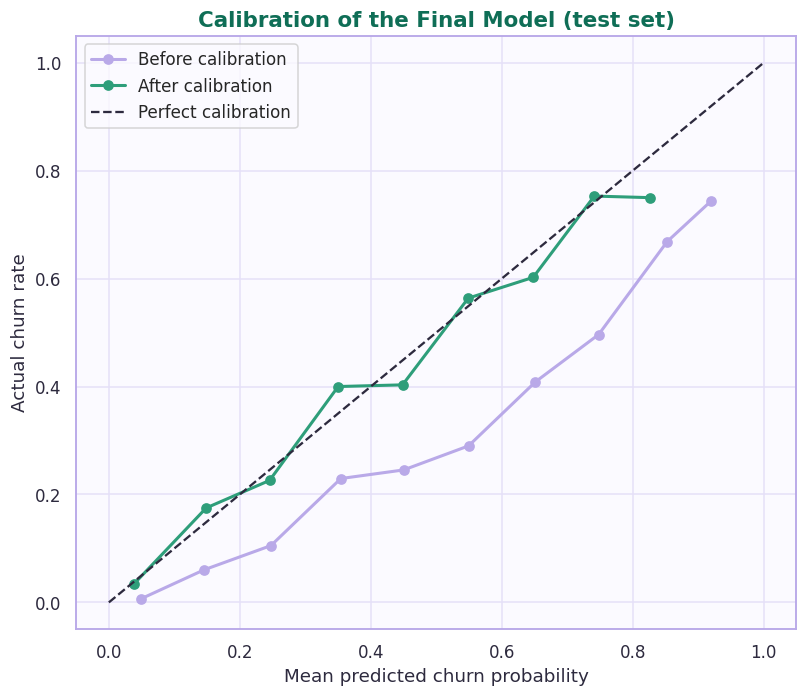

,FN:FP cost,Theory 1/(1+r),Chosen threshold,Flagged,TP,FP,FN,Recall,Precision,Model cost,Contact nobody,Contact everyone,Saving vs best simple (%)
0,1:1,0.500,0.48,317,200,117,174,0.535,0.631,291,374,1035,22.2
1,2:1,0.333,0.36,470,263,207,111,0.703,0.560,429,748,1035,42.6
2,3:1,0.250,0.30,540,288,252,86,0.770,0.533,510,1122,1035,50.7
3,5:1,0.167,0.16,767,341,426,33,0.912,0.445,591,1870,1035,42.9
4,10:1,0.091,0.08,939,362,577,12,0.968,0.386,697,3740,1035,32.7


In [ ]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

cal_model = CalibratedClassifierCV(estimator=final_pipe, method='sigmoid', cv=5)
oof_cal = cross_val_predict(cal_model, Xtr_f, y_train, cv=cv, method='predict_proba')[:, 1]
cal_model.fit(Xtr_f, y_train)
proba_cal = cal_model.predict_proba(Xte_f)[:, 1]

print(f'Mean predicted probability  before: {proba_f.mean():.3f}   after: {proba_cal.mean():.3f}   actual: {y_test.mean():.3f}')
print(f'Brier score                 before: {brier_score_loss(y_test, proba_f):.4f}   after: {brier_score_loss(y_test, proba_cal):.4f}   (no-skill 0.195)')
print(f'ROC-AUC                     before: {roc_auc_score(y_test, proba_f):.4f}   after: {roc_auc_score(y_test, proba_cal):.4f}')

plt.figure(figsize=(7.5, 6.5))
for p, label, col in [(proba_f, 'Before calibration', LAVENDER), (proba_cal, 'After calibration', EMERALD)]:
    frac, mean_p = calibration_curve(y_test, p, n_bins=10)
    plt.plot(mean_p, frac, 'o-', color=col, lw=2, label=label)
plt.plot([0, 1], [0, 1], '--', color='#2D2A3E', label='Perfect calibration')
plt.xlabel('Mean predicted churn probability'); plt.ylabel('Actual churn rate')
plt.title('Calibration of the Final Model (test set)'); plt.legend()
plt.tight_layout()
plt.show()

# Threshold for several cost ratios, chosen on out-of-fold training predictions
thr = np.round(np.arange(0.02, 0.80, 0.01), 2)
def counts(y, p, t):
    pr = (p >= t).astype(int); y = np.asarray(y)
    return (int(((pr == 1) & (y == 1)).sum()), int(((pr == 1) & (y == 0)).sum()),
            int(((pr == 0) & (y == 1)).sum()), int(((pr == 0) & (y == 0)).sum()))
def cost(y, p, t, r):
    tp, fp, fn, tn = counts(y, p, t); return r * fn + fp

n_churn, n_stay = int(y_test.sum()), int((y_test == 0).sum())
rows = []
for r in [1, 2, 3, 5, 10]:
    t = thr[np.argmin([cost(y_train, oof_cal, tt, r) for tt in thr])]
    tp, fp, fn, tn = counts(y_test, proba_cal, t)
    c = r * fn + fp
    best_simple = min(r * n_churn, n_stay)
    rows.append([f'{r}:1', round(1 / (1 + r), 3), t, tp + fp, tp, fp, fn, round(tp / (tp + fn), 3),
                 round(tp / (tp + fp), 3), c, r * n_churn, n_stay, round((best_simple - c) / best_simple * 100, 1)])
display(pd.DataFrame(rows, columns=['FN:FP cost', 'Theory 1/(1+r)', 'Chosen threshold', 'Flagged', 'TP', 'FP',
                                    'FN', 'Recall', 'Precision', 'Model cost', 'Contact nobody',
                                    'Contact everyone', 'Saving vs best simple (%)']))

**Observations:**
- **Calibration works:** the average predicted probability moves from 0.415 to **0.268**, almost exactly the true churn rate of 0.265. The Brier score improves from 0.168 to **0.139** (no-skill reference 0.195), and the calibration curve now follows the diagonal closely. The ROC-AUC is unchanged (0.8405 vs 0.8406), because calibration changes the *scale* of the probabilities, not the *ranking* of customers.
- **Theory and data agree.** The thresholds found empirically on training data are close to the theoretical 1 / (1 + r): for example **0.16 vs 0.167** at a 5:1 cost ratio, 0.08 vs 0.091 at 10:1, and 0.48 vs 0.50 at 1:1. This confirms that the calibrated probabilities behave as true probabilities and that the cost analysis is consistent.
- **At the 5:1 assumption,** the threshold of 0.16 flags **767 customers (54% of the test set)**, catches **341 of 374 churners (91.2%)**, misses only 33, and has precision 44.5%. Its cost is **591**, compared with 1,870 for contacting nobody and 1,035 for contacting everyone, a **42.9% saving**.
- **Savings hold across all cost ratios:** 22% (1:1), 43% (2:1), **51% (3:1)**, 43% (5:1) and 33% (10:1) versus the better simple strategy. The company can choose the row that matches its real retention costs.

## 9.12 Summary of Tuning and Final Model Selection

| Question | Finding |
|---|---|
| How much did tuning help? | Very little: CV ROC-AUC changed by +0.0002 (Logistic Regression), +0.0037 (Random Forest) and +0.0018 (Gradient Boosting) |
| Which hyperparameters mattered? | Tree depth for Random Forest (deep trees overfit), shallow trees (depth 2) for Gradient Boosting. For Logistic Regression, almost none |
| Are the models different? | No: all three are within one standard error (0.0059) of the best CV AUC (0.8489) |
| Selected model | **Logistic Regression** (L1, C = 0.3, balanced class weights): simplest, explainable, equally accurate |
| Feature decisions | Removed `num_addons` (collinear, no benefit); L1 removed 4 more. Engineered features gave no measurable accuracy gain but aid interpretation |
| Final test performance | ROC-AUC 0.841, PR-AUC 0.626, recall 0.786, F1 0.616 (at threshold 0.5) |
| Over/underfitting | None: training and CV AUC differ by only 0.004 at full size |
| Would more data help? | Very little: the learning curve has flattened |
| Probabilities | Recalibrated with Platt scaling (Brier 0.168 to 0.139) |
| Operating threshold | 1 / (1 + r) on calibrated probabilities. At 5:1 cost: threshold about 0.16, recall 91%, 43% cost saving |

**Final model specification**

| Item | Value |
|---|---|
| Algorithm | Logistic Regression, L1 penalty, C = 0.3, solver liblinear |
| Class handling | class_weight = balanced |
| Inputs | 24 features (tenure, MonthlyCharges standardised; the rest 0/1) |
| Calibration | Platt scaling (sigmoid), 5-fold |
| Decision rule | Flag a customer when calibrated churn probability ≥ 1 / (1 + r), where r is the cost ratio |
| Evaluation | Test ROC-AUC 0.841 (95% interval 0.819 to 0.861) |

# Chapter 10: Results and Interpretation

## 10.1 Introduction
A model is only useful if people can understand what it has learned and act on it. In this chapter we use the final model (Logistic Regression with calibrated probabilities, Chapter 9) to answer five practical questions:

1. **What drives churn?** Which feature groups matter most to the model's predictions?
2. **How does churn risk change?** What happens to risk as tenure, price, contract or internet type change?
3. **How well can we target customers?** If the company contacts only the riskiest customers, how many churners does it reach?
4. **Who is at risk, and who is missed?** What do high-risk customers look like, and what do the model's mistakes tell us?
5. **What should the company do?** Which actions follow from the evidence, and what are the limits of our conclusions?

All results use the **test set** (1,409 customers, 374 churners) and the **calibrated churn probability** of each customer, so a predicted 40% risk means about 40% of such customers really churn (Section 9.11).

## 10.2 Mathematical Foundations Used in This Chapter

**(a) Odds ratios.** For the Logistic Regression model, a coefficient β_j gives the odds ratio e^(β_j): the factor by which the odds of churn are multiplied when feature j increases by one unit, with the other features unchanged (Section 7.2b).

**(b) Permutation importance.** A feature group is important if the model gets worse when the information in that group is destroyed. We shuffle the values of all columns of the group together (which breaks their link to churn but keeps their distribution), and measure how much the ROC-AUC falls. Averaged over R = 30 random shuffles:

$$I_G = AUC_{\text{base}} - \frac{1}{R}\sum_{r=1}^{R} AUC^{(r)}_{G\ \text{shuffled}}$$

A large drop means the model relies strongly on the group. Related features can share information, so a group that overlaps with another may look less important than it really is.

**(c) What-if analysis (partial dependence).** To see the effect of one feature j, we set it to a value v for **every** customer, leave all other features as they are, and average the predicted churn probabilities:

$$\overline{PD}_j(v)=\frac{1}{N}\sum_{i=1}^{N}\hat{p}\big(x_i^{(j\leftarrow v)}\big)$$

Repeating this for many values of v draws the model's response curve for that feature.

**(d) Lift and cumulative gains.** Customers are sorted from highest to lowest predicted risk and split into ten equal groups (deciles). For each decile k:

$$\text{Lift}_k=\frac{\text{Churn rate in decile } k}{\text{Overall churn rate}} \qquad\qquad \text{Gain}(q)=\frac{\text{Churners among the top } q\% \text{ of customers}}{\text{All churners}}$$

A lift of 2.7 means that group churns 2.7 times as often as an average customer. With random targeting, Gain(q) = q, which is the diagonal of the gains chart.

**(e) Risk tiers.** We use two thresholds on the calibrated probability: p ≥ 0.50 is **High** risk, 0.16 ≤ p < 0.50 is **Medium**, and p < 0.16 is **Low**. The value 0.16 is the cost-optimal threshold for a 5:1 cost ratio found in Chapter 9 (theory: 1 / (1 + 5) = 0.167).

**(f) Revenue captured.** Using each customer's monthly charge, the share of the monthly revenue of churners that the model reaches is:

$$\text{Revenue captured}=\frac{\sum_{i \in TP}\text{MonthlyCharges}_i}{\sum_{i \in \text{all churners}}\text{MonthlyCharges}_i}$$

In [ ]:
needed = ['X_train', 'X_test', 'y_train', 'y_test', 'num_features', 'cv', 'EMERALD', 'LAVENDER', 'DEEP', 'CMAP', 'Pipeline']
missing = [v for v in needed if v not in globals()]
if missing:
    raise NameError(f'Run the Chapter 9 setup cell (Cell 0) first. Missing: {missing}')

from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_auc_score, confusion_matrix

def prep_for(cols):
    return ColumnTransformer([('scale', StandardScaler(), [c for c in num_features if c in cols])],
                             remainder='passthrough', verbose_feature_names_out=False)

final_features = [c for c in X_train.columns if c != 'num_addons']
Xtr_f, Xte_f = X_train[final_features], X_test[final_features]

final_pipe = Pipeline([('prep', prep_for(final_features)),
                       ('clf', LogisticRegression(solver='liblinear', penalty='l1', C=0.3,
                                                  class_weight='balanced', max_iter=2000,
                                                  random_state=42))]).fit(Xtr_f, y_train)
cal_model = CalibratedClassifierCV(estimator=final_pipe, method='sigmoid', cv=5).fit(Xtr_f, y_train)

risk = cal_model.predict_proba(Xte_f)[:, 1]          # calibrated churn probability for each test customer
base_rate = y_test.mean()
print('Final model ready. Test customers:', len(Xte_f), '| actual churn rate: %.3f' % base_rate,
      '| mean predicted risk: %.3f' % risk.mean())

Final model ready. Test customers: 1409 | actual churn rate: 0.265 | mean predicted risk: 0.268


## 10.3 What Drives Churn? Permutation Importance by Feature Group
The coefficients and odds ratios of the final model were discussed in Section 9.8. Here we ask a different question: *how much does the model's ability to rank customers depend on each factor?* Because one-hot columns of the same feature (for example the two contract columns) cannot be judged separately, we shuffle each **group** of related columns together. Related features are grouped by theme: for example, tenure together with `new_customer`, and the payment-method columns together with `auto_pay`.

Baseline test ROC-AUC: 0.8406


,AUC drop (mean),AUC drop (std)
Tenure,0.0778,0.0056
Internet service type,0.0745,0.0082
Contract type,0.0478,0.0070
Security & support,0.0072,0.0027
Streaming services,0.0070,0.0021
Monthly charges,0.0067,0.0018
Payment method,0.0024,0.0015
Paperless billing,0.0012,0.0013
Senior citizen,0.0011,0.0005
Multiple phone lines,0.0006,0.0014


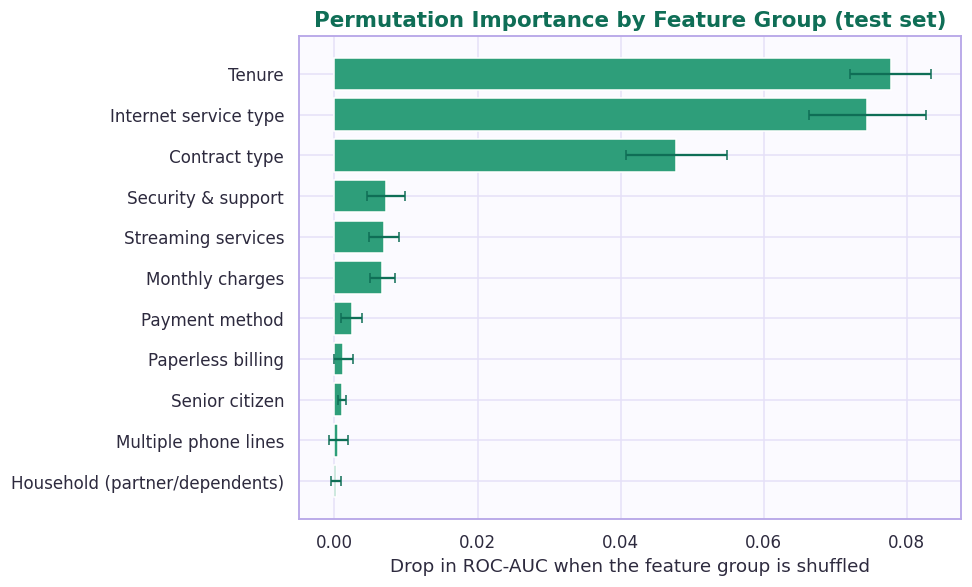

In [ ]:
groups = {
    'Contract type':            ['Contract_One year', 'Contract_Two year'],
    'Internet service type':    ['InternetService_Fiber optic', 'InternetService_No'],
    'Tenure':                   ['tenure', 'new_customer'],
    'Payment method':           [c for c in final_features if c.startswith('PaymentMethod_')] + ['auto_pay'],
    'Monthly charges':          ['MonthlyCharges'],
    'Security & support':       ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'has_security_support'],
    'Streaming services':       ['StreamingTV', 'StreamingMovies'],
    'Paperless billing':        ['PaperlessBilling'],
    'Household (partner/dependents)': ['Partner', 'Dependents', 'has_family'],
    'Senior citizen':           ['SeniorCitizen'],
    'Multiple phone lines':     ['MultipleLines']}

def grouped_permutation_importance(model, X, y, groups, n_repeats=30, seed=42):
    rng = np.random.default_rng(seed)
    base = roc_auc_score(y, model.predict_proba(X)[:, 1])
    rows = {}
    for g, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[cols] = X[cols].values[rng.permutation(len(X))]     # shuffle the whole group together
            drops.append(base - roc_auc_score(y, model.predict_proba(Xp)[:, 1]))
        rows[g] = (np.mean(drops), np.std(drops))
    out = pd.DataFrame(rows, index=['AUC drop (mean)', 'AUC drop (std)']).T
    return base, out.sort_values('AUC drop (mean)', ascending=False)

base_auc, perm = grouped_permutation_importance(final_pipe, Xte_f, y_test, groups)
print(f'Baseline test ROC-AUC: {base_auc:.4f}')
display(perm.round(4))

plt.figure(figsize=(9, 5.5))
p = perm.iloc[::-1]
plt.barh(p.index, p['AUC drop (mean)'], xerr=p['AUC drop (std)'], color=EMERALD, ecolor=DEEP, capsize=3)
plt.xlabel('Drop in ROC-AUC when the feature group is shuffled')
plt.title('Permutation Importance by Feature Group (test set)')
plt.tight_layout()
plt.show()

**Observations:**
- **Three feature groups dominate:** **Tenure** (AUC drop 0.078), **Internet service type** (0.075) and **Contract type** (0.048). Together they make up about **88%** of the total importance of all eleven groups.
- When tenure information is destroyed, the model's ROC-AUC falls from 0.841 to about 0.763, a loss of nearly 8 percentage points. No other single group costs the model more.
- **Contract ranks only third here although it had the strongest association in Chapter 5** (Cramér's V = 0.41). The reason is overlap: customers on long contracts also tend to have long tenure, so when contract is shuffled, tenure still carries part of the information. Importance measures *unique* information, which is why this method complements the earlier tests.
- **Medium-sized groups:** Security & support (0.007), Streaming services (0.007) and Monthly charges (0.007) each add a little.
- **Payment method, paperless billing, senior citizen, multiple lines and household** contribute almost nothing extra (below 0.003), once the main groups are known. For example, payment method looked important in the EDA (electronic check users churn 45.3%), but much of that effect is already explained by tenure, contract and internet type.

## 10.4 How Does Churn Risk Respond? What-If Analysis
Importance tells us *which* factors matter. What-if curves show *how* the predicted risk changes with them. For tenure and monthly charges we trace the risk across the full range of values. For contract and internet type we ask: "what would the average risk be if every customer were on this plan, with everything else unchanged?" When tenure is varied, the derived feature `new_customer` is updated together with it, so the two stay consistent.

These curves show what the **model** has learned from the data. They are associations and do not prove that changing a plan would change a customer's behaviour.

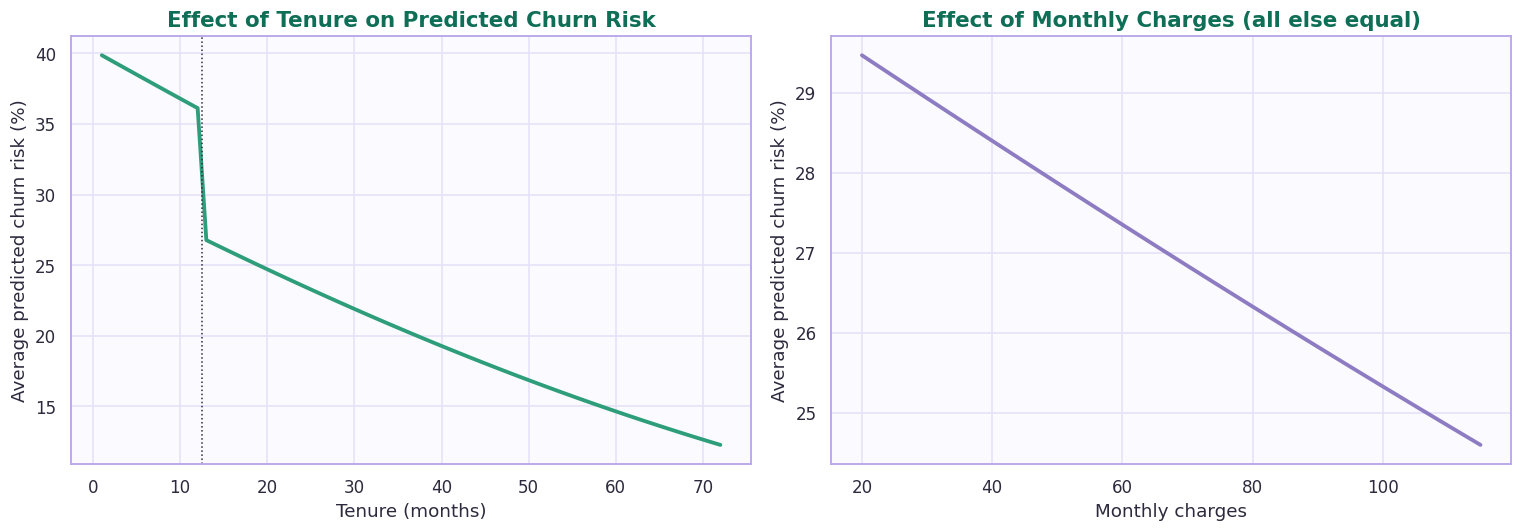

,Tenure (months),Avg risk (%)
0,1,39.9
1,6,38.2
2,12,36.1
3,13,26.8
4,24,23.6
5,36,20.3
6,48,17.3
7,60,14.6
8,72,12.3


,Monthly charges,Avg risk (%)
0,20,29.5
3,35,28.7
6,50,27.9
9,65,27.1
12,80,26.3
15,95,25.6
18,110,24.8


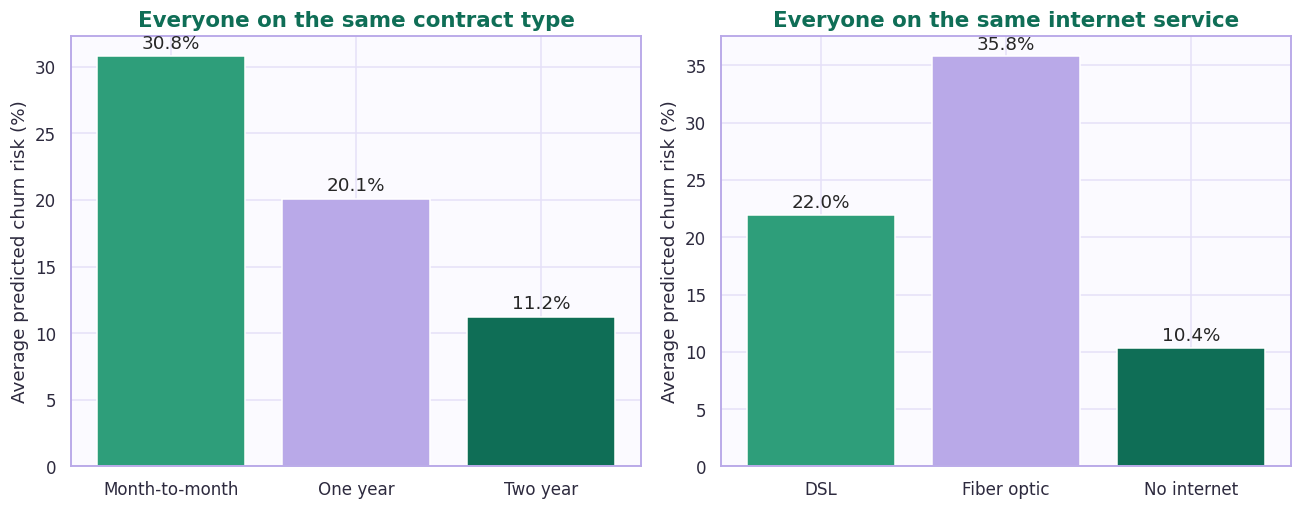

,Contract (everyone on),Avg risk (%)
0,Month-to-month,30.8
1,One year,20.1
2,Two year,11.2


,Internet service (everyone on),Avg risk (%)
0,DSL,22.0
1,Fiber optic,35.8
2,No internet,10.4


In [ ]:
def what_if_average(model, X, feature, grid):
    """Average predicted churn risk if every customer had the given value of one feature."""
    out = []
    for v in grid:
        Xv = X.copy()
        Xv[feature] = v
        if feature == 'tenure':
            Xv['new_customer'] = int(v <= 12)          # keep the derived feature consistent
        out.append(model.predict_proba(Xv)[:, 1].mean())
    return np.array(out)

tenure_grid = np.arange(1, 73)
charge_grid = np.arange(20, 116, 5)
pd_tenure = what_if_average(cal_model, Xte_f, 'tenure', tenure_grid)
pd_charge = what_if_average(cal_model, Xte_f, 'MonthlyCharges', charge_grid)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(tenure_grid, pd_tenure * 100, color=EMERALD, lw=2.5)
axes[0].axvline(12.5, color='#2D2A3E', ls=':', lw=1)
axes[0].set_xlabel('Tenure (months)'); axes[0].set_ylabel('Average predicted churn risk (%)')
axes[0].set_title('Effect of Tenure on Predicted Churn Risk')
axes[1].plot(charge_grid, pd_charge * 100, color='#8E7CC3', lw=2.5)
axes[1].set_xlabel('Monthly charges'); axes[1].set_ylabel('Average predicted churn risk (%)')
axes[1].set_title('Effect of Monthly Charges (all else equal)')
plt.tight_layout()
plt.show()
display(pd.DataFrame({'Tenure (months)': [1, 6, 12, 13, 24, 36, 48, 60, 72],
                      'Avg risk (%)': [pd_tenure[t - 1] * 100 for t in [1, 6, 12, 13, 24, 36, 48, 60, 72]]}).round(1))
display(pd.DataFrame({'Monthly charges': charge_grid, 'Avg risk (%)': pd_charge * 100}).iloc[::3].round(1))

# What-if for categorical choices: put every customer on the same plan, keep everything else unchanged
def what_if_plan(model, X, assignments):
    res_ = {}
    for label, values in assignments.items():
        Xv = X.copy()
        for col, val in values.items():
            Xv[col] = val
        res_[label] = model.predict_proba(Xv)[:, 1].mean() * 100
    return res_

contract_wi = what_if_plan(cal_model, Xte_f, {
    'Month-to-month': {'Contract_One year': 0, 'Contract_Two year': 0},
    'One year':       {'Contract_One year': 1, 'Contract_Two year': 0},
    'Two year':       {'Contract_One year': 0, 'Contract_Two year': 1}})
internet_wi = what_if_plan(cal_model, Xte_f, {
    'DSL':         {'InternetService_Fiber optic': 0, 'InternetService_No': 0},
    'Fiber optic': {'InternetService_Fiber optic': 1, 'InternetService_No': 0},
    'No internet': {'InternetService_Fiber optic': 0, 'InternetService_No': 1}})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, d, title in [(axes[0], contract_wi, 'Everyone on the same contract type'),
                     (axes[1], internet_wi, 'Everyone on the same internet service')]:
    bars = ax.bar(list(d), list(d.values()), color=[EMERALD, LAVENDER, DEEP], edgecolor='white')
    for b, v in zip(bars, d.values()):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.6, f'{v:.1f}%', ha='center')
    ax.set_title(title); ax.set_ylabel('Average predicted churn risk (%)')
plt.tight_layout()
plt.show()
display(pd.DataFrame({'Contract (everyone on)': list(contract_wi), 'Avg risk (%)': np.round(list(contract_wi.values()), 1)}))
display(pd.DataFrame({'Internet service (everyone on)': list(internet_wi), 'Avg risk (%)': np.round(list(internet_wi.values()), 1)}))

**Observations:**
- **Tenure:** the average predicted risk falls steadily from **39.9%** at 1 month to **23.6%** at 24 months, **17.3%** at 48 months and **12.3%** at 72 months. There is a visible **step at 12 to 13 months**, from 36.1% down to 26.8%. This step is partly caused by the "12 months or less" rule of the engineered feature `new_customer`, but the real data also shows a sharp fall after the first year (47.4% churn in months 0 to 12, against 28.7% in months 13 to 24; Chapter 5), so the first year is genuinely the critical period.
- **Monthly charges:** with everything else held fixed, a higher price is associated with a *slightly lower* risk (29.5% at a charge of 20, falling to 24.8% at 110). The raw data showed the opposite (churners pay more on average), because expensive plans contain fiber optic and streaming services, which are the real risk factors. **The price itself is not the driver; the type of service is.**
- **Contract type:** if all customers were on month-to-month plans the average risk would be **30.8%**, on one-year plans **20.1%**, and on two-year plans **11.2%**. Moving from month-to-month to a two-year plan is associated with a drop of about 20 percentage points.
- **Internet service:** the average risk would be **35.8%** for fiber optic, **22.0%** for DSL and **10.4%** for customers without internet. Fiber optic customers carry about 14 percentage points more risk than DSL customers, even after accounting for tenure, contract, services and payment, which suggests a problem specific to the fiber product (price-to-value, reliability, or competition).

## 10.5 How Well Can We Target Customers? Risk Deciles, Lift and Gains
In practice a retention team contacts a limited number of customers. We sort all test customers from the highest to the lowest predicted risk, split them into ten equal groups (deciles), and check what share of the real churners each group contains. A good model puts almost all churners in the top deciles.

,Customers,Churners,Avg_predicted_risk,Churn_rate,Lift,Cum_churners_captured_%,Cum_customers_%
decile,,,,,,,
1,141,101,0.742,0.716,2.699,27.005,10.007
2,141,81,0.584,0.574,2.164,48.663,20.014
3,141,59,0.451,0.418,1.576,64.439,30.021
4,141,50,0.339,0.355,1.336,77.807,40.028
5,141,34,0.231,0.241,0.908,86.898,50.035
6,140,28,0.154,0.200,0.753,94.385,59.972
7,141,13,0.089,0.092,0.347,97.861,69.979
8,141,6,0.050,0.043,0.160,99.465,79.986
9,141,1,0.025,0.007,0.027,99.733,89.993


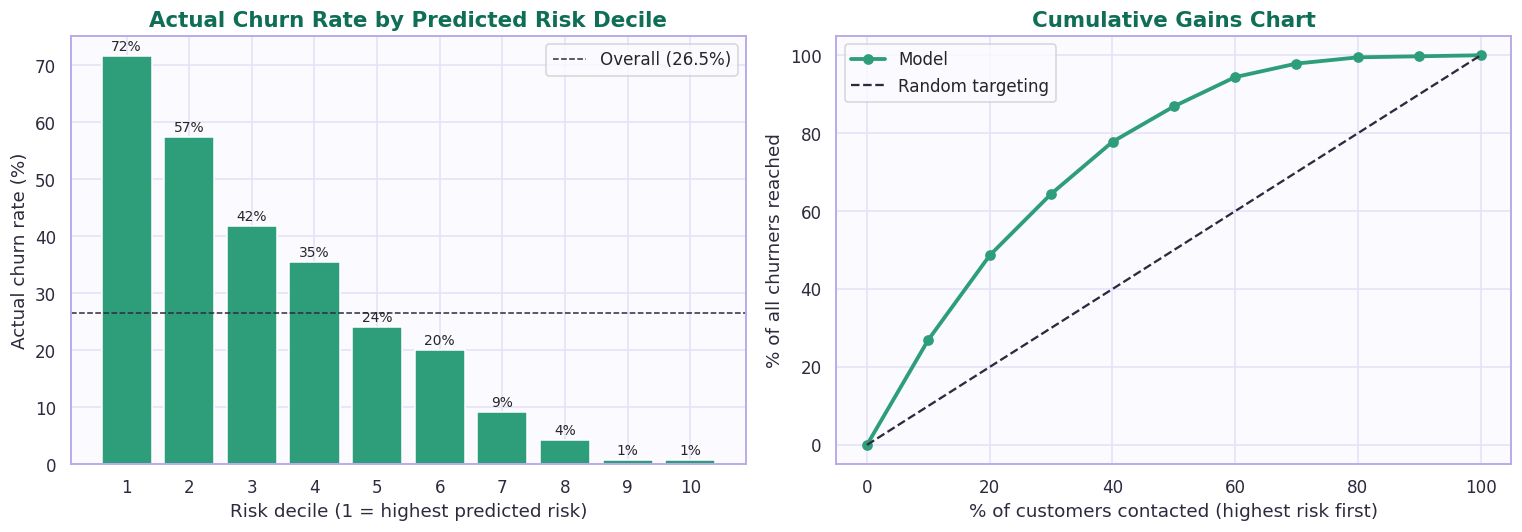

In [ ]:
tr = pd.DataFrame({'risk': risk, 'churn': y_test.values, 'monthly': X_test['MonthlyCharges'].values})
tr['rank'] = tr['risk'].rank(method='first', ascending=False)
tr['decile'] = pd.qcut(tr['rank'], 10, labels=range(1, 11)).astype(int)     # 1 = highest risk

dec = tr.groupby('decile').agg(Customers=('churn', 'size'), Churners=('churn', 'sum'),
                               Avg_predicted_risk=('risk', 'mean'), Churn_rate=('churn', 'mean'))
dec['Lift'] = dec['Churn_rate'] / base_rate
dec['Cum_churners_captured_%'] = dec['Churners'].cumsum() / dec['Churners'].sum() * 100
dec['Cum_customers_%'] = dec['Customers'].cumsum() / dec['Customers'].sum() * 100
display(dec.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bars = axes[0].bar(dec.index.astype(str), dec['Churn_rate'] * 100, color=EMERALD, edgecolor='white')
axes[0].axhline(base_rate * 100, color='#2D2A3E', ls='--', lw=1, label=f'Overall ({base_rate*100:.1f}%)')
for b, v in zip(bars, dec['Churn_rate'] * 100):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 1, f'{v:.0f}%', ha='center', fontsize=9)
axes[0].set_xlabel('Risk decile (1 = highest predicted risk)'); axes[0].set_ylabel('Actual churn rate (%)')
axes[0].set_title('Actual Churn Rate by Predicted Risk Decile'); axes[0].legend()

xs = np.r_[0, dec['Cum_customers_%'].values]
ys = np.r_[0, dec['Cum_churners_captured_%'].values]
axes[1].plot(xs, ys, 'o-', color=EMERALD, lw=2.5, label='Model')
axes[1].plot([0, 100], [0, 100], '--', color='#2D2A3E', label='Random targeting')
axes[1].set_xlabel('% of customers contacted (highest risk first)')
axes[1].set_ylabel('% of all churners reached')
axes[1].set_title('Cumulative Gains Chart'); axes[1].legend()
plt.tight_layout()
plt.show()

**Observations:**
- **The ranking works.** The actual churn rate falls steadily from **71.6% in the top decile** to **0.7% in the lowest two deciles**. The predicted and actual risks agree closely in every decile (for example 74.2% predicted vs 71.6% actual in decile 1, and 23.1% vs 24.1% in decile 5), confirming that the probabilities are well calibrated.
- **Lift:** the top decile churns **2.7 times** as often as an average customer (lift 2.70), and the second decile 2.2 times.
- **Cumulative gains:** contacting only the riskiest **10%** of customers reaches **27.0%** of all churners, the top **20%** reaches **48.7%**, the top **30%** reaches **64.4%**, and the top **50%** reaches **86.9%**. Random targeting would reach only 10%, 20%, 30% and 50%.
- **Where not to spend:** the 30% lowest-risk customers (deciles 8 to 10) contain only **8 of the 374 churners (2.1%)**. Spending retention budget on them would be almost entirely wasted.

## 10.6 Risk Tiers: Who Are the High-Risk Customers?
For daily use, ten deciles are too detailed. We group customers into three tiers using the thresholds from Section 10.2e, and then describe each tier: how many customers it contains, how many churners, how much revenue is at stake, and what the customers look like.

In [ ]:
def tier(p):
    return 'High (risk >= 50%)' if p >= 0.50 else ('Medium (16% to 50%)' if p >= 0.16 else 'Low (risk < 16%)')

tr['tier'] = tr['risk'].apply(tier)
order = ['High (risk >= 50%)', 'Medium (16% to 50%)', 'Low (risk < 16%)']
tiers = tr.groupby('tier').agg(Customers=('churn', 'size'), Churners=('churn', 'sum'),
                               Churn_rate=('churn', 'mean'), Avg_monthly_charge=('monthly', 'mean'),
                               Monthly_revenue_of_churners=('monthly', lambda s: s[tr.loc[s.index, 'churn'] == 1].sum())
                               ).loc[order]
tiers['% of customers'] = tiers['Customers'] / len(tr) * 100
tiers['% of all churners'] = tiers['Churners'] / tr['churn'].sum() * 100
display(tiers.round(2))

# Profile of the tiers (share of customers with each characteristic)
prof_src = Xte_f.copy()
prof_src['tier'] = tr['tier'].values
prof_src['Month-to-month'] = 1 - prof_src['Contract_One year'] - prof_src['Contract_Two year']
prof_src['Fiber optic'] = prof_src['InternetService_Fiber optic']
profile_cols = {'Month-to-month': 'Month-to-month contract', 'Fiber optic': 'Fiber optic internet',
                'new_customer': 'New customer (<= 12 months)', 'auto_pay': 'Automatic payment',
                'has_security_support': 'Has security or tech support', 'SeniorCitizen': 'Senior citizen',
                'Dependents': 'Has dependents', 'PaperlessBilling': 'Paperless billing'}
profile = (prof_src.groupby('tier')[list(profile_cols)].mean().mul(100).loc[order].rename(columns=profile_cols).T)
profile['All customers'] = prof_src[list(profile_cols)].mean().mul(100).rename(index=profile_cols)
profile.index.name = '% of customers in tier with:'
display(profile.round(1))

,Customers,Churners,Churn_rate,Avg_monthly_charge,Monthly_revenue_of_churners,% of customers,% of all churners
tier,,,,,,,
High (risk >= 50%),291,188,0.65,80.38,15035.70,20.65,50.27
Medium (16% to 50%),476,153,0.32,65.97,9766.15,33.78,40.91
Low (risk < 16%),642,33,0.05,55.31,2413.05,45.56,8.82


tier,High (risk >= 50%),Medium (16% to 50%),Low (risk < 16%),All customers
% of customers in tier with:,,,,
Month-to-month contract,99.0,83.8,13.4,54.9
Fiber optic internet,89.3,46.8,20.2,43.5
New customer (<= 12 months),74.2,38.7,7.6,31.9
Automatic payment,16.5,34.9,61.5,43.2
Has security or tech support,11.3,41.2,54.4,41.0
Senior citizen,28.5,20.2,6.7,15.8
Has dependents,10.3,21.8,46.3,30.6
Paperless billing,84.5,65.5,43.9,59.6


**Observations:**

| Tier | Customers | Actual churn rate | Share of all churners | Avg monthly charge |
|---|---|---|---|---|
| **High** (risk ≥ 50%) | 291 (20.7%) | **65%** | **50.3%** (188 of 374) | 80.38 |
| **Medium** (16% to 50%) | 476 (33.8%) | 32% | 40.9% (153) | 65.97 |
| **Low** (risk < 16%) | 642 (45.6%) | **5%** | 8.8% (33) | 55.31 |

- **A fifth of the customers (the High tier) account for half of all churners**, and they also pay more (80.38 vs 55.31 per month). In revenue terms, the High tier holds **15,036 of the 27,215 monthly revenue lost to churners (55.2%)**. (The dataset does not state the currency, so these are monetary units.)
- **High-risk customers have a very clear profile:** 99.0% are on month-to-month contracts, 89.3% have fiber optic internet, 74.2% are new customers (12 months or less), only 16.5% pay automatically, only 11.3% have security or tech support, 84.5% use paperless billing, and 28.5% are senior citizens.
- **Low-risk customers are the opposite:** only 13.4% month-to-month, 61.5% automatic payment, 54.4% with security or tech support, 46.3% with dependents, and just 7.6% new.
- **Combined with Chapter 9:** the High and Medium tiers together (767 customers, 54% of the base) contain **341 of the 374 churners (91.2%)**. This is the group selected by the 5:1 cost threshold of 0.16.

## 10.7 Error Analysis and Revenue Impact
Understanding a model's mistakes is as important as its successes. We use the business threshold of 0.16 (5:1 cost ratio) and compare four groups of customers: churners the model caught (true positives), churners it missed (false negatives), false alarms (false positives) and customers correctly left alone (true negatives). We also measure how much of the lost monthly revenue the model reaches (Section 10.2f).

In [ ]:
thr_b = 0.16                                   # business threshold for a 5:1 cost ratio (Chapter 9)
pred_b = (risk >= thr_b).astype(int)
tn_b, fp_b, fn_b, tp_b = confusion_matrix(y_test, pred_b).ravel()
print(f'At threshold {thr_b}:  TP={tp_b}  FP={fp_b}  FN={fn_b}  TN={tn_b}  | flagged={tp_b + fp_b} of {len(y_test)}')

monthly = X_test['MonthlyCharges'].values
rev_all = monthly[y_test.values == 1].sum()
rev_caught = monthly[(pred_b == 1) & (y_test.values == 1)].sum()
print(f'Monthly revenue of all churners : {rev_all:,.0f}')
print(f'Monthly revenue of churners caught: {rev_caught:,.0f}  ({rev_caught / rev_all * 100:.1f}%)')
print(f'Monthly revenue of churners missed: {rev_all - rev_caught:,.0f}')

# Who does the model miss? Compare caught churners (TP) with missed churners (FN)
err = Xte_f.copy()
err['group'] = np.select([(pred_b == 1) & (y_test.values == 1), (pred_b == 0) & (y_test.values == 1),
                          (pred_b == 1) & (y_test.values == 0)], ['Caught churners (TP)', 'Missed churners (FN)',
                          'False alarms (FP)'], 'Correctly left alone (TN)')
err['Month-to-month'] = 1 - err['Contract_One year'] - err['Contract_Two year']
cmp_cols = ['tenure', 'MonthlyCharges', 'Month-to-month', 'InternetService_Fiber optic', 'new_customer',
            'auto_pay', 'has_security_support', 'SeniorCitizen']
miss = err.groupby('group')[cmp_cols].mean()
miss['n'] = err['group'].value_counts()
miss = miss.loc[['Caught churners (TP)', 'Missed churners (FN)', 'False alarms (FP)', 'Correctly left alone (TN)']]
display(miss.round(2))

At threshold 0.16:  TP=341  FP=426  FN=33  TN=609  | flagged=767 of 1409
Monthly revenue of all churners : 27,215
Monthly revenue of churners caught: 24,802  (91.1%)
Monthly revenue of churners missed: 2,413


,tenure,MonthlyCharges,Month-to-month,InternetService_Fiber optic,new_customer,auto_pay,has_security_support,SeniorCitizen,n
group,,,,,,,,,
Caught churners (TP),13.68,72.73,0.94,0.70,0.62,0.26,0.21,0.28,341
Missed churners (FN),45.24,73.12,0.24,0.36,0.09,0.64,0.79,0.06,33
False alarms (FP),21.90,70.40,0.86,0.57,0.44,0.30,0.37,0.19,426
Correctly left alone (TN),48.41,54.35,0.13,0.19,0.08,0.61,0.53,0.07,609


**Observations:**
- At the 0.16 threshold the model flags **767 of 1,409 customers** and catches 341 churners, misses 33, and raises 426 false alarms.
- **Revenue:** the model reaches **24,802 of the 27,215 monthly revenue** of churners (**91.1%**). The 33 missed churners represent 2,413 per month.
- **The missed churners (33) look like loyal customers:** average tenure 45 months (caught churners: 13.7), only 24% on month-to-month contracts (caught: 94%), only 9% are new customers (caught: 62%), 64% pay automatically (caught: 26%), and 79% have security or tech support (caught: 21%). These "silent churners" leave without any warning signs in the data, probably because of events the dataset does not record, such as moving away, a life change or a competitor offer.
- **The false alarms (426) look like churners who did not leave:** 86% on month-to-month contracts, 57% on fiber, average tenure 22 months. The model cannot separate them from true churners using the available data. Some of them may have been retained by other means, and for the company a false alarm costs only an unnecessary offer (the 5:1 assumption).
- **Limitation:** with only 33 missed churners, these percentages are rough, but the contrast with the caught group is large enough to be informative.

## 10.8 Answers to the Research Questions
In Chapter 2 we posed six research questions. We can now answer each with evidence from the whole project.

| # | Research question | Answer and evidence |
|---|---|---|
| 1 | Which customer attributes are most strongly associated with churn? | **Tenure, internet service type and contract type.** They make up about 88% of the permutation importance (Section 10.3). Chapter 5 found the same three at the top, together with payment method |
| 2 | Does contract type affect churn? | **Yes, very strongly.** Raw churn is 42.7% (month-to-month), 11.3% (one year) and 2.8% (two year). In the model, odds ratios are 0.48 and 0.21, and the what-if risk falls from 30.8% to 11.2% |
| 3 | How do tenure and monthly charges relate to churn? | **Tenure:** correlation -0.35, and predicted risk falls from 39.9% at 1 month to 12.3% at 72 months. **Monthly charges:** churners pay more (74.44 vs 61.27) and churn peaks in the 70 to 90 band (37.8%), but with services held fixed, price is slightly *protective*, so the services (fiber, streaming) are the real cause |
| 4 | Do additional services reduce churn? | **Security and support do; streaming does not.** Customers without Online Security or Tech Support churn at about 31% against 15% with them, and the odds ratio of `has_security_support` is 0.69. Streaming TV and movies *raise* the odds (about 1.4) |
| 5 | Does payment method relate to churn? | **Yes, but largely through other factors.** Electronic check users churn at 45.3%. In the model, automatic payment has an odds ratio of 0.67, but the extra importance of payment method is small (AUC drop 0.002) once tenure, contract and internet type are known |
| 6 | Which model gives the best balance between catching churners and avoiding false alarms? | **Logistic Regression** (selected in Chapter 9 by the one-standard-error rule; all models were statistically equal). At the 0.5 threshold it has recall 0.786 and precision 0.507. With the 5:1 cost-optimal threshold (0.16) it reaches recall 0.912 and precision 0.445 |

## 10.9 Final Verdict on the Hypotheses
We checked the four hypotheses with the EDA in Chapter 5. The table shows whether the final model agrees.

| Hypothesis | Verdict | Evidence from the model |
|---|---|---|
| **H1:** Shorter tenure means higher churn | **Supported** | Tenure is the most important group (AUC drop 0.078). Predicted risk falls from 39.9% to 12.3% as tenure rises from 1 to 72 months |
| **H2:** Month-to-month contracts churn more | **Supported** | Odds ratios 0.48 (one year) and 0.21 (two year). Average predicted risk 30.8% vs 20.1% vs 11.2% |
| **H3:** Higher monthly charges mean higher churn | **Not supported after controlling for services** | Raw churners pay more, but in the model, price has an odds ratio of 0.80 per standard deviation and the what-if risk even falls slightly with price. The effect is explained by fiber optic and streaming services |
| **H4:** No tech support or online security means higher churn | **Supported, with a smaller effect than the raw data suggest** | Odds ratio 0.69 for having security or tech support. The raw gap (31% vs 15%) shrinks because these customers also differ in contract and tenure |

## 10.10 Business Insights and Recommendations
The recommendations below follow from the evidence in this project. Each is a hypothesis to be tested with a pilot campaign, not a proven cause and effect.

| Priority | Recommendation | Evidence |
|---|---|---|
| 1 | **Move month-to-month customers to longer contracts**, using incentives such as a discount or a free add-on | Month-to-month churn is 42.7% vs 2.8% (two-year). The High-risk tier is 99% month-to-month. Average model risk drops from 30.8% to 11.2% |
| 2 | **Build a first-year onboarding programme**: welcome call, check-ins at months 1, 3, 6 and 9, and early problem resolution | 47.4% of customers in their first year churn. 74% of High-risk customers are new. Risk drops sharply after month 12 |
| 3 | **Investigate the fiber optic product**: pricing, reliability, installation and competitor offers | Fiber churn is 41.9% vs 19.0% (DSL). The model still gives it an odds ratio of 2.71 after controlling for tenure, contract and services |
| 4 | **Offer security and tech support bundles**, for example a free 3-month trial | Without them, churn is about 31% vs 15%. Odds ratio 0.69. Only 11% of High-risk customers have them |
| 5 | **Encourage automatic payment** with a small incentive | Electronic check users churn at 45.3%. Only 16.5% of High-risk customers pay automatically. Odds ratio 0.67 |
| 6 | **Tailor support for senior citizens** | They churn at 41.7% vs 23.6% and are 28.5% of the High-risk tier |
| 7 | **Use the model to focus the budget** (see below) | Contacting the top 30% by risk reaches 64% of churners, and the bottom 30% contains only 2% |

**How to use the three risk tiers:**
- **High (about 21% of customers, 65% churn):** personal outreach by a retention specialist and the strongest offers, since each customer here is likely to leave and also pays the most.
- **Medium (about 34%, 32% churn):** low-cost, automated offers such as e-mail or SMS campaigns with a modest incentive.
- **Low (about 46%, 5% churn):** no discounts. Giving incentives here would waste budget, since 95% would stay anyway.

The exact threshold should be set by the company's real cost of an offer and value of a retained customer, using the sensitivity table of Section 9.11.

## 10.11 Limitations of the Interpretation
1. **Association is not causation.** The model shows which customers resemble past churners, not what would make a customer stay. A controlled pilot (A/B test) with a retention offer is needed to measure real effects.
2. **Single snapshot of one fictional company.** The data cover one period and one company, so the patterns may not hold in other markets or later years.
3. **Missing information.** The dataset has no usage, complaint, customer-service or competitor data. The missed "silent churners" (Section 10.7) show that some departures cannot be predicted from these columns, and the ceiling of about 0.84 ROC-AUC reflects this.
4. **The cost ratio is assumed.** The thresholds and savings of Chapters 8 and 9 depend on the 5:1 assumption. The sensitivity table shows the conclusions hold from 1:1 to 10:1, but the best threshold changes.
5. **Feature importance depends on method.** Related features share information, so permutation importance understates features that overlap with others (such as contract and tenure). The importance ranking should be read together with odds ratios and the EDA.
6. **Engineered rule effects.** The step in the tenure curve at 12 months is partly produced by the `new_customer` rule.
7. **Uncertainty.** With 374 churners in the test set, performance metrics have confidence intervals of about ±0.03 to ±0.04 (Section 9.9).

## 10.12 Summary of Results and Interpretation

| Topic | Key result |
|---|---|
| Final model | Logistic Regression (L1, balanced weights, calibrated), test ROC-AUC **0.841**, PR-AUC 0.626 |
| Main drivers | **Tenure, internet service type, contract type** (about 88% of importance) |
| Highest-risk profile | New customers on month-to-month contracts with fiber optic internet, paperless billing, manual payment and no support services |
| Targeting power | Top 10% of customers hold 27% of churners (lift 2.7). Top 30% hold 64%. Bottom 30% hold only 2% |
| Risk tiers | High: 21% of customers, 65% churn, 50% of churners. Low: 46% of customers, 5% churn |
| Revenue | At the 0.16 threshold, 91.1% of the monthly revenue lost to churners is reached |
| What the model misses | Long-tenure, contract-bound customers with support services whose departure cannot be explained by the data |
| Top actions | Longer contracts, first-year onboarding, fiber investigation, support bundles, automatic payment |
| Main caveat | Associations, not causes. Pilot campaigns are needed to prove impact |

# Chapter 11: Deployment and monitoring plan

## 11.1 Introduction
A model that lives only in a notebook creates no value. **Deployment** means putting the model into regular use so that its predictions reach the people who act on them. **Monitoring** means watching the model after launch, because the world changes: customer mix, prices and competitors shift, and a model that was accurate at launch can slowly become wrong. Without monitoring, that decay is silent.

This chapter covers:
1. How the model would be used in practice (deployment design)
2. How the model is saved and how new customers are scored, with input validation and reason codes
3. What is monitored, how often, and the alert thresholds (data drift, performance, calibration, business results, fairness)
4. When and how the model is retrained
5. Ethical, privacy and fairness considerations
6. A phased roll-out roadmap

Where possible the ideas are **demonstrated with working code** on our own data, including three simulated monitoring scenarios.

## 11.2 Mathematical Foundations of Monitoring

**(a) Population Stability Index (PSI)** measures how much the distribution of a variable has changed between a reference period (training data) and a new period. The variable is divided into B bins (for a numeric variable, deciles of the reference data). With E_b the share of reference customers in bin b and A_b the share of new customers in the same bin:

$$PSI=\sum_{b=1}^{B}\,(A_b-E_b)\,\ln\frac{A_b}{E_b}$$

PSI is zero if the distributions are identical and grows as they diverge. The common rule of thumb in credit scoring and customer analytics is: **below 0.10 = stable (OK), 0.10 to 0.25 = moderate change (WATCH), above 0.25 = major change (ALERT)**.

**(b) Calibration monitoring.** We track two numbers. The **calibration gap** is the mean predicted risk minus the actual churn rate (it should be near 0). The **Expected Calibration Error (ECE)** splits customers into B equal-width probability bins and averages the difference between predicted and actual churn rate in each bin, weighted by bin size n_b:

$$ECE=\sum_{b=1}^{B}\frac{n_b}{N}\,\big|\,\bar{y}_b-\bar{p}_b\,\big|$$

where ȳ_b is the actual churn rate and p̄_b the mean predicted probability in bin b.

**(c) Performance monitoring with uncertainty.** The ROC-AUC of a monitoring batch is reported with a 95% bootstrap interval (Section 8.2h). The alert limits are tied to our results: the final model scored **0.841** on the test set with an interval of about ±0.02, so an AUC below **0.82** is a *watch* signal and below **0.80** is an *alert* (more than two interval half-widths below the launch value).

**(d) Reason codes (explanations for each customer).** For a Logistic Regression, the contribution of feature j to a customer's log-odds, compared with the average customer, is:

$$c_{ij}=\beta_j\,(z_{ij}-\bar{z}_j)$$

where z_ij is the (scaled) value for customer i and z̄_j is the average over the training set. The features with the largest positive contributions are shown to the retention agent as the customer's **main risk factors**.

**(e) Fairness metrics.** For each customer group g (for example by gender or age group) we compare the **share flagged** (the fraction contacted), the **recall** (the fraction of true churners caught, TP_g / (TP_g + FN_g)), the **precision**, the **ROC-AUC** and the **calibration** (mean predicted vs actual). A difference in recall between groups corresponds to the "equal opportunity" criterion. A difference in share flagged is expected whenever the groups truly differ in churn rate, so it is interpreted together with the other metrics.

## 11.3 Deployment Design
**Batch scoring is the right choice for this problem.** Retention actions (a call, an e-mail, an offer) are planned as campaigns, and the input data (billing and contract records) change monthly. A real-time service would add cost and complexity without benefit. Real-time scoring (an API) could be added later, for example to show the risk on the screen of a call-centre agent, using the same saved model.

**Recommended monthly process:**

| Step | What happens | Tool in this project |
|---|---|---|
| 1. Extract | Export the current customer snapshot from billing/CRM | CSV with the same columns as the training data |
| 2. Validate | Check that columns, values and ranges are as expected; stop and report errors | `validate_input()` |
| 3. Prepare | Clean the data and create the 24 model features exactly as in training | `preprocess_raw()` |
| 4. Score | Compute the calibrated churn probability for each customer | `cal_model.predict_proba()` |
| 5. Tier and explain | Assign High / Medium / Low, add the main risk factors and the recommended action | `score_customers()` |
| 6. Deliver | Send the ranked list to the CRM or campaign tool and a dashboard | CSV export (or database table) |
| 7. Act | Retention team contacts customers by tier; a small random group is held back as a control group | Business process |
| 8. Record outcomes | After 1 to 3 months, record who actually left | Billing data |
| 9. Monitor and retrain | Drift, performance, calibration and fairness checks; retrain when triggered | Section 11.6 to 11.8 |

**Responsibilities:** the data engineer owns steps 1 to 3 and 6, the data scientist owns steps 4, 5 and 9, the retention manager owns step 7, and a compliance/privacy officer reviews the data use and fairness reports.

## 11.4 Saving the Model and Its Documentation
To use the model outside this notebook, we save the **trained, calibrated pipeline** to a file, which includes the scaling step, the Logistic Regression and the calibration. We also save a **model card**: a short JSON document that records the version, purpose, features, thresholds, test performance, library versions and known limitations. Together they allow anyone to reload exactly the same model later and to know what it is and is not suitable for. The code finishes by reloading the file and checking that it gives identical predictions.

In [ ]:
# ===== MASTER SETUP (Chapters 10-12): rebuilds everything from the CSV. Run this FIRST after any restart =====
import os, json, datetime, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix
from sklearn.pipeline import Pipeline

# ---- colour theme ----
PALETTE = ['#2E9E7A', '#B9A9E8', '#0F6E56', '#8E7CC3', '#7FD1B0', '#D4C9F5']
EMERALD, LAVENDER, DEEP, MINT, PASTEL = '#2E9E7A', '#B9A9E8', '#0F6E56', '#DDF5EA', '#EEE9FB'
sns.set_theme(style='whitegrid', palette=PALETTE)
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': '#FBFAFF', 'axes.edgecolor': '#B9A9E8',
    'axes.labelcolor': '#2D2A3E', 'axes.titlecolor': DEEP, 'axes.titleweight': 'bold', 'axes.titlesize': 14,
    'axes.prop_cycle': cycler(color=PALETTE), 'grid.color': '#E6E0F8', 'xtick.color': '#2D2A3E',
    'ytick.color': '#2D2A3E', 'figure.figsize': (9, 5), 'figure.dpi': 110})
CMAP = LinearSegmentedColormap.from_list('lav_em', ['#EEE9FB', '#B9A9E8', '#2E9E7A', '#0F6E56'])

# ---- load the data (Colab deletes uploaded files when the runtime restarts, so it asks again if needed) ----
CSV = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
if not os.path.exists(CSV):
    from google.colab import files
    print('Please choose the file', CSV)
    files.upload()
raw_all = pd.read_csv(CSV)                 # untouched copy: this is what a real scoring system would receive
df = raw_all.copy()

# ---- Chapter 4: cleaning ----
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.loc[df['tenure'] == 0, 'TotalCharges'] = 0
addon_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df[addon_cols] = df[addon_cols].replace('No internet service', 'No')
df['MultipleLines'] = df['MultipleLines'].replace('No phone service', 'No')

# ---- Chapter 6: features, encoding, stratified split ----
df_fe = df.copy()
df_fe['Churn_num'] = (df_fe['Churn'] == 'Yes').astype(int)
df_fe['num_addons'] = (df_fe[addon_cols] == 'Yes').sum(axis=1)
df_fe['has_security_support'] = ((df_fe['OnlineSecurity'] == 'Yes') | (df_fe['TechSupport'] == 'Yes')).astype(int)
df_fe['new_customer'] = (df_fe['tenure'] <= 12).astype(int)
df_fe['auto_pay'] = df_fe['PaymentMethod'].str.contains('automatic').astype(int)
df_fe['has_family'] = ((df_fe['Partner'] == 'Yes') | (df_fe['Dependents'] == 'Yes')).astype(int)

df_model = df_fe.drop(columns=['customerID', 'gender', 'PhoneService', 'TotalCharges', 'Churn'])
for c in ['Partner', 'Dependents', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
          'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling']:
    df_model[c] = df_model[c].map({'Yes': 1, 'No': 0})
df_model = pd.get_dummies(df_model, columns=['InternetService', 'Contract', 'PaymentMethod'],
                          drop_first=True, dtype=int)
y = df_model.pop('Churn_num')
X = df_model
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
num_features = ['tenure', 'MonthlyCharges', 'num_addons']
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ---- Chapter 9: the final model (24 features, no num_addons) and its calibration ----
def prep_for(cols):
    return ColumnTransformer([('scale', StandardScaler(), [c for c in num_features if c in cols])],
                             remainder='passthrough', verbose_feature_names_out=False)

final_features = [c for c in X_train.columns if c != 'num_addons']
Xtr_f, Xte_f = X_train[final_features], X_test[final_features]
final_pipe = Pipeline([('prep', prep_for(final_features)),
                       ('clf', LogisticRegression(solver='liblinear', penalty='l1', C=0.3,
                                                  class_weight='balanced', max_iter=2000,
                                                  random_state=42))]).fit(Xtr_f, y_train)
cal_model = CalibratedClassifierCV(estimator=final_pipe, method='sigmoid', cv=5).fit(Xtr_f, y_train)

# ---- Chapter 10: calibrated risk for every test customer, and the raw test records ----
risk = cal_model.predict_proba(Xte_f)[:, 1]
base_rate = y_test.mean()
raw_test = raw_all.loc[X_test.index]

# ---- check ----
print('Setup finished.')
print('Train / test:', X_train.shape, '/', X_test.shape, '| model features:', len(final_features))
print('Test ROC-AUC (calibrated model): %.4f' % roc_auc_score(y_test, risk))
print('Mean predicted risk: %.3f | actual churn rate: %.3f' % (risk.mean(), base_rate))

Please choose the file WA_Fn-UseC_-Telco-Customer-Churn.csv


Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv
Setup finished.
Train / test: (5634, 25) / (1409, 25) | model features: 24
Test ROC-AUC (calibrated model): 0.8405
Mean predicted risk: 0.268 | actual churn rate: 0.265


**Observations:**
- The complete model is stored in a single small file (**about 19 KB**), together with a readable model card.
- The reloaded model reproduces the original predictions **exactly** (`True`), which shows the file contains everything needed for scoring.
- The model card records the test ROC-AUC (0.8405) and PR-AUC (0.6264), the 24 input features, the risk-tier thresholds and the assumption behind them (5:1 cost ratio), so the model's origin and limits stay documented.

## 11.5 Scoring New Customers: Validation, Features and Reason Codes
In production, the model receives **raw** customer records (like the original CSV), not our prepared feature matrix. We therefore need a serving pipeline with four parts:
1. **`validate_input()`** checks the records before scoring: all columns present, no missing values, only allowed category values, and sensible ranges. Bad data would otherwise produce silent, wrong scores.
2. **`preprocess_raw()`** repeats the cleaning and feature creation of Chapters 4 and 6 exactly. A critical test is that it reproduces the training features **identically** (called train-serve consistency).
3. **`score_customers()`** returns the churn probability, the risk tier and the recommended action.
4. **Reason codes** (Section 11.2d) list the three main factors that push each customer's risk above the average, so the retention agent knows what to talk about.

We demonstrate the pipeline on eight test customers chosen across the whole risk range. The actual outcome is shown for demonstration only; in real use it would be unknown.

In [ ]:
if 'cal_model' not in globals():
    raise RuntimeError('Setup has not been run in this session. Run Cell 0 (MASTER SETUP) first, then run this cell again.')

RAW_REQUIRED = ['customerID', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'MultipleLines', 'InternetService',
                'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
                'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges']
ALLOWED = {'Partner': {'Yes', 'No'}, 'Dependents': {'Yes', 'No'}, 'PaperlessBilling': {'Yes', 'No'},
           'MultipleLines': {'Yes', 'No', 'No phone service'},
           'InternetService': {'DSL', 'Fiber optic', 'No'},
           'OnlineSecurity': {'Yes', 'No', 'No internet service'}, 'OnlineBackup': {'Yes', 'No', 'No internet service'},
           'DeviceProtection': {'Yes', 'No', 'No internet service'}, 'TechSupport': {'Yes', 'No', 'No internet service'},
           'StreamingTV': {'Yes', 'No', 'No internet service'}, 'StreamingMovies': {'Yes', 'No', 'No internet service'},
           'Contract': {'Month-to-month', 'One year', 'Two year'},
           'PaymentMethod': {'Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)'},
           'SeniorCitizen': {0, 1}}

def validate_input(raw):
    """Return a list of problems found in a batch of raw customer records (empty list = OK)."""
    problems = []
    absent = [c for c in RAW_REQUIRED if c not in raw.columns]
    if absent:
        return [f'Missing columns: {absent}']
    for c in RAW_REQUIRED:
        n_na = int(raw[c].isna().sum())
        if n_na:
            problems.append(f'{c}: {n_na} missing value(s)')
    for c, ok in ALLOWED.items():
        bad = set(raw[c].dropna().unique()) - ok
        if bad:
            problems.append(f'{c}: unexpected value(s) {sorted(map(str, bad))}')
    if (raw['tenure'] < 0).any():
        problems.append('tenure: negative value(s)')
    if (raw['MonthlyCharges'] <= 0).any():
        problems.append('MonthlyCharges: zero or negative value(s)')
    return problems

def preprocess_raw(raw):
    """Turn raw customer records (same columns as the CSV) into the 24 model features."""
    problems = validate_input(raw)
    if problems:
        raise ValueError('Input validation failed: ' + '; '.join(problems))
    d = raw.copy()
    addons = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
    d[addons] = d[addons].replace('No internet service', 'No')
    d['MultipleLines'] = d['MultipleLines'].replace('No phone service', 'No')
    d['has_security_support'] = ((d['OnlineSecurity'] == 'Yes') | (d['TechSupport'] == 'Yes')).astype(int)
    d['new_customer'] = (d['tenure'] <= 12).astype(int)
    d['auto_pay'] = d['PaymentMethod'].str.contains('automatic').astype(int)
    d['has_family'] = ((d['Partner'] == 'Yes') | (d['Dependents'] == 'Yes')).astype(int)
    for c in ['Partner', 'Dependents', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
              'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling']:
        d[c] = d[c].map({'Yes': 1, 'No': 0})
    d['InternetService_Fiber optic'] = (d['InternetService'] == 'Fiber optic').astype(int)
    d['InternetService_No'] = (d['InternetService'] == 'No').astype(int)
    d['Contract_One year'] = (d['Contract'] == 'One year').astype(int)
    d['Contract_Two year'] = (d['Contract'] == 'Two year').astype(int)
    d['PaymentMethod_Credit card (automatic)'] = (d['PaymentMethod'] == 'Credit card (automatic)').astype(int)
    d['PaymentMethod_Electronic check'] = (d['PaymentMethod'] == 'Electronic check').astype(int)
    d['PaymentMethod_Mailed check'] = (d['PaymentMethod'] == 'Mailed check').astype(int)
    return d.reindex(columns=final_features)

# ---- Check 1: the serving pipeline reproduces the training features exactly ----
X_check = preprocess_raw(raw_test)
print('Serving features identical to training features:',
      np.allclose(X_check.values.astype(float), Xte_f.values.astype(float)))

# ---- Reason codes: which factors push a customer's risk above the average customer? ----
prep = final_pipe.named_steps['prep']
coef_f = final_pipe.named_steps['clf'].coef_[0]
feat_names = list(prep.get_feature_names_out())
Z_mean = prep.transform(Xtr_f).mean(axis=0)               # average (scaled) training customer

NICE = {'SeniorCitizen': 'Senior citizen', 'Dependents': 'Has dependents', 'MultipleLines': 'Multiple phone lines',
        'OnlineSecurity': 'Online security', 'OnlineBackup': 'Online backup', 'DeviceProtection': 'Device protection',
        'TechSupport': 'Tech support', 'StreamingTV': 'Streaming TV', 'StreamingMovies': 'Streaming movies',
        'PaperlessBilling': 'Paperless billing', 'has_security_support': 'Security or tech support',
        'new_customer': 'New customer (12 months or less)', 'auto_pay': 'Automatic payment',
        'InternetService_Fiber optic': 'Fiber optic internet', 'InternetService_No': 'No internet service',
        'Contract_One year': 'One-year contract', 'Contract_Two year': 'Two-year contract',
        'PaymentMethod_Credit card (automatic)': 'Pays by credit card (auto)',
        'PaymentMethod_Electronic check': 'Pays by electronic check', 'PaymentMethod_Mailed check': 'Pays by mailed check',
        'Partner': 'Has partner', 'has_family': 'Has partner or dependents'}

NEG = {'InternetService_No': 'Has internet service', 'Contract_Two year': 'Not on a two-year contract',
       'Contract_One year': 'Not on a one-year contract', 'auto_pay': 'Not on automatic payment',
       'has_security_support': 'No security or tech support', 'Dependents': 'No dependents',
       'has_family': 'No partner or dependents', 'Partner': 'No partner'}

def describe(name, x):
    if name == 'tenure':
        n = int(x)
        return f'Tenure is only {n} month' + ('' if n == 1 else 's')
    if name == 'MonthlyCharges':
        return f'Monthly charges are {x:.0f}'
    label = NICE.get(name, name)
    if x == 1:
        return label
    return NEG.get(name, f'No {label.lower()}')

def top_reasons(X_new, k=3):
    Z = prep.transform(X_new)
    contrib = (Z - Z_mean) * coef_f                         # contribution to the log-odds vs the average customer
    out = []
    for i in range(len(X_new)):
        order = np.argsort(-contrib[i])[:k]
        out.append('; '.join(describe(feat_names[j], X_new.iloc[i][feat_names[j]])
                             for j in order if contrib[i][j] > 0.05))
    return out

ACTIONS = {'High': 'Personal call from a retention specialist + best offer',
           'Medium': 'Automated offer (e-mail/SMS) with a modest incentive',
           'Low': 'No offer; keep normal service'}

def score_customers(raw, high=0.50, low=0.16):
    X_new = preprocess_raw(raw)
    p = cal_model.predict_proba(X_new)[:, 1]
    out = pd.DataFrame({'customerID': raw['customerID'].values, 'churn_risk_%': np.round(p * 100, 1)})
    out['tier'] = np.where(p >= high, 'High', np.where(p >= low, 'Medium', 'Low'))
    out['recommended_action'] = out['tier'].map(ACTIONS)
    reasons = top_reasons(X_new)
    out['main_risk_factors'] = [r if t != 'Low' else '(low risk)' for r, t in zip(reasons, out['tier'])]
    return out.sort_values('churn_risk_%', ascending=False).reset_index(drop=True)

# ---- Demonstration: score 8 customers the model has never seen ----
rank_order = np.argsort(-risk)                             # customers sorted from highest to lowest risk
demo_raw = raw_test.iloc[rank_order[[3, 60, 180, 300, 420, 560, 800, 1300]]]   # 8 customers across the risk range
demo = score_customers(demo_raw)
demo['(actual churn, for demo only)'] = demo['customerID'].map(
    dict(zip(demo_raw['customerID'], demo_raw['Churn'])))
pd.set_option('display.max_colwidth', 90)
display(demo)

# ---- Check 2: the validator catches bad records ----
bad = demo_raw.head(2).copy()
bad.iloc[0, bad.columns.get_loc('Contract')] = 'Weekly'
bad.iloc[1, bad.columns.get_loc('tenure')] = -3
print('\nValidation of a deliberately broken batch:')
for p_ in validate_input(bad):
    print('  -', p_)

Serving features identical to training features: True


,customerID,churn_risk_%,tier,recommended_action,main_risk_factors,"(actual churn, for demo only)"
0,1400-MMYXY,84.9,High,Personal call from a retention specialist + best offer,Tenure is only 3 months; Fiber optic internet; New customer (12 months or less),Yes
1,7363-QTBIW,74.6,High,Personal call from a retention specialist + best offer,Fiber optic internet; Tenure is only 9 months; New customer (12 months or less),No
2,4873-ILOLJ,61.9,High,Personal call from a retention specialist + best offer,Fiber optic internet; Not on a two-year contract; Has internet service,Yes
3,7855-DIWPO,49.5,Medium,Automated offer (e-mail/SMS) with a modest incentive,Fiber optic internet; Not on a two-year contract; Has internet service,No
4,4223-WOZCM,40.0,Medium,Automated offer (e-mail/SMS) with a modest incentive,Tenure is only 2 months; New customer (12 months or less); Not on a two-year contract,No
5,5402-HTOTQ,28.3,Medium,Automated offer (e-mail/SMS) with a modest incentive,Not on a two-year contract; Tenure is only 16 months; Has internet service,No
6,9378-FXTIZ,14.1,Low,No offer; keep normal service,(low risk),Yes
7,6283-GITPX,1.3,Low,No offer; keep normal service,(low risk),No



Validation of a deliberately broken batch:
  - Contract: unexpected value(s) ['Weekly']
  - tenure: negative value(s)


**Observations:**
- **Train-serve consistency holds:** the features built from the raw records are identical to the training features (`True`). This is the most common source of silent errors in deployed models, so it is a key test.
- **The demonstration shows the full range.** The three highest-risk customers (risk 62% to 85%) are all on fiber optic internet and are mostly new, so they get the *High* tier and a personal call. Three customers with risks of 28% to 50% get the *Medium* tier and an automated offer. The two lowest-risk customers (1.3% and 14.1%) get no offer.
- **The reason codes are readable and actionable.** For example, customer 1400-MMYXY (risk 84.9%, and indeed a churner) is explained by "Tenure is only 3 months; Fiber optic internet; New customer", which tells the agent to focus on onboarding and on the fiber service.
- **The model is not perfect:** customer 9378-FXTIZ was scored 14.1% (Low) but did churn, an example of the "silent churners" discussed in Chapter 10.
- **The validator works:** a deliberately broken batch was stopped with two clear messages (an unknown contract type "Weekly" and a negative tenure) instead of producing wrong scores.

## 11.6 Monitoring Plan
Monitoring has to cover the whole chain: the incoming data, the model's outputs, its accuracy once outcomes are known, and the business and fairness effects. The plan below is what the company would run every month.

| What is monitored | How | Frequency | OK | Alert condition | Action |
|---|---|---|---|---|---|
| **Data quality** | `validate_input()`: missing columns or values, unknown categories, impossible ranges | Every batch | No problems | Any failure | Stop scoring; fix the data feed |
| **Input drift** (data drift) | PSI of tenure, monthly charges, contract, internet service, new_customer, auto_pay vs training data | Monthly | PSI < 0.10 | **WATCH** 0.10 to 0.25; **ALERT** > 0.25 | Investigate the cause (new promotion, new market, data change) |
| **Score drift** (prediction drift) | PSI of the predicted-risk distribution | Monthly | PSI < 0.10 | ALERT > 0.25 | If inputs are stable too, suspect a pipeline bug or model fault |
| **Model performance** | ROC-AUC with 95% interval, recall and precision at the 0.16 threshold, once outcomes are known (1 to 3 months delay) | Monthly, on matured cohorts | AUC ≥ 0.82 | **WATCH** < 0.82; **ALERT** < 0.80 | Start retraining (Section 11.8) |
| **Calibration** | Mean predicted risk vs actual churn rate; ECE | Monthly, on matured cohorts | Gap ≤ 0.05 and ECE ≤ 0.05 | Gap > 0.05 or ECE > 0.05 | Recalibrate (cheap and fast); retrain if it persists |
| **Business results** | Contact rate, offer acceptance, churn in contacted vs **held-out control group**, cost per retained customer, revenue retained | Per campaign | Positive net return | Net return ≤ 0 | Review offers and thresholds with the retention manager |
| **Fairness** | Flag rate, recall, precision, AUC and calibration by group (gender, age group) | Quarterly | Groups within agreed limits | Recall gap > 10 percentage points or a calibration gap > 0.05 in any group | Review features and thresholds; document findings |

**Two important points:**
- **Label delay.** True churn outcomes arrive only after one or more billing cycles, so performance checks always lag. Drift checks (which need no outcomes) act as the **early warning system** in between.
- **Control group.** To prove that retention actions *cause* lower churn (and not just that targeted customers would have stayed anyway), 5% to 10% of High-risk customers should randomly receive no contact. Comparing their churn with the contacted group measures the real effect, which the model alone can never show.

## 11.7 Monitoring Toolkit and Three Simulated Scenarios
We implement the checks of Section 11.6 as reusable functions (`drift_report` for PSI and `performance_report` for AUC, calibration and recall), and test them on three situations that use our real model and data:

1. **A normal month:** the test set serves as the "new batch". Nothing should trigger.
2. **A changed customer mix:** a month in which the customers are mostly new, on fiber and on month-to-month contracts (for example after an aggressive fiber promotion). Created by re-weighting the test customers.
3. **A degrading model:** the model's scores are blended with random noise to mimic a model that has lost its predictive signal (for example through a broken data feed).

The training set is the reference. The simulated scenarios are for demonstration only: they are artificial, but they show that the alert logic behaves as intended.

In [ ]:
if 'cal_model' not in globals():
    raise RuntimeError('Setup has not been run in this session. Run Cell 0 (MASTER SETUP) first, then run this cell again.')

from sklearn.metrics import roc_auc_score

# ---------- Drift and performance monitoring toolkit ----------
def psi_numeric(ref, new, bins=10, eps=1e-4):
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(ref, edges)[0] / len(ref)
    a = np.histogram(new, edges)[0] / len(new)
    e, a = np.clip(e, eps, None), np.clip(a, eps, None)
    return float(np.sum((a - e) * np.log(a / e)))

def psi_categorical(ref, new, eps=1e-4):
    ref, new = np.asarray(ref), np.asarray(new)
    cats = sorted(set(ref) | set(new))
    e = np.clip(np.array([(ref == c).mean() for c in cats]), eps, None)
    a = np.clip(np.array([(new == c).mean() for c in cats]), eps, None)
    return float(np.sum((a - e) * np.log(a / e)))

def contract_of(X):
    return np.where(X['Contract_Two year'] == 1, 'Two year', np.where(X['Contract_One year'] == 1, 'One year', 'Month-to-month'))
def internet_of(X):
    return np.where(X['InternetService_Fiber optic'] == 1, 'Fiber optic', np.where(X['InternetService_No'] == 1, 'No internet', 'DSL'))

def drift_report(X_ref, X_new, s_ref, s_new):
    rows = [('tenure', psi_numeric(X_ref['tenure'].values, X_new['tenure'].values)),
            ('MonthlyCharges', psi_numeric(X_ref['MonthlyCharges'].values, X_new['MonthlyCharges'].values)),
            ('Contract type', psi_categorical(contract_of(X_ref), contract_of(X_new))),
            ('Internet service', psi_categorical(internet_of(X_ref), internet_of(X_new))),
            ('new_customer', psi_categorical(X_ref['new_customer'], X_new['new_customer'])),
            ('auto_pay', psi_categorical(X_ref['auto_pay'], X_new['auto_pay'])),
            ('Predicted risk (score)', psi_numeric(s_ref, s_new))]
    out = pd.DataFrame(rows, columns=['Monitored item', 'PSI'])
    out['Status'] = np.select([out['PSI'] >= 0.25, out['PSI'] >= 0.10], ['ALERT', 'WATCH'], 'OK')
    return out.round(4)

def expected_calibration_error(y, p, bins=10):
    y, p = np.asarray(y), np.asarray(p)
    b = np.minimum((p * bins).astype(int), bins - 1)
    return float(sum((b == k).mean() * abs(y[b == k].mean() - p[b == k].mean()) for k in range(bins) if (b == k).any()))

def performance_report(y, p, thr=0.16, n_boot=500, seed=0):
    y, p = np.asarray(y), np.asarray(p)
    rng = np.random.default_rng(seed)
    aucs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        aucs.append(roc_auc_score(y[i], p[i]))
    lo, hi = np.percentile(aucs, [2.5, 97.5])
    auc = roc_auc_score(y, p)
    pred = p >= thr
    out = {'ROC-AUC': auc, 'AUC 95% low': lo, 'AUC 95% high': hi,
           'Recall @ thr': (pred & (y == 1)).sum() / (y == 1).sum(),
           'Precision @ thr': (pred & (y == 1)).sum() / max(pred.sum(), 1),
           'Mean predicted risk': p.mean(), 'Actual churn rate': y.mean(),
           'Calibration gap': p.mean() - y.mean(), 'ECE': expected_calibration_error(y, p)}
    status = []
    status.append('AUC: ALERT (below 0.80)' if auc < 0.80 else ('AUC: WATCH (below 0.82)' if auc < 0.82 else 'AUC: OK'))
    status.append('Calibration: RECALIBRATE' if (abs(out['Calibration gap']) > 0.05 or out['ECE'] > 0.05) else 'Calibration: OK')
    return pd.Series(out).round(4), status

# ---------- Reference data = the training set ----------
ref_scores = cal_model.predict_proba(Xtr_f)[:, 1]

# ---------- Scenario 1: a normal month (we use the test set as the "new batch") ----------
print('=== Scenario 1: normal month ===')
display(drift_report(Xtr_f, Xte_f, ref_scores, risk))
rep, st = performance_report(y_test, risk)
display(rep.to_frame('Scenario 1')); print(st)

# ---------- Scenario 2: customer mix changes (e.g. after an aggressive fiber promotion) ----------
rng = np.random.default_rng(11)
mtm = (1 - Xte_f['Contract_One year'] - Xte_f['Contract_Two year']).values
w = 1 + 3 * Xte_f['new_customer'].values + 2 * Xte_f['InternetService_Fiber optic'].values + 2 * mtm
idx = rng.choice(len(Xte_f), size=len(Xte_f), replace=True, p=w / w.sum())
X_shift, y_shift = Xte_f.iloc[idx], y_test.iloc[idx]
s_shift = cal_model.predict_proba(X_shift)[:, 1]
print('\n=== Scenario 2: customer mix shifts toward new, fiber, month-to-month customers ===')
display(drift_report(Xtr_f, X_shift, ref_scores, s_shift))
rep2, st2 = performance_report(y_shift, s_shift)
display(rep2.to_frame('Scenario 2')); print(st2)

# ---------- Scenario 3: the model's signal weakens (simulated by blending scores with noise) ----------
rng = np.random.default_rng(5)
s_bad = 0.5 * risk + 0.5 * rng.uniform(0, 1, len(risk))
print('\n=== Scenario 3: model performance degrades (simulated) ===')
display(drift_report(Xtr_f, Xte_f, ref_scores, s_bad))
rep3, st3 = performance_report(y_test, s_bad)
display(rep3.to_frame('Scenario 3')); print(st3)

=== Scenario 1: normal month ===


,Monitored item,PSI,Status
0,tenure,0.0067,OK
1,MonthlyCharges,0.0125,OK
2,Contract type,0.0001,OK
3,Internet service,0.0002,OK
4,new_customer,0.0005,OK
5,auto_pay,0.0001,OK
6,Predicted risk (score),0.0109,OK


,Scenario 1
ROC-AUC,0.8405
AUC 95% low,0.8176
AUC 95% high,0.8600
Recall @ thr,0.9118
Precision @ thr,0.4446
Mean predicted risk,0.2676
Actual churn rate,0.2654
Calibration gap,0.0022
ECE,0.0215


['AUC: OK', 'Calibration: OK']

=== Scenario 2: customer mix shifts toward new, fiber, month-to-month customers ===


,Monitored item,PSI,Status
0,tenure,0.3041,ALERT
1,MonthlyCharges,0.0743,OK
2,Contract type,0.3206,ALERT
3,Internet service,0.1134,WATCH
4,new_customer,0.2453,WATCH
5,auto_pay,0.0499,OK
6,Predicted risk (score),0.4205,ALERT


,Scenario 2
ROC-AUC,0.7643
AUC 95% low,0.7371
AUC 95% high,0.7871
Recall @ thr,0.9669
Precision @ thr,0.4680
Mean predicted risk,0.4100
Actual churn rate,0.3861
Calibration gap,0.0239
ECE,0.0457


['AUC: ALERT (below 0.80)', 'Calibration: OK']

=== Scenario 3: model performance degrades (simulated) ===


,Monitored item,PSI,Status
0,tenure,0.0067,OK
1,MonthlyCharges,0.0125,OK
2,Contract type,0.0001,OK
3,Internet service,0.0002,OK
4,new_customer,0.0005,OK
5,auto_pay,0.0001,OK
6,Predicted risk (score),0.8649,ALERT


,Scenario 3
ROC-AUC,0.7062
AUC 95% low,0.6768
AUC 95% high,0.7350
Recall @ thr,0.9733
Precision @ thr,0.3011
Mean predicted risk,0.3799
Actual churn rate,0.2654
Calibration gap,0.1145
ECE,0.1145


['AUC: ALERT (below 0.80)', 'Calibration: RECALIBRATE']


**Observations:**

| | Scenario 1: normal month | Scenario 2: customer mix shifts | Scenario 3: model degrades |
|---|---|---|---|
| Largest input PSI | 0.013 (all OK) | **0.321** contract, **0.304** tenure (ALERT); new_customer 0.245 and internet 0.113 (WATCH) | 0.013 (all inputs OK) |
| Score PSI | 0.011 (OK) | **0.421 (ALERT)** | **0.865 (ALERT)** |
| ROC-AUC (95% interval) | 0.841 (0.818 to 0.860) | **0.764 (0.737 to 0.787)** | **0.706 (0.677 to 0.735)** |
| Calibration gap / ECE | +0.002 / 0.022 | +0.024 / 0.046 | **+0.115 / 0.115** |
| Status | AUC OK, calibration OK | AUC ALERT, calibration OK | AUC ALERT, **recalibrate** |

- **Scenario 1 behaves as it should:** no false alarms. All PSI values are below 0.02, the AUC equals the test result (0.841), and the mean predicted risk (0.268) matches the real churn rate (0.265).
- **Scenario 2 shows that drift is detected before anyone knows the outcomes.** The input PSIs for tenure, contract and new_customer cross the watch/alert limits, and the score distribution shifts strongly (PSI 0.42; mean predicted risk rises from 0.27 to 0.41). The AUC also falls to 0.764 even though the model is unchanged, because the new mix is made up of similar high-risk customers who are harder to tell apart. Calibration stays acceptable (gap +0.024), and the model still catches 96.7% of churners at the 0.16 threshold. **The right response is investigation and preparing a retrained challenger, not an emergency.**
- **Scenario 3 shows how to recognise a faulty model or pipeline.** The *inputs* are stable (all PSI near zero) but the *score* distribution has moved (PSI 0.87), the AUC has fallen to 0.706, and the predictions are 11.5 points too high. Stable inputs with a drifting score point to a model or pipeline problem rather than a change in customers, and the system correctly recommends recalibration.
- **Lesson:** data drift and performance drift are different things, and both must be monitored.

## 11.8 Retraining and Model Governance

**When to retrain:**
| Trigger type | Rule |
|---|---|
| **Scheduled** | Every quarter, so the model keeps up with slow changes in customers and offers |
| **Performance** | ROC-AUC below 0.80 on a matured cohort, or two consecutive WATCH results |
| **Drift** | An ALERT (PSI > 0.25) on tenure, contract, internet service or the score, lasting two consecutive months |
| **Calibration** | Gap or ECE above 0.05. First try recalibration (refit the sigmoid on recent data); retrain only if it does not fix the problem |
| **Business event** | A new product, price plan or market launch that changes the customer mix |

**How to retrain safely:**
1. Rebuild the training set with the latest 12 to 24 months of data, using the **same code** for cleaning, features and the split.
2. Validate with a **time-based split**: train on older data and test on the most recent quarter, which mimics real use better than a random split.
3. Run the new model as a **challenger** next to the current **champion** for one cycle, scoring the same customers.
4. **Promote the challenger only if** its AUC is at least as good as the champion's (within 0.005), its calibration gap is below 0.05, and the fairness checks pass.
5. Keep every model **versioned** (file + model card), log which version scored which customers, and keep the previous version ready for an immediate **rollback**.
6. Re-estimate the **cost ratio** (the 5:1 assumption) with real campaign results, since it sets the threshold.

**Documentation:** the model card (Section 11.4) is updated with each version. This is also the basis for audits and for answering questions from management or regulators about how the model works.

## 11.9 Fairness Audit
A churn model decides who receives retention offers and attention, so we check that it treats customer groups consistently. We compare groups by **gender** (which the model does not use) and by **senior citizen status** (which it does use) with the metrics of Section 11.2e, at the 0.16 business threshold on the test set.

In [ ]:
if 'cal_model' not in globals():
    raise RuntimeError('Setup has not been run in this session. Run Cell 0 (MASTER SETUP) first, then run this cell again.')

from sklearn.metrics import roc_auc_score

audit = raw_test[['gender', 'SeniorCitizen']].copy()
audit['churn'] = y_test.values
audit['risk'] = risk
audit['flagged'] = (risk >= 0.16).astype(int)
audit['SeniorCitizen'] = audit['SeniorCitizen'].map({0: 'Not senior', 1: 'Senior citizen'})

def group_metrics(g):
    pos = g['churn'] == 1
    return pd.Series({'Customers': len(g), 'Actual churn rate': g['churn'].mean(),
                      'Mean predicted risk': g['risk'].mean(), 'Share flagged': g['flagged'].mean(),
                      'Recall (churners caught)': g.loc[pos, 'flagged'].mean(),
                      'Precision': g.loc[g['flagged'] == 1, 'churn'].mean(),
                      'ROC-AUC': roc_auc_score(g['churn'], g['risk'])})

for col in ['gender', 'SeniorCitizen']:
    print(f'--- Audit by {col} ---')
    display(audit.groupby(col).apply(group_metrics).round(3))

--- Audit by gender ---


,Customers,Actual churn rate,Mean predicted risk,Share flagged,Recall (churners caught),Precision,ROC-AUC
gender,,,,,,,
Female,687.0,0.281,0.270,0.547,0.907,0.465,0.835
Male,722.0,0.251,0.265,0.542,0.917,0.425,0.846


--- Audit by SeniorCitizen ---


,Customers,Actual churn rate,Mean predicted risk,Share flagged,Recall (churners caught),Precision,ROC-AUC
SeniorCitizen,,,,,,,
Not senior,1187.0,0.233,0.240,0.495,0.888,0.417,0.843
Senior citizen,222.0,0.441,0.416,0.806,0.980,0.536,0.768


**Observations:**

| Group | Customers | Actual churn | Mean predicted risk | Share flagged | Recall | Precision | ROC-AUC |
|---|---|---|---|---|---|---|---|
| Female | 687 | 28.1% | 27.0% | 54.7% | 90.7% | 46.5% | 0.835 |
| Male | 722 | 25.1% | 26.5% | 54.2% | 91.7% | 42.5% | 0.846 |
| Not senior | 1,187 | 23.3% | 24.0% | 49.5% | 88.8% | 41.7% | 0.843 |
| Senior citizen | 222 | 44.1% | 41.6% | 80.6% | 98.0% | 53.6% | 0.768 |

- **Gender: no meaningful disparity.** Females and males are flagged at almost the same rate (54.7% vs 54.2%) and have similar recall (90.7% vs 91.7%) and AUC (0.835 vs 0.846). The differences are within the sampling noise of groups this size. This is expected because gender is not a model input and was found irrelevant to churn in Chapter 5.
- **Senior citizens are flagged much more often (80.6% vs 49.5%).** This mirrors their much higher real churn rate (44.1% vs 23.3%), and the predictions are well calibrated within the group (41.6% predicted vs 44.1% actual). Their recall is higher (98.0% vs 88.8%), so seniors who might leave are very rarely missed.
- **One weakness:** the ranking within the senior group is less accurate (AUC 0.768 vs 0.843). The group is small (222 customers, 98 churners), so this estimate is uncertain, but it should be re-checked every quarter.
- **Interpretation and safeguards:** the outcome of the model is an *offer* (a benefit), not a denial of service, so the risk of harm is low. Even so: (1) offers to seniors must be supportive and honest, not pressure selling; (2) the company should decide whether using age-related information is acceptable under its policies and local rules (the feature `SeniorCitizen` could be removed and its impact tested); and (3) groups should be monitored quarterly with the limits in Section 11.6.

## 11.10 Ethics, Privacy and Responsible Use

| Topic | Practice |
|---|---|
| **Data minimisation** | Use only the fields the model needs. Gender and the customer ID are not model inputs. Scoring files should carry a pseudonymous ID, with names and contact details joined only at the campaign step |
| **Purpose limitation and consent** | Customer data collected for providing the service is used for retention analytics only within the purposes stated in the privacy policy and consent given. Check the rules that apply to the company, such as the EU General Data Protection Regulation or India's Digital Personal Data Protection Act, 2023 |
| **Access control and security** | Only authorised staff can see scores and reason codes. Model files and scored lists are stored securely and kept only as long as needed |
| **Transparency** | Customers can ask why they received an offer. The reason codes and model card support a clear, honest answer |
| **Human oversight** | The model recommends, people decide. It must not be the sole basis for any decision that significantly affects a customer. The GDPR sets limits on fully automated decisions of that kind |
| **No harmful use** | The scores must not be used to *punish* low-risk customers (for example by raising prices on customers who seem unlikely to leave), or to refuse service. The agreed use is retention support only |
| **Fairness** | Quarterly audit by group (Section 11.9), documented and reviewed |
| **Honest communication** | Reports to management state the uncertainty (confidence intervals), the assumptions (the 5:1 cost ratio) and the fact that associations are not proven causes |

## 11.11 Roll-Out Roadmap and Summary

| Phase | Timing | What happens | Success criterion |
|---|---|---|---|
| **1. Shadow mode** | Weeks 1 to 4 | Score customers every month but take no action. Compare predictions with what happens | AUC about 0.84 and calibration gap below 0.05 on real outcomes |
| **2. Pilot** | Months 2 to 4 | Apply the tier-based actions to about 10% of customers, with a random control group | Churn clearly lower than in the control group; positive net return |
| **3. Full roll-out** | Month 5 onward | All customers scored monthly; monitoring dashboard and alert rules live | No unresolved ALERT; fairness audit passed |
| **4. Improvement** | Continuous | Add usage and complaint data, test uplift models (who responds to an offer), add per-customer explanations with SHAP, update the cost ratio from real results | Higher AUC or higher net return than the previous version |

**Summary of the deployment and monitoring plan**

| Question | Answer |
|---|---|
| How is the model used? | Monthly batch scoring of all customers, with a risk tier, reason codes and recommended action for each |
| Is it reproducible? | Yes: one 19 KB model file plus a model card; the reloaded model gives identical predictions |
| Is input data checked? | Yes: `validate_input()` blocks bad records; the serving features match training exactly |
| How do we know when it stops working? | PSI drift checks (monthly), AUC with confidence interval and calibration checks (when outcomes arrive), business and fairness reviews |
| What triggers retraining? | Quarterly schedule, AUC below 0.80, sustained drift ALERT, calibration problems, or a business event |
| How do we prove it works? | A random control group of High-risk customers receives no contact, so real impact can be measured |
| Main risks | Drift, label delay, misuse of scores, group disparities |

## 12.1 Summary of the Project
This project built a complete, reproducible data science solution for predicting customer churn in a telecom company. The table summarises what was done in each phase and what it produced.

| Phase | What was done | Main outcome |
|---|---|---|
| **Problem definition** (Ch. 2) | Framed churn as supervised binary classification with explicit objectives, research questions and hypotheses | A clear, testable problem and success criteria |
| **Data** (Ch. 3) | IBM Telco Customer Churn dataset: 7,043 customers, 21 attributes | 26.5% of customers churn: a moderately imbalanced target |
| **Cleaning** (Ch. 4) | Found 11 hidden blanks in `TotalCharges`; checked duplicates, labels and outliers | Blanks traced to new customers (tenure 0) and filled with 0; no rows lost; no outliers; `TotalCharges` moderately skewed (0.96) |
| **EDA** (Ch. 5) | Visual analysis, Pearson correlation, chi-square tests and Cramér's V | Contract, tenure, internet service and payment method are the strongest associations; gender and phone service are irrelevant |
| **Preprocessing** (Ch. 6) | Five engineered features, VIF check, encoding, stratified split, scaling, imbalance handling | 25 model-ready features; 5,634 training and 1,409 test customers; no data leakage |
| **Modelling** (Ch. 7) | Four algorithms × three imbalance strategies, 5-fold cross-validation | All models far above the baseline (73.5% accuracy, zero recall); Random Forest overfits |
| **Evaluation** (Ch. 8) | Test-set metrics, ROC/PR curves, bootstrap intervals, threshold, cost and calibration analysis | ROC-AUC 0.83 to 0.84 for all models; probabilities inflated by class weighting |
| **Tuning and selection** (Ch. 9) | Validation curves, grid and random search, ablation, one-standard-error rule, calibration | Tuning gave almost no gain; Logistic Regression selected; final test ROC-AUC 0.841 |
| **Interpretation** (Ch. 10) | Permutation importance, what-if curves, lift and gains, risk tiers, error analysis | Clear drivers, targeting power and a business action plan |
| **Deployment and monitoring** (Ch. 11) | Saved model and model card, validated scoring pipeline, PSI/performance/calibration monitoring, fairness audit | A working scoring demonstration and a monitoring and retraining plan |

## 12.2 Key Findings

**About the data and the drivers of churn**
1. **Churn is driven by a small set of factors.** Tenure, internet service type and contract type account for about **88%** of the permutation importance of the final model (Section 10.3).
2. **Contract type is the strongest single pattern.** Churn is 42.7% for month-to-month, 11.3% for one-year and 2.8% for two-year contracts. Moving every customer from a month-to-month to a two-year plan would lower the average predicted risk from 30.8% to 11.2% (model-based association, Section 10.4).
3. **The first year is the critical period.** 47.4% of customers in their first 12 months churn, against 6.6% of those with more than five years' tenure.
4. **Fiber optic customers are at special risk.** Churn is 41.9% (DSL 19.0%), and the model still assigns fiber an odds ratio of 2.71 after accounting for tenure, contract, services and payment. This points to a problem specific to the fiber product.
5. **Price is not the real driver; the services are.** Churners pay more on average, but once services are held fixed, a higher price is slightly *protective*. Security and tech-support services roughly halve churn (about 15% vs 31%), whereas streaming services are associated with more churn.
6. **The highest-risk profile** is a new, month-to-month, fiber optic customer with paperless billing, manual payment and no support services.

**About the modelling**
7. **Accuracy is misleading.** A model that never predicts churn scores 73.5% accuracy yet finds no churners. Recall, F1, PR-AUC, ROC-AUC and cost were used instead.
8. **A simple model is as good as a complex one.** Logistic Regression, Random Forest and Gradient Boosting are statistically indistinguishable (test ROC-AUC 0.841, 0.838 and 0.841; the differences are far smaller than the 95% intervals of about ±0.02). Tuning and feature engineering added almost nothing, and the learning curve has flattened, so the limit of about 0.84 comes from the information in the data, not from the algorithm.
9. **Balancing changes the threshold, not the ranking.** Class weights and SMOTE raised recall from about 50% to 70% to 80% without changing ROC-AUC, and they performed equally well. They also inflated the predicted probabilities, which sigmoid calibration corrected (Brier score 0.168 to 0.139).
10. **The decision threshold should come from business costs.** With a missed churner assumed to cost five times an unnecessary offer, the calibrated model catches **91.2% of churners** by contacting 54% of customers, a **42.9% cost saving** over the better simple strategy. The saving stays between 22% and 51% for cost ratios from 1:1 to 10:1.

**About use in practice**
11. **The model ranks customers well.** The top 10% of customers by risk contain 27.0% of all churners (lift 2.7), the top 30% contain 64.4%, and the lowest-risk 30% contain only 2.1%.
12. **The High-risk tier (21% of customers) holds 50% of the churners and 55% of the monthly revenue lost to churn.** At the business threshold, 91.1% of that lost revenue is reached.
13. **The model misses "silent churners":** long-tenure, contract-bound customers with support services. Their reasons for leaving are not in the data.
14. **A responsible deployment is possible.** The scoring pipeline reproduces the training features exactly, validates input, and explains each score. Drift, performance, calibration and fairness are monitored, and a random control group is used to measure real impact. The fairness audit showed no gender disparity, and a higher flag rate for senior citizens that mirrors their higher true churn rate (44.1% vs 23.3%).

## 12.3 Were the Objectives Achieved?
In Chapter 2 we set one primary and seven secondary objectives, together with success criteria. The table checks each one against the evidence.

| Objective (Section 2.4) | Status | Evidence |
|---|---|---|
| **Primary:** build and evaluate a model that predicts churn, focusing on correctly identifying churners | **Achieved** | Final model: test ROC-AUC 0.841, recall 0.786 at threshold 0.5 and 0.912 at the cost-based threshold (Ch. 9) |
| 1. Understand and clean the dataset | **Achieved** | Hidden missing values found, explained and treated; duplicates, labels and outliers checked (Ch. 3, 4) |
| 2. EDA and correlations | **Achieved** | Charts, Pearson correlations, chi-square tests, Cramér's V (Ch. 5) |
| 3. Handle categorical variables, skew and class imbalance | **Achieved** | One-hot encoding, scaling, skew analysis, class weights and SMOTE (Ch. 4, 6) |
| 4. Build and compare multiple models | **Achieved** | Four algorithms × three strategies with cross-validation (Ch. 7), tuned in Ch. 9 |
| 5. Choose suitable evaluation metrics and explain why accuracy misleads | **Achieved** | Section 8.8 and the baseline in Section 7.4 |
| 6. Identify the most important features | **Achieved** | Odds ratios, permutation importance, what-if analysis (Ch. 9, 10) |
| 7. Propose a deployment and monitoring plan | **Achieved** | Ch. 11, with working code for scoring, drift and fairness checks |

**Success criteria (Section 2.8):**

| Criterion | Result |
|---|---|
| Clean dataset, every issue documented and justified | Met (Ch. 4) |
| Beats the "always No churn" baseline on Recall, F1 and ROC-AUC | **Met.** Baseline: recall 0, F1 0, ROC-AUC 0.50. Final model: recall 0.786, F1 0.616, ROC-AUC 0.841 |
| Clear, evidence-backed list of churn drivers | Met (Ch. 5, 10) |
| Complete, well-organised report with every step justified | Met (Ch. 1 to 12) |

**Hypotheses (Section 2.6):** H1 (short tenure raises churn) and H2 (month-to-month contracts raise churn) were **supported**. H4 (no security or tech support raises churn) was **supported**, with a smaller effect than the raw data suggest. H3 (higher monthly charges raise churn) was **not supported** after controlling for services (Section 10.9).

## 12.4 Lessons Learned
1. **Look for hidden data problems.** `isnull()` reported no missing values, yet 11 blank strings were hiding in `TotalCharges`. Their cause (new customers) also determined the right fix.
2. **Choose the metric before the model.** On imbalanced data, accuracy rewards a model for doing nothing. The right metric depends on the goal and on the cost of each kind of error.
3. **Prevent data leakage.** Splitting first, then fitting scalers and SMOTE inside the training folds only, and keeping the test set untouched until the end, gives estimates that can be trusted. Test results matched cross-validation closely.
4. **Simple models deserve respect.** A regularised Logistic Regression matched much more complex models, and it can be explained to a manager.
5. **Report uncertainty and negative results.** Bootstrap intervals showed that the apparent differences between models were noise. Tuning and engineered features gave almost no gain, and saying so is a finding in itself.
6. **Probabilities need checking.** Balancing improves recall but distorts probabilities, so calibration is needed before they are read as percentages.
7. **Importance depends on the method.** Contract looked strongest in the chi-square test but ranked third in permutation importance because it overlaps with tenure. Several views together give a more reliable picture.
8. **A model is only the beginning.** Validation, monitoring, retraining rules, fairness checks and a control group are what make it useful and safe.

## 12.5 Limitations

| Area | Limitation | Effect on the conclusions |
|---|---|---|
| **Data** | One snapshot of one fictional company, 7,043 customers, with no date information | No time-based validation was possible. Results may not carry over to other companies, markets or later periods |
| **Data** | No usage, complaint, customer-service, network-quality or competitor data | A limit of about 0.84 ROC-AUC, and "silent churners" who cannot be predicted |
| **Data** | A moderately small number of churners (374 in the test set) | Metrics carry intervals of about ±0.02 to ±0.04, and small groups (for example 222 senior citizens) give uncertain estimates |
| **Method** | The cost ratio (a missed churner costs five times an unnecessary offer) is an assumption, not measured | The best threshold depends on it. The sensitivity analysis (1:1 to 10:1) shows that the model still beats both simple strategies |
| **Method** | Models were statistically indistinguishable | The choice of Logistic Regression rests on simplicity and explainability, not on superior accuracy |
| **Method** | Class weighting inflates probabilities; SMOTE creates fractional binary values | Calibration was needed; SMOTE was therefore not preferred |
| **Method** | The 12-month rule of `new_customer` creates a step in the model's tenure curve | The sharpness of the drop at month 12 is partly an artefact of the rule |
| **Interpretation** | Associations, not causes | Effects such as "longer contracts reduce churn" must be confirmed by a controlled pilot |
| **Interpretation** | Permutation importance understates overlapping features | Rankings must be read together with odds ratios and EDA |
| **Deployment** | Monitoring scenarios were simulated; no real deployment took place | They show the logic works but do not prove performance in live use |
| **Fairness** | The audit covers only gender and senior-citizen status | Other groups and intersections were not examined |

## 12.6 Future Work

| Idea | Why it matters | Expected benefit |
|---|---|---|
| **Add behavioural data** (call volumes, data usage, complaints, outages, customer-service contacts, billing disputes) | The model's ceiling is set by the information in the features, and silent churners are invisible to it | The largest likely gain in accuracy and in catching customers who leave without warning |
| **Time-based modelling and survival analysis** | Predicts *when* a customer will leave, not only whether, and allows proper time-based validation | Better timing of retention actions and more realistic evaluation |
| **Uplift modelling** | Identifies customers who stay *because of* an offer, instead of those who would stay anyway or leave regardless | Fewer wasted offers and higher net return |
| **Customer-value-weighted costs** | Replaces the single 5:1 assumption with each customer's lifetime value and real offer costs | A threshold that maximises true profit |
| **Controlled A/B pilot** | Measures the real causal effect of retention offers using a control group | Proof of impact, and real values for the cost ratio |
| **Per-customer explanations with SHAP** (Lundberg & Lee, 2017) | Richer explanations for non-linear models | Trustworthy explanations if more complex models are adopted |
| **Other algorithms** (such as XGBoost or LightGBM) with more data | Complex models may only pay off with richer features | Possible small gains, to be tested against the simple model |
| **Segment-specific analysis** (senior citizens, fiber customers) | The model ranks seniors less accurately (AUC 0.768), and the fiber product shows unexplained risk | Targeted models and a root-cause study of the fiber service |
| **Automated monitoring dashboard and API** | Turns the monitoring functions of Chapter 11 into a live service | Continuous protection against drift and faults |
| **Broader fairness review** | Add more groups and intersections, and test removing age-related inputs | A model that is fair and compliant with local rules |

## 12.7 Conclusion
This project shows that customer churn in this telecom dataset can be predicted with useful accuracy and, just as importantly, understood. A regularised and calibrated Logistic Regression ranks customers by churn risk with a ROC-AUC of 0.841 on unseen data, and with a cost-based threshold it reaches 91% of churners while contacting just over half of the customers. Its explanations agree with the exploratory analysis: short tenure, month-to-month contracts and fiber optic internet are the main warning signs, whereas security and support services, automatic payment and long contracts are associated with loyalty.

The work also gives several results that are honest rather than flattering: all reasonable models perform alike, tuning and extra features add almost nothing, accuracy is a poor measure here, and probabilities must be calibrated before they are used as percentages. These findings suggest that the best way to improve churn prediction further is to collect richer data, not to build more complex models.

Finally, a prediction only creates value when it is used responsibly. The deployment and monitoring plan, the validated scoring pipeline, the fairness audit and the proposal of a control group show how the model could be put into practice safely and how its real impact could be measured. The company's retention efforts should focus first on new customers, month-to-month contracts and the fiber optic product, supported by targeted offers for the High-risk tier and by careful tracking of the results.

# References

Ahmad, A. K., Jafar, A., & Aljoumaa, K. (2019). Customer churn prediction in telecom using machine learning in big data platform. *Journal of Big Data, 6*, Article 28. https://doi.org/10.1186/s40537-019-0191-6

Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research, 13*, 281–305.

Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32.

Breiman, L., Friedman, J. H., Olshen, R. A., & Stone, C. J. (1984). *Classification and regression trees*. Wadsworth.

Brier, G. W. (1950). Verification of forecasts expressed in terms of probability. *Monthly Weather Review, 78*(1), 1–3.

Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic minority over-sampling technique. *Journal of Artificial Intelligence Research, 16*, 321–357.

Chicco, D., & Jurman, G. (2020). The advantages of the Matthews correlation coefficient (MCC) over F1 score and accuracy in binary classification evaluation. *BMC Genomics, 21*, Article 6.

Cramér, H. (1946). *Mathematical methods of statistics*. Princeton University Press.

Davis, J., & Goadrich, M. (2006). The relationship between precision-recall and ROC curves. In *Proceedings of the 23rd International Conference on Machine Learning* (pp. 233–240). ACM.

Efron, B., & Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall.

Elkan, C. (2001). The foundations of cost-sensitive learning. In *Proceedings of the 17th International Joint Conference on Artificial Intelligence* (pp. 973–978).

European Union. (2016). Regulation (EU) 2016/679 of the European Parliament and of the Council (General Data Protection Regulation). *Official Journal of the European Union, L 119*, 1–88.

Fawcett, T. (2006). An introduction to ROC analysis. *Pattern Recognition Letters, 27*(8), 861–874.

Fisher, A., Rudin, C., & Dominici, F. (2019). All models are wrong, but many are useful: Learning a variable's importance by studying an entire class of prediction models simultaneously. *Journal of Machine Learning Research, 20*(177), 1–81.

Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232.

Gama, J., Žliobaitė, I., Bifet, A., Pechenizkiy, M., & Bouchachia, A. (2014). A survey on concept drift adaptation. *ACM Computing Surveys, 46*(4), Article 44.

Government of India. (2023). *The Digital Personal Data Protection Act, 2023*. Ministry of Law and Justice.

Hanley, J. A., & McNeil, B. J. (1982). The meaning and use of the area under a receiver operating characteristic (ROC) curve. *Radiology, 143*(1), 29–36.

Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., … Oliphant, T. E. (2020). Array programming with NumPy. *Nature, 585*(7825), 357–362.

Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The elements of statistical learning: Data mining, inference, and prediction* (2nd ed.). Springer.

Hosmer, D. W., Lemeshow, S., & Sturdivant, R. X. (2013). *Applied logistic regression* (3rd ed.). Wiley.

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95.

IBM. (2019). *Telco customer churn* [Data set]. IBM Cognos Analytics sample data. Distributed via Kaggle. https://www.kaggle.com/datasets/blastchar/telco-customer-churn

James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An introduction to statistical learning: With applications in R* (2nd ed.). Springer.

Kluyver, T., Ragan-Kelley, B., Pérez, F., Granger, B., Bussonnier, M., Frederic, J., … Jupyter Development Team. (2016). Jupyter Notebooks – a publishing format for reproducible computational workflows. In *Positioning and Power in Academic Publishing: Players, Agents and Agendas* (pp. 87–90). IOS Press.

Kuhn, M., & Johnson, K. (2013). *Applied predictive modeling*. Springer.

Lemaître, G., Nogueira, F., & Aridas, C. K. (2017). Imbalanced-learn: A Python toolbox to tackle the curse of imbalanced datasets in machine learning. *Journal of Machine Learning Research, 18*(17), 1–5.

Lemmens, A., & Croux, C. (2006). Bagging and boosting classification trees to predict churn. *Journal of Marketing Research, 43*(2), 276–286.

Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. In *Advances in Neural Information Processing Systems, 30*.

Matthews, B. W. (1975). Comparison of the predicted and observed secondary structure of T4 phage lysozyme. *Biochimica et Biophysica Acta, 405*(2), 442–451.

McKinney, W. (2010). Data structures for statistical computing in Python. In *Proceedings of the 9th Python in Science Conference* (pp. 56–61).

Mitchell, M., Wu, S., Zaldivar, A., Barnes, P., Vasserman, L., Hutchinson, B., … Gebru, T. (2019). Model cards for model reporting. In *Proceedings of the Conference on Fairness, Accountability, and Transparency* (pp. 220–229). ACM.

Niculescu-Mizil, A., & Caruana, R. (2005). Predicting good probabilities with supervised learning. In *Proceedings of the 22nd International Conference on Machine Learning* (pp. 625–632). ACM.

Pearson, K. (1900). On the criterion that a given system of deviations from the probable in the case of a correlated system of variables is such that it can be reasonably supposed to have arisen from random sampling. *The London, Edinburgh, and Dublin Philosophical Magazine and Journal of Science, 50*(302), 157–175.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Platt, J. C. (1999). Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods. In A. J. Smola, P. Bartlett, B. Schölkopf, & D. Schuurmans (Eds.), *Advances in large margin classifiers* (pp. 61–74). MIT Press.

Provost, F., & Fawcett, T. (2013). *Data science for business*. O'Reilly Media.

Reichheld, F. F., & Sasser, W. E., Jr. (1990). Zero defections: Quality comes to services. *Harvard Business Review, 68*(5), 105–111.

Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE, 10*(3), e0118432.

Sculley, D., Holt, G., Golovin, D., Davydov, E., Phillips, T., Ebner, D., … Dennison, D. (2015). Hidden technical debt in machine learning systems. In *Advances in Neural Information Processing Systems, 28*.

Siddiqi, N. (2006). *Credit risk scorecards: Developing and implementing intelligent credit scoring*. Wiley.

Tibshirani, R. (1996). Regression shrinkage and selection via the lasso. *Journal of the Royal Statistical Society: Series B, 58*(1), 267–288.

Tukey, J. W. (1977). *Exploratory data analysis*. Addison-Wesley.

Verbeke, W., Dejaeger, K., Martens, D., Hur, J., & Baesens, B. (2012). New insights into churn prediction in the telecommunication sector: A profit driven data mining approach. *European Journal of Operational Research, 218*(1), 211–229. https://doi.org/10.1016/j.ejor.2011.09.031

Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., … SciPy 1.0 Contributors. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*(3), 261–272.

Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021.